# 2A. Análisis exploratorio de datos
Variables por dimensión, distribuciones, correlaciones, multicolinealidad, cruces y combinaciones de variables categóricas.

In [14]:
import pandas as pd
import numpy as np

In [ ]:
from pathlib import Path

# ============================================================
# Directorio único de guardado de gráficos y tablas del proyecto
# ============================================================

directorio_salidas_proyecto = Path(
    r"graficos"
)

directorio_salidas_proyecto.mkdir(
    parents=True,
    exist_ok=True
)

print("Directorio de salida:", directorio_salidas_proyecto)
print("Existe:", directorio_salidas_proyecto.exists())


Directorio de salida: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos
Existe: True


# Carga del dataset
Nota: `dataset_7000_53.csv` y `dataset_4913_53.csv` derivan de la API de Chartmetric y no se incluyen en el repositorio por sus restricciones de uso.

In [ ]:
df = pd.read_csv("dataset_4913_53.csv") 

In [17]:
df.shape

(4913, 53)

In [18]:
df.columns

Index(['chartmetric_id', 'artist_name', 'country', 'pronoun_title',
       'record_label', 'primary_genre', 'sp_followers', 'sp_monthly_listeners',
       'sp_popularity', 'sp_playlist_total_reach', 'ins_followers',
       'twitter_followers', 'tiktok_followers', 'tiktok_likes',
       'ycs_subscribers', 'ycs_views', 'youtube_daily_video_views',
       'youtube_monthly_video_views', 'deezer_fans', 'shazam_count',
       'pandora_lifetime_streams', 'pandora_lifetime_stations_added', 'band',
       'num_sp_editorial_playlists', 'num_sp_playlists',
       'sp_editorial_playlist_total_reach', 'num_am_editorial_playlists',
       'num_am_playlists', 'num_de_editorial_playlists', 'num_de_playlists',
       'de_playlist_total_reach', 'de_editorial_playlist_total_reach',
       'num_az_editorial_playlists', 'num_az_playlists',
       'num_yt_editorial_playlists', 'num_yt_playlists',
       'yt_playlist_total_reach', 'tiktok_top_video_views',
       'tiktok_top_video_comments', 'tiktok_track_po

In [19]:
# Estructura general del dataset
print("Filas y columnas:", df.shape)

# Control de clave única
print("Artistas únicos:", df["chartmetric_id"].nunique())
print("Duplicados por chartmetric_id:", df.duplicated(subset="chartmetric_id").sum())

# Control de target
print("Nulos en target:", df["n_shows_24_25"].isna().sum())
print("Tipo de dato de target:", df["n_shows_24_25"].dtype)

Filas y columnas: (4913, 53)
Artistas únicos: 4913
Duplicados por chartmetric_id: 0
Nulos en target: 0
Tipo de dato de target: int64


# Tipos de datos

In [23]:
# 1. Definir el diccionario de tipos basado en la información disponible
dtypes_dict = {
    'chartmetric_id': 'Int64',
    'artist_name': 'str',
    'country': 'category',
    'pronoun_title': 'category',
    'record_label': 'category',
    'primary_genre': 'category',
    'sp_followers': 'Int64',
    'sp_monthly_listeners': 'Int64',
    'sp_popularity': 'float64',
    'sp_playlist_total_reach': 'float64',
    'ins_followers': 'Int64',
    'twitter_followers': 'Int64',
    'tiktok_followers': 'Int64',
    'tiktok_likes': 'Int64',
    'ycs_subscribers': 'Int64',
    'ycs_views': 'Int64',
    'youtube_daily_video_views': 'Int64',
    'youtube_monthly_video_views': 'Int64',
    'deezer_fans': 'Int64',
    'shazam_count': 'Int64',
    'pandora_lifetime_streams': 'Int64',
    'pandora_lifetime_stations_added': 'Int64',
    'band': 'bool',
    'num_sp_editorial_playlists': 'Int64',
    'num_sp_playlists': 'Int64',
    'sp_editorial_playlist_total_reach': 'float64',
    'num_am_editorial_playlists': 'Int64',
    'num_am_playlists': 'Int64',
    'num_de_editorial_playlists': 'Int64',
    'num_de_playlists': 'Int64',
    'de_playlist_total_reach': 'float64',
    'de_editorial_playlist_total_reach': 'float64',
    'num_az_editorial_playlists': 'Int64',
    'num_az_playlists': 'Int64',
    'num_yt_editorial_playlists': 'Int64',
    'num_yt_playlists': 'Int64',
    'yt_playlist_total_reach': 'float64',
    'tiktok_top_video_views': 'float64',
    'tiktok_top_video_comments': 'float64',
    'tiktok_track_posts': 'float64',
    'n_shows_24_25': 'Int64',
    'n_shows_with_capacity_24_25': 'Int64',
    'capacity_24_25': 'float64',
    'avg_venue_capacity_24_25': 'float64',
    'n_cities_24_25': 'Int64',
    'n_countries_24_25': 'Int64',
    'shows_per_country_24_25': 'float64',
    'major_record_label': 'boolean',
    'pronoun_short': 'category',
    'genre_short': 'category',
    'country_short': 'category',
    'off_cycle': 'bool',
    'muerto_disuelto': 'boolean'
}

# 2. Aplicar la conversión al dataframe df
# Nota: errors='ignore' por si alguna columna no existe en el momento de la carga
df = df.astype(dtypes_dict, errors='ignore')

# 3. Verificación rápida
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4913 entries, 0 to 4912
Data columns (total 53 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   chartmetric_id                     4913 non-null   Int64   
 1   artist_name                        4913 non-null   str     
 2   country                            4909 non-null   category
 3   pronoun_title                      4913 non-null   category
 4   record_label                       4604 non-null   category
 5   primary_genre                      4913 non-null   category
 6   sp_followers                       4907 non-null   Int64   
 7   sp_monthly_listeners               4907 non-null   Int64   
 8   sp_popularity                      4911 non-null   float64 
 9   sp_playlist_total_reach            4913 non-null   float64 
 10  ins_followers                      4580 non-null   Int64   
 11  twitter_followers                  3968 non-null   Int

# Conjuntos de variables

In [25]:
# ============================================================
# Paso 2. Agrupación conceptual de variables
# ============================================================

id_cols = [
    "chartmetric_id",
    "artist_name"
]

metadata_cols = [
    "country",
    "country_short",
    "pronoun_title",
    "pronoun_short",
    "record_label",
    "major_record_label",
    "primary_genre",
    "genre_short",
    "band",
    "muerto_disuelto"
]

streaming_cols = [
    "sp_followers",
    "sp_monthly_listeners",
    "sp_popularity",
    "deezer_fans",
    "shazam_count",
    "pandora_lifetime_streams",
    "pandora_lifetime_stations_added"
]

playlist_cols = [
    "sp_playlist_total_reach",
    "num_sp_editorial_playlists",
    "num_sp_playlists",
    "sp_editorial_playlist_total_reach",
    "num_am_editorial_playlists",
    "num_am_playlists",
    "num_de_editorial_playlists",
    "num_de_playlists",
    "de_playlist_total_reach",
    "de_editorial_playlist_total_reach",
    "num_az_editorial_playlists",
    "num_az_playlists",
    "num_yt_editorial_playlists",
    "num_yt_playlists",
    "yt_playlist_total_reach"
]

social_cols = [
    "ins_followers",
    "twitter_followers",
    "tiktok_followers",
    "tiktok_likes",
    "tiktok_top_video_views",
    "tiktok_top_video_comments",
    "tiktok_track_posts"
]

youtube_cols = [
    "ycs_subscribers",
    "ycs_views",
    "youtube_daily_video_views",
    "youtube_monthly_video_views"
]

live_cols = [
    "n_shows_24_25",
    "n_shows_with_capacity_24_25",
    "capacity_24_25",
    "avg_venue_capacity_24_25",
    "n_cities_24_25",
    "n_countries_24_25",
    "shows_per_country_24_25",
    "off_cycle"
]

# Diccionario de dimensiones
column_groups = {
    "identificacion": id_cols,
    "metadata": metadata_cols,
    "streaming": streaming_cols,
    "playlists": playlist_cols,
    "redes_sociales": social_cols,
    "youtube": youtube_cols,
    "live_events": live_cols
}

# Control de cobertura de columnas
grouped_cols = [col for cols in column_groups.values() for col in cols]

cols_in_groups_not_in_df = sorted(set(grouped_cols) - set(df.columns))
cols_in_df_not_in_groups = sorted(set(df.columns) - set(grouped_cols))

print("Columnas del df:", df.shape[1])
print("Columnas agrupadas:", len(grouped_cols))
print("Columnas agrupadas que no están en df:", cols_in_groups_not_in_df)
print("Columnas del df no agrupadas:", cols_in_df_not_in_groups)

# Resumen por dimensión
for group_name, cols in column_groups.items():
    print(f"{group_name}: {len(cols)} variables")

Columnas del df: 53
Columnas agrupadas: 53
Columnas agrupadas que no están en df: []
Columnas del df no agrupadas: []
identificacion: 2 variables
metadata: 10 variables
streaming: 7 variables
playlists: 15 variables
redes_sociales: 7 variables
youtube: 4 variables
live_events: 8 variables


In [29]:
# ============================================================
# Tabla compacta de variables por bloque + exportación
# ============================================================

from pathlib import Path

# Directorio de salida
output_dir = Path(r"graficos")
output_dir.mkdir(parents=True, exist_ok=True)

# Diccionario de bloques
diccionario_variables = {
    "Identificación": id_cols,
    "Metadata": metadata_cols,
    "Streaming": streaming_cols,
    "Playlists": playlist_cols,
    "Redes sociales": social_cols,
    "YouTube": youtube_cols,
    "Actividad en vivo": live_cols
}

descripcion_bloques = {
    "Identificación": "Identificación única del artista.",
    "Metadata": "Información descriptiva del artista: país, género, pronombres, sello, formato y estado.",
    "Streaming": "Audiencia, popularidad y consumo en plataformas de streaming.",
    "Playlists": "Presencia y alcance en playlists curatoriales y no curatoriales.",
    "Redes sociales": "Audiencia, engagement y presencia en plataformas sociales.",
    "YouTube": "Métricas del canal y consumo audiovisual en YouTube.",
    "Actividad en vivo": "Eventos en vivo documentados para 2024-2025."
}

rol_bloques = {
    "Identificación": "Identificación / no predictora",
    "Metadata": "Control / caracterización",
    "Streaming": "Predictora digital",
    "Playlists": "Predictora digital",
    "Redes sociales": "Predictora digital",
    "YouTube": "Predictora digital",
    "Actividad en vivo": "Target / descriptiva live"
}

# Tabla compacta: una fila por bloque
tabla_variables_resumen = pd.DataFrame([
    {
        "bloque": bloque,
        "n_variables": len(variables),
        "descripcion": descripcion_bloques[bloque],
        "rol_en_analisis": rol_bloques[bloque],
        "variables": ", ".join(variables)
    }
    for bloque, variables in diccionario_variables.items()
])

# Exportar a Excel
ruta_excel = output_dir / "tabla_variables_por_bloque.xlsx"
tabla_variables_resumen.to_excel(ruta_excel, index=False)

# Exportar a HTML, útil para pegar en Word o informe
ruta_html = output_dir / "tabla_variables_por_bloque.html"

html_tabla = (
    tabla_variables_resumen
    .to_html(index=False, escape=False)
)

html_final = f"""
<html>
<head>
<meta charset="utf-8">
<style>
body {{
    font-family: Arial, sans-serif;
    font-size: 11px;
}}
table {{
    border-collapse: collapse;
    width: 100%;
}}
th {{
    background-color: #EAEAEA;
    font-weight: bold;
    text-align: left;
    padding: 6px;
    border: 1px solid #BFBFBF;
}}
td {{
    vertical-align: top;
    padding: 6px;
    border: 1px solid #D0D0D0;
}}
td:nth-child(1) {{
    font-weight: bold;
    width: 13%;
}}
td:nth-child(2) {{
    text-align: center;
    width: 7%;
}}
td:nth-child(3) {{
    width: 24%;
}}
td:nth-child(4) {{
    width: 18%;
}}
td:nth-child(5) {{
    width: 38%;
    font-family: Consolas, monospace;
    font-size: 10px;
}}
</style>
</head>
<body>
{html_tabla}
</body>
</html>
"""

with open(ruta_html, "w", encoding="utf-8") as f:
    f.write(html_final)

print("Excel exportado en:", ruta_excel)
print("HTML exportado en:", ruta_html)

display(tabla_variables_resumen)

Excel exportado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\tabla_variables_por_bloque.xlsx
HTML exportado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\tabla_variables_por_bloque.html


,bloque,n_variables,descripcion,rol_en_analisis,variables
0,Identificación,2,Identificación única del artista.,Identificación / no predictora,"chartmetric_id, artist_name"
1,Metadata,10,"Información descriptiva del artista: país, gén...",Control / caracterización,"country, country_short, pronoun_title, pronoun..."
2,Streaming,7,"Audiencia, popularidad y consumo en plataforma...",Predictora digital,"sp_followers, sp_monthly_listeners, sp_popular..."
3,Playlists,15,Presencia y alcance en playlists curatoriales ...,Predictora digital,"sp_playlist_total_reach, num_sp_editorial_play..."
4,Redes sociales,7,"Audiencia, engagement y presencia en plataform...",Predictora digital,"ins_followers, twitter_followers, tiktok_follo..."
5,YouTube,4,Métricas del canal y consumo audiovisual en Yo...,Predictora digital,"ycs_subscribers, ycs_views, youtube_daily_vide..."
6,Actividad en vivo,8,Eventos en vivo documentados para 2024-2025.,Target / descriptiva live,"n_shows_24_25, n_shows_with_capacity_24_25, ca..."


# Tabla principal de variables

## Paleta de dimensiones
El tono identifica la dimensión y la variante de la gama, la subdimensión. Misma paleta en `2A_CT_EDA` y `4B_CT_lgbm_regression`.

| Dimensión | Subdimensión | Color |
|---|---|---|
| Redes sociales | redes sociales | `#D63A2F` rojo |
| Métricas digitales | streaming | `#264C96` azul oscuro |
| Métricas digitales | playlists | `#93C4F0` celeste |
| Métricas digitales | YouTube | `#6F7BD0` azul lavanda |
| Métricas digitales | agregado | `#5B83D2` azul medio |
| Ratios entre plataformas | ratios | `#E3AE1B` amarillo mostaza |
| Metadata | metadata | `#666666` gris |
| Conciertos (target) | conciertos | `#222222` negro |
| Identificación | identificación | `#BDBDBD` gris claro |

Celeste y amarillo: solo para marcas (barras, puntos, bordes), no para texto.

In [168]:
# ============================================================
# Tabla detallada de variables por dimensión + exportación
# Una fila por variable
# ============================================================

from pathlib import Path
import pandas as pd
import html

# ------------------------------------------------------------
# Directorio de salida
# ------------------------------------------------------------

directorio_salidas_proyecto = Path(
    r"graficos"
)

directorio_salidas_proyecto.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Paleta por dimensión
# ------------------------------------------------------------

palette_dimension = {
    "streaming": "#264C96",
    "playlists": "#93C4F0",
    "redes sociales": "#D63A2F",
    "youtube": "#6F7BD0",
    "metadata": "#666666",
    "ratios entre plataformas": "#E3AE1B",
    "conciertos": "#222222",
    "identificación": "#BDBDBD"
}

color_texto = "#222222"
color_borde = "#D0D0D0"
color_header = "#EAEAEA"
color_fondo = "#FFFFFF"
color_gris_suave = "#F7F7F7"

# ------------------------------------------------------------
# Diccionario de dimensiones
# ------------------------------------------------------------

diccionario_variables = {
    "Identificación": id_cols,
    "Metadata": metadata_cols,
    "Streaming": streaming_cols,
    "Playlists": playlist_cols,
    "Redes sociales": social_cols,
    "YouTube": youtube_cols,
  #  "Ratios entre plataformas": ratio_cols,
    "Conciertos": live_cols
}

# ------------------------------------------------------------
# Descripción de dimensiones
# ------------------------------------------------------------

descripcion_dimensiones = {
    "Identificación": "Identificación única del artista dentro del dataset y de la base de Chartmetric.",
    "Metadata": "Información descriptiva del artista: país, género, pronombres, sello discográfico, formato y otros atributos de clasificación.",
    "Streaming": "Audiencia, popularidad y consumo del artista en plataformas de streaming.",
    "Playlists": "Presencia del artista en playlists de distintas plataformas y, cuando corresponde, en playlists de alto alcance.",
    "Redes sociales": "Tamaño de audiencia, interacción y presencia del artista en plataformas sociales.",
    "YouTube": "Métricas de canal, suscriptores y consumo audiovisual del artista en YouTube.",
    "Ratios entre plataformas": "Relaciones normalizadas entre métricas de distintas plataformas, utilizadas para observar desbalances relativos entre audiencias.",
    "Conciertos": "Actividad en vivo documentada para el artista durante el período 2024-2025."
}

# ------------------------------------------------------------
# Descripción de dimensiones
# ------------------------------------------------------------

descripcion_dimensiones = {
    "Identificación": "Identificación única del artista dentro del dataset y de la base de Chartmetric.",
    "Metadata": "Información descriptiva del artista: país, género, pronombres, sello discográfico, formato y otros atributos de clasificación.",
    "Streaming": "Audiencia, popularidad y consumo del artista en plataformas de streaming.",
    "Playlists": "Presencia del artista en playlists de distintas plataformas y, cuando corresponde, en playlists de alto alcance.",
    "Redes sociales": "Tamaño de audiencia, interacción y presencia del artista en plataformas sociales.",
    "YouTube": "Métricas de canal, suscriptores y consumo audiovisual del artista en YouTube.",
    "Ratios entre plataformas": "Relaciones normalizadas entre métricas de distintas plataformas, utilizadas para observar desbalances relativos entre audiencias.",
    "Conciertos": "Actividad en vivo documentada para el artista durante el período 2024-2025."
}

# ------------------------------------------------------------
# Descripción de variables
# Sólo variables efectivas del dataset y de la tabla
# ------------------------------------------------------------

descripcion_variables = {
    # --------------------------------------------------------
    # Identificación
    # --------------------------------------------------------

    "chartmetric_id": "Identificador único del artista.",
    "artist_name": "Nombre del artista.",

    # --------------------------------------------------------
    # Metadata
    # --------------------------------------------------------

    "country": "País origen del artista.",
    "country_short": "País origen agrupado en territorios.",
    "record_label": "Discográfica.",
    "major_record_label": "Discográfica multinacional.",
    "pronoun_title": "Pronombre autoasignado.",
    "pronoun_short": "Pronombre autoasignado reagrupado.",
    "primary_genre": "Género musical principal.",
    "genre_short": "Género musical principal agrupado.",
    "band": "Banda o artista solista.",
    "muerto_disuelto": "Indica si el artista figura como fallecido, disuelto o inactivo.",
    "off_cycle": "Indica si el artista se encuentra fuera de ciclo activo de lanzamiento o promoción.",

    # --------------------------------------------------------
    # Streaming
    # --------------------------------------------------------

    "sp_monthly_listeners": "Cantidad de oyentes mensuales del artista en Spotify.",
    "sp_followers": "Cantidad de seguidores del artista en Spotify.",
    "sp_popularity": "Índice de popularidad del artista en Spotify.",
    "pandora_lifetime_streams": "Cantidad acumulada de reproducciones del artista en Pandora.",
    "pandora_lifetime_stations_added": "Cantidad acumulada de estaciones de Pandora a las que fue agregado el artista.",
    "shazam_count": "Cantidad acumulada de identificaciones del artista en Shazam.",

    # --------------------------------------------------------
    # Playlists
    # --------------------------------------------------------

    "num_sp_playlists": "Cantidad de playlists de Spotify en las que aparece el artista.",
    "num_sp_editorial_playlists": "Cantidad de playlists editoriales de Spotify en las que aparece el artista.",
    "sp_playlist_total_reach": "Alcance total estimado de las playlists de Spotify en las que aparece el artista.",
    "sp_editorial_playlist_total_reach": "Alcance total estimado de las playlists editoriales de Spotify en las que aparece el artista.",

    "num_am_playlists": "Cantidad de playlists de Apple Music en las que aparece el artista.",
    "num_am_editorial_playlists": "Cantidad de playlists editoriales de Apple Music en las que aparece el artista.",

    "num_de_playlists": "Cantidad de playlists de Deezer en las que aparece el artista.",
    "num_de_editorial_playlists": "Cantidad de playlists editoriales de Deezer en las que aparece el artista.",
    "de_playlist_total_reach": "Alcance total estimado de las playlists de Deezer en las que aparece el artista.",
    "de_editorial_playlist_total_reach": "Alcance total estimado de las playlists editoriales de Deezer en las que aparece el artista.",

    "num_az_playlists": "Cantidad de playlists de Amazon Music en las que aparece el artista.",
    "num_az_editorial_playlists": "Cantidad de playlists editoriales de Amazon Music en las que aparece el artista.",

    "num_yt_playlists": "Cantidad de playlists de YouTube en las que aparece el artista.",
    "num_yt_editorial_playlists": "Cantidad de playlists editoriales de YouTube en las que aparece el artista.",
    "yt_playlist_total_reach": "Alcance total estimado de las playlists de YouTube en las que aparece el artista.",

    # --------------------------------------------------------
    # Redes sociales
    # --------------------------------------------------------

    "ins_followers": "Cantidad de seguidores del artista en Instagram.",
    "twitter_followers": "Cantidad de seguidores del artista en Twitter/X.",
    "tiktok_followers": "Cantidad de seguidores del artista en TikTok.",
    "tiktok_likes": "Cantidad total de likes asociados al perfil del artista en TikTok.",
    "tiktok_track_posts": "Cantidad de publicaciones de TikTok que utilizan tracks asociados al artista.",
    "tiktok_top_video_views": "Cantidad de visualizaciones de los videos principales con música del artista en TikTok.",
    "tiktok_top_video_comments": "Cantidad de comentarios de los videos principales con música del artista en TikTok.",
    # --------------------------------------------------------
    # YouTube
    # --------------------------------------------------------

    "ycs_views": "Cantidad total de visualizaciones del canal del artista en YouTube.",
    "ycs_subscribers": "Cantidad de suscriptores del canal del artista en YouTube.",
    "youtube_daily_video_views": "Cantidad diaria de visualizaciones de videos del artista en YouTube.",
    "youtube_monthly_video_views": "Cantidad mensual de visualizaciones de videos del artista en YouTube.",

    # --------------------------------------------------------
    # Ratios entre plataformas
    # --------------------------------------------------------

    "log_ins_sp_ratio": "Relación logarítmica entre seguidores de Instagram y oyentes mensuales en Spotify.",
    "log_tiktok_sp_ratio": "Relación logarítmica entre seguidores de TikTok y oyentes mensuales en Spotify.",
    "log_youtube_sp_ratio": "Relación logarítmica entre métricas de YouTube y oyentes mensuales en Spotify.",

    # --------------------------------------------------------
    # Conciertos
    # --------------------------------------------------------

    "n_shows_24_25": "Cantidad de shows documentados para el artista durante el período 2024-2025.",
    "n_countries_24_25": "Cantidad de países con shows documentados para el artista durante el período 2024-2025.",
    "n_cities_24_25": "Cantidad de ciudades con shows documentados para el artista durante el período 2024-2025.",
    "shows_per_country_24_25": "Cantidad promedio de shows documentados por país durante el período 2024-2025.",
    "capacity_24_25": "Capacidad total documentada de los recintos asociados a los shows del artista durante 2024-2025.",
    "avg_venue_capacity_24_25": "Capacidad promedio de los recintos asociados a los shows del artista durante 2024-2025.",
    "n_shows_with_capacity_24_25": "Cantidad de shows documentados que cuentan con información de capacidad del recinto durante 2024-2025."
}

# ------------------------------------------------------------
# Función de respaldo para variables sin descripción manual
# ------------------------------------------------------------

def transcribir_variable_en_palabras(variable):
    variable_en_palabras = (
        str(variable)
        .replace("_", " ")
        .replace("sp", "Spotify")
        .replace("yt", "YouTube")
        .replace("ycs", "canal de YouTube")
        .replace("ins", "Instagram")
        .replace("num", "cantidad")
        .replace("n ", "cantidad de ")
        .replace("24 25", "2024-2025")
    )

    variable_en_palabras = " ".join(variable_en_palabras.split())

    return f"Variable que mide {variable_en_palabras}."

# ------------------------------------------------------------
# Construcción de tabla larga
# ------------------------------------------------------------

filas_tabla_variables = []

for dimension, variables in diccionario_variables.items():

    n_variables_dimension = len(variables)
    descripcion_dimension = descripcion_dimensiones[dimension]

    for variable in variables:

        filas_tabla_variables.append(
            {
                "Dimensión": dimension,
                "n_variables": n_variables_dimension,
                "Descripción": descripcion_dimension,
                "Variable": variable,
                "Qué mide": descripcion_variables.get(
                    variable,
                    transcribir_variable_en_palabras(variable)
                )
            }
        )

tabla_variables_detalle = pd.DataFrame(filas_tabla_variables)

# ------------------------------------------------------------
# Orden de dimensiones
# ------------------------------------------------------------

orden_dimensiones = [
    "Identificación",
    "Metadata",
    "Streaming",
    "Playlists",
    "Redes sociales",
    "YouTube",
    "Ratios entre plataformas",
    "Conciertos"
]

tabla_variables_detalle["orden_dimension"] = pd.Categorical(
    tabla_variables_detalle["Dimensión"],
    categories=orden_dimensiones,
    ordered=True
)

tabla_variables_detalle = (
    tabla_variables_detalle
    .sort_values(["orden_dimension", "Variable"])
    .drop(columns="orden_dimension")
    .reset_index(drop=True)
)

## ------------------------------------------------------------
# Control de variables con descripción automática
# ------------------------------------------------------------

variables_con_descripcion_automatica = sorted(
    set(tabla_variables_detalle["Variable"]) - set(descripcion_variables.keys())
)

print("Cantidad de variables en la tabla:", len(tabla_variables_detalle))
print("Cantidad de variables con descripción automática:", len(variables_con_descripcion_automatica))

for variable in variables_con_descripcion_automatica:
    print("-", variable)

# ------------------------------------------------------------
# Exportación a Excel
# Estética: fondo blanco + banda vertical de color a izquierda y derecha
# Dimensión, n_variables y Descripción mergeadas por grupo
# ------------------------------------------------------------

ruta_excel = (
    directorio_salidas_proyecto /
    "tabla_variables_por_dimension_detallada.xlsx"
)

with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:

    tabla_variables_detalle.to_excel(
        writer,
        sheet_name="variables",
        index=False
    )

    workbook = writer.book
    worksheet = writer.sheets["variables"]

    from openpyxl.styles import Font, PatternFill, Border, Side, Alignment

    fill_header = PatternFill(
        start_color="EAEAEA",
        end_color="EAEAEA",
        fill_type="solid"
    )

    fill_blanco = PatternFill(
        start_color="FFFFFF",
        end_color="FFFFFF",
        fill_type="solid"
    )

    borde_fino = Side(
        style="thin",
        color="D0D0D0"
    )

    # --------------------------------------------------------
    # Header
    # --------------------------------------------------------

    for cell in worksheet[1]:
        cell.fill = fill_header
        cell.font = Font(
            name="Arial",
            bold=True,
            color="222222",
            size=10
        )
        cell.border = Border(
            left=borde_fino,
            right=borde_fino,
            top=borde_fino,
            bottom=borde_fino
        )
        cell.alignment = Alignment(
            horizontal="left",
            vertical="center",
            wrap_text=True
        )

    # --------------------------------------------------------
    # Formato base de todas las celdas
    # --------------------------------------------------------

    for row in worksheet.iter_rows(min_row=2):
        for cell in row:
            cell.fill = fill_blanco
            cell.border = Border(
                left=borde_fino,
                right=borde_fino,
                top=borde_fino,
                bottom=borde_fino
            )
            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True
            )
            cell.font = Font(
                name="Arial",
                size=10,
                color="222222"
            )

    # Columna Variable en monospace
    for row in worksheet.iter_rows(min_row=2):
        row[3].font = Font(
            name="Consolas",
            size=9,
            color="222222"
        )

    # Centrar n_variables
    for row in worksheet.iter_rows(min_row=2):
        row[1].alignment = Alignment(
            horizontal="center",
            vertical="top",
            wrap_text=True
        )

    # --------------------------------------------------------
    # Merge por dimensión + bandas de color izquierda y derecha
    # --------------------------------------------------------

    fila_excel_inicio = 2

    for dimension in orden_dimensiones:

        subset = tabla_variables_detalle[
            tabla_variables_detalle["Dimensión"] == dimension
        ].copy()

        n_filas_grupo = len(subset)

        if n_filas_grupo == 0:
            continue

        fila_inicio = fila_excel_inicio
        fila_fin = fila_excel_inicio + n_filas_grupo - 1

        color_dimension = palette_dimension.get(
            str(dimension).lower(),
            "#333333"
        ).replace("#", "")

        borde_color_izq = Side(
            style="thick",
            color=color_dimension
        )

        borde_color_der = Side(
            style="thick",
            color=color_dimension
        )

        # Merge de columnas A, B y C para el grupo
        if fila_inicio < fila_fin:
            worksheet.merge_cells(start_row=fila_inicio, start_column=1, end_row=fila_fin, end_column=1)
            worksheet.merge_cells(start_row=fila_inicio, start_column=2, end_row=fila_fin, end_column=2)
            worksheet.merge_cells(start_row=fila_inicio, start_column=3, end_row=fila_fin, end_column=3)

        # Formato celda mergeada / primera fila del grupo
        celda_dimension = worksheet.cell(row=fila_inicio, column=1)
        celda_n = worksheet.cell(row=fila_inicio, column=2)
        celda_descripcion = worksheet.cell(row=fila_inicio, column=3)

        celda_dimension.font = Font(name="Arial", bold=True, size=10, color="222222")
        celda_dimension.alignment = Alignment(horizontal="left", vertical="top", wrap_text=True)

        celda_n.font = Font(name="Arial", bold=False, size=10, color="222222")
        celda_n.alignment = Alignment(horizontal="center", vertical="top", wrap_text=True)

        celda_descripcion.font = Font(name="Arial", size=10, color="222222")
        celda_descripcion.alignment = Alignment(horizontal="left", vertical="top", wrap_text=True)

        # Aplicar bordes en A, B, C del bloque mergeado
        for col in [1, 2, 3]:
            cell = worksheet.cell(row=fila_inicio, column=col)
            cell.border = Border(
                left=borde_color_izq if col == 1 else borde_fino,
                right=borde_fino,
                top=borde_fino,
                bottom=borde_fino
            )

        # Banda derecha replicada en la última columna (E) en todas las filas del grupo
        for fila in range(fila_inicio, fila_fin + 1):
            cell_e = worksheet.cell(row=fila, column=5)
            cell_e.border = Border(
                left=borde_fino,
                right=borde_color_der,
                top=borde_fino,
                bottom=borde_fino
            )

        fila_excel_inicio = fila_fin + 1

    # --------------------------------------------------------
    # Anchos de columnas
    # --------------------------------------------------------

    anchos_columnas = {
        "A": 20,
        "B": 11,
        "C": 42,
        "D": 34,
        "E": 68
    }

    for columna, ancho in anchos_columnas.items():
        worksheet.column_dimensions[columna].width = ancho

    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions


# ------------------------------------------------------------
# Exportación a HTML
# Estética: tabla blanca + banda lateral de color izquierda y derecha
# Dimensión, n_variables y Descripción con rowspan
# ------------------------------------------------------------

ruta_html = (
    directorio_salidas_proyecto /
    "tabla_variables_por_dimension_detallada.html"
)

filas_html = []

for dimension in orden_dimensiones:

    subset = tabla_variables_detalle[
        tabla_variables_detalle["Dimensión"] == dimension
    ].copy()

    if len(subset) == 0:
        continue

    n_filas_grupo = len(subset)
    color_dimension = palette_dimension.get(str(dimension).lower(), "#333333")

    dimension_txt = html.escape(str(subset.iloc[0]["Dimensión"]))
    n_variables_txt = html.escape(str(subset.iloc[0]["n_variables"]))
    descripcion_txt = html.escape(str(subset.iloc[0]["Descripción"]))

    for i, (_, fila) in enumerate(subset.iterrows()):

        variable = html.escape(str(fila["Variable"]))
        que_mide = html.escape(str(fila["Qué mide"]))

        if i == 0:
            filas_html.append(
                f"""
                <tr>
                    <td class="dimension grouped-left" rowspan="{n_filas_grupo}" style="border-left: 8px solid {color_dimension};">
                        {dimension_txt}
                    </td>
                    <td class="n-variables" rowspan="{n_filas_grupo}">
                        {n_variables_txt}
                    </td>
                    <td class="descripcion-dimension" rowspan="{n_filas_grupo}">
                        {descripcion_txt}
                    </td>
                    <td class="variable">
                        <code>{variable}</code>
                    </td>
                    <td class="que-mide grouped-right" style="border-right: 8px solid {color_dimension};">
                        {que_mide}
                    </td>
                </tr>
                """
            )
        else:
            filas_html.append(
                f"""
                <tr>
                    <td class="variable">
                        <code>{variable}</code>
                    </td>
                    <td class="que-mide grouped-right" style="border-right: 8px solid {color_dimension};">
                        {que_mide}
                    </td>
                </tr>
                """
            )

html_final = f"""
<html>
<head>
<meta charset="utf-8">
<style>

body {{
    font-family: Arial, sans-serif;
    font-size: 11px;
    color: {color_texto};
    background-color: {color_fondo};
}}

table {{
    border-collapse: collapse;
    width: 100%;
}}

th {{
    background-color: {color_header};
    font-weight: bold;
    text-align: left;
    padding: 7px;
    border: 1px solid {color_borde};
    font-size: 11px;
}}

td {{
    vertical-align: top;
    padding: 7px;
    border: 1px solid {color_borde};
    line-height: 1.35;
    background-color: {color_fondo};
}}

td.dimension {{
    width: 16%;
    font-weight: bold;
}}

td.n-variables {{
    width: 7%;
    text-align: center;
}}

td.descripcion-dimension {{
    width: 25%;
}}

td.variable {{
    width: 22%;
    font-family: Consolas, monospace;
    font-size: 10px;
}}

td.que-mide {{
    width: 30%;
}}

code {{
    font-family: Consolas, monospace;
    font-size: 10px;
    color: #222222;
}}

tr:nth-child(even) td {{
    background-color: {color_gris_suave};
}}

.grouped-left {{
    vertical-align: top;
}}

.grouped-right {{
    vertical-align: top;
}}

</style>
</head>

<body>

<table>
    <thead>
        <tr>
            <th>Dimensión</th>
            <th>n_variables</th>
            <th>Descripción</th>
            <th>Variable</th>
            <th>Qué mide</th>
        </tr>
    </thead>
    <tbody>
        {"".join(filas_html)}
    </tbody>
</table>

</body>
</html>
"""

with open(ruta_html, "w", encoding="utf-8") as f:
    f.write(html_final)
# ------------------------------------------------------------
# Display en notebook
# ------------------------------------------------------------

print("Excel exportado en:", ruta_excel)
print("HTML exportado en:", ruta_html)

display(tabla_variables_detalle)

Cantidad de variables en la tabla: 53
Cantidad de variables con descripción automática: 1
- deezer_fans
Cantidad de variables en la tabla: 53
Cantidad de variables con descripción pendiente: 25
- chartmetric_id
- muerto_disuelto
- pandora_lifetime_stations_added
- shazam_count
- sp_popularity
- de_editorial_playlist_total_reach
- de_playlist_total_reach
- num_am_editorial_playlists
- num_az_editorial_playlists
- num_de_editorial_playlists
- num_sp_editorial_playlists
- num_yt_editorial_playlists
- sp_editorial_playlist_total_reach
- sp_playlist_total_reach
- yt_playlist_total_reach
- tiktok_track_posts
- youtube_daily_video_views
- youtube_monthly_video_views
- avg_venue_capacity_24_25
- capacity_24_25
- n_cities_24_25
- n_countries_24_25
- n_shows_with_capacity_24_25
- off_cycle
- shows_per_country_24_25
Excel exportado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\tabla_variables_por_dimension_detallada.xlsx
HTML exportado en:

,Dimensión,n_variables,Descripción,Variable,Qué mide
0,Identificación,2,Identificación única del artista dentro del da...,artist_name,Nombre del artista.
1,Identificación,2,Identificación única del artista dentro del da...,chartmetric_id,Identificador único del artista.
2,Metadata,10,"Información descriptiva del artista: país, gén...",band,Banda o artista solista.
3,Metadata,10,"Información descriptiva del artista: país, gén...",country,País origen del artista.
4,Metadata,10,"Información descriptiva del artista: país, gén...",country_short,País origen agrupado en territorios.
5,Metadata,10,"Información descriptiva del artista: país, gén...",genre_short,Género musical principal agrupado.
6,Metadata,10,"Información descriptiva del artista: país, gén...",major_record_label,Discográfica multinacional.
7,Metadata,10,"Información descriptiva del artista: país, gén...",muerto_disuelto,"Indica si el artista figura como fallecido, di..."
8,Metadata,10,"Información descriptiva del artista: país, gén...",primary_genre,Género musical principal.
9,Metadata,10,"Información descriptiva del artista: país, gén...",pronoun_short,Pronombre autoasignado reagrupado.


# Gráfico de la industria (IFPI y Goldman Sachs)
Reconstrucción combinada de los datos de ambos reportes.

,anio,total_grafico_ifpi,total_visible,diferencia_vs_total_ifpi
0,1999,22.3,22.3,0.0
1,2000,20.9,20.9,0.0
2,2001,22.1,22.2,0.1
3,2002,20.7,20.7,0.0
4,2003,19.2,19.2,0.0
5,2004,19.2,19.2,0.0
6,2005,18.7,18.7,0.0
7,2006,18.0,18.0,0.0
8,2007,16.9,16.8,-0.1
9,2008,15.5,15.5,0.0


Diferencia máxima absoluta entre total visible y total IFPI: 0.70 US$ billions


,anio,live_revenue_bn
0,1998,11.0
1,2000,12.0
2,2002,13.0
3,2004,14.5
4,2006,16.0
5,2008,19.0
6,2010,22.5
7,2012,23.5
8,2014,24.0
9,2016,25.5


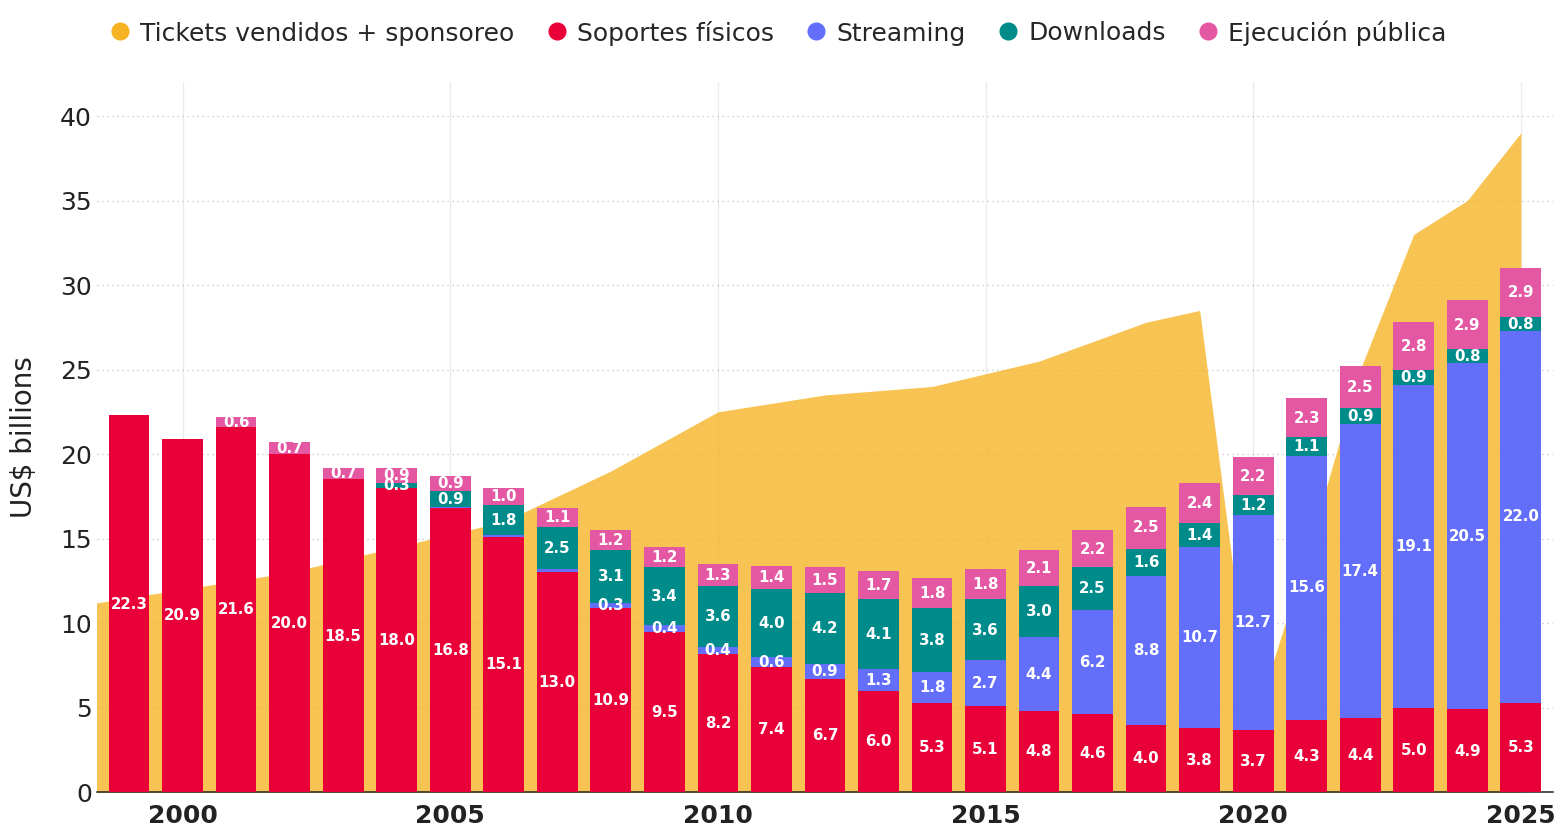

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\grafico_ifpi_live_combinado.png


In [158]:
# ============================================================
# Gráfico reporte | Música grabada + live music revenue 1999-2025
# Barras apiladas por formato + área de conciertos detrás
# Valores en US$ billions
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Directorio de salida
# ------------------------------------------------------------

directorio_graficos = Path(r"graficos")
directorio_graficos.mkdir(parents=True, exist_ok=True)

ruta_salida_png = directorio_graficos / "grafico_ifpi_live_combinado.png"

# ------------------------------------------------------------
# Parámetro de visualización
# ------------------------------------------------------------

incluir_synchronisation = False

# ------------------------------------------------------------
# Datos música grabada reconstruidos desde gráfico de referencia
# Valores en US$ billions
# ------------------------------------------------------------

datos_revenues = pd.DataFrame({
    "anio": list(range(1999, 2026)),

    "physical": [
        22.3, 20.9, 21.6, 20.0, 18.5, 18.0, 16.8, 15.1, 13.0,
        10.9, 9.5, 8.2, 7.4, 6.7, 6.0, 5.3, 5.1, 4.8,
        4.6, 4.0, 3.8, 3.7, 4.3, 4.4, 5.0, 4.9, 5.3
    ],

    "streaming": [
        0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.1, 0.2,
        0.3, 0.4, 0.4, 0.6, 0.9, 1.3, 1.8, 2.7, 4.4,
        6.2, 8.8, 10.7, 12.7, 15.6, 17.4, 19.1, 20.5, 22.0
    ],

    "downloads": [
        0.0, 0.0, 0.0, 0.0, 0.0, 0.3, 0.9, 1.8, 2.5,
        3.1, 3.4, 3.6, 4.0, 4.2, 4.1, 3.8, 3.6, 3.0,
        2.5, 1.6, 1.4, 1.2, 1.1, 0.9, 0.9, 0.8, 0.8
    ],

    "performance_rights": [
        0.0, 0.0, 0.6, 0.7, 0.7, 0.9, 0.9, 1.0, 1.1,
        1.2, 1.2, 1.3, 1.4, 1.5, 1.7, 1.8, 1.8, 2.1,
        2.2, 2.5, 2.4, 2.2, 2.3, 2.5, 2.8, 2.9, 2.9
    ],

    "synchronisation": [
        0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,
        0.0, 0.0, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3,
        0.4, 0.4, 0.4, 0.4, 0.5, 0.6, 0.6, 0.7, 0.6
    ],

    "total_grafico_ifpi": [
        22.3, 20.9, 22.1, 20.7, 19.2, 19.2, 18.7, 18.0, 16.9,
        15.5, 14.6, 13.8, 13.7, 13.7, 13.5, 13.1, 13.5, 14.8,
        15.9, 17.4, 18.7, 20.0, 23.7, 25.8, 28.4, 29.7, 31.7
    ]
})

# ------------------------------------------------------------
# Datos live music revenue reconstruidos desde gráfico de referencia
# Valores en US$ billions
# ------------------------------------------------------------

datos_live_revenue = pd.DataFrame({
    "anio": [
        1998, 2000, 2002, 2004, 2006, 2008, 2010, 2012,
        2014, 2016, 2018, 2019, 2020, 2021, 2022, 2023,
        2024, 2025
    ],
    "live_revenue_bn": [
        11.0, 12.0, 13.0, 14.5, 16.0, 19.0, 22.5, 23.5,
        24.0, 25.5, 27.8, 28.5, 4.0, 14.0, 25.0, 33.0,
        35.0, 39.0
    ]
})

# ------------------------------------------------------------
# Categorías visibles
# ------------------------------------------------------------

columnas_segmentos = [
    "physical",
    "streaming",
    "downloads",
    "performance_rights"
]

if incluir_synchronisation:
    columnas_segmentos.append("synchronisation")

datos_revenues["total_visible"] = datos_revenues[columnas_segmentos].sum(axis=1).round(1)

# ------------------------------------------------------------
# Sanity check de totales visibles
# ------------------------------------------------------------

datos_revenues["diferencia_vs_total_ifpi"] = (
    datos_revenues["total_visible"] - datos_revenues["total_grafico_ifpi"]
).round(2)

control_totales = datos_revenues[
    ["anio", "total_grafico_ifpi", "total_visible", "diferencia_vs_total_ifpi"]
].copy()

display(control_totales)

diferencia_maxima_abs = control_totales["diferencia_vs_total_ifpi"].abs().max()
print(f"Diferencia máxima absoluta entre total visible y total IFPI: {diferencia_maxima_abs:.2f} US$ billions")

display(datos_live_revenue)

# ------------------------------------------------------------
# Paleta y configuración visual
# ------------------------------------------------------------

paleta_formatos = {
    "live": "#222222",
    "physical": "#F28C28",
    "streaming": "#264C96", 
    "downloads": "#19B3A6",
    "performance_rights": "#D6409F",
    "synchronisation": "#FDB515"
}

etiquetas_formatos = {
    "live": "Tickets vendidos + sponsoreo",
    "physical": "Soportes físicos",
    "streaming": "Streaming",
    "downloads": "Downloads",
    "performance_rights": "Ejecución pública",
    "synchronisation": "Sincronización"
}

color_texto = "#222222"

# Paleta del gráfico de industria (no reutiliza colores con otro significado en la tesis):
# streaming usa el azul de la dimensión streaming y conciertos un gris derivado del negro
# de conciertos; físicos, downloads y ejecución pública usan tonos que la tesis no emplea.
color_relleno_live = "#DCDCDC"
color_borde_live = "#9A9A9A"

def color_etiqueta(color_hex):
    """Texto oscuro sobre segmentos claros y blanco sobre segmentos oscuros."""
    r, g, b = (int(color_hex[i:i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "#1A1A1A" if luminancia > 150 else "white"
color_grilla = "#BDBDBD"

plt.rcParams["font.family"] = "DejaVu Sans"

fig = plt.figure(figsize=(16, 10), facecolor="white")

# ------------------------------------------------------------
# Título comentado para que no imprima
# ------------------------------------------------------------

# fig.suptitle(
#     "Global music revenues, 1999-2025",
#     x=0.06,
#     y=0.965,
#     ha="left",
#     va="top",
#     fontsize=18,
#     fontweight="bold",
#     color=color_texto
# )

# ------------------------------------------------------------
# Leyenda superior
# ------------------------------------------------------------

elementos_leyenda = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_relleno_live,
        markeredgecolor=color_borde_live,
        markeredgewidth=1.6,
        markersize=12,
        label=etiquetas_formatos["live"]
    )
] + [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=paleta_formatos[columna],
        markeredgecolor=paleta_formatos[columna],
        markersize=12,
        label=etiquetas_formatos[columna]
    )
    for columna in columnas_segmentos
]

fig.legend(
    handles=elementos_leyenda,
    loc="upper left",
    bbox_to_anchor=(0.055, 0.945),
    ncol=len(elementos_leyenda),
    frameon=False,
    fontsize=18,
    handlelength=0.7,
    handletextpad=0.45,
    columnspacing=1.35
)

# ------------------------------------------------------------
# Área principal del gráfico
# ------------------------------------------------------------

ax = fig.add_axes([0.06, 0.15, 0.91, 0.71])
ax.set_facecolor("white")

# ------------------------------------------------------------
# Área de live music revenue detrás de las barras
# ------------------------------------------------------------

ax.fill_between(
    datos_live_revenue["anio"],
    datos_live_revenue["live_revenue_bn"],
    0,
    color=paleta_formatos["live"],
    alpha=0.14,
    linewidth=0,
    zorder=1
)

# Borde del área: por encima del relleno gris y por detrás de las barras
ax.plot(
    datos_live_revenue["anio"],
    datos_live_revenue["live_revenue_bn"],
    color=color_borde_live,
    linewidth=2.0,
    zorder=2
)

# ------------------------------------------------------------
# Barras apiladas de música grabada
# ------------------------------------------------------------

x = datos_revenues["anio"].to_numpy()
ancho_barra = 0.76
base_apilada = np.zeros(len(datos_revenues))

for columna in columnas_segmentos:
    valores = datos_revenues[columna].to_numpy()

    ax.bar(
        x,
        valores,
        width=ancho_barra,
        bottom=base_apilada,
        color=paleta_formatos[columna],
        linewidth=0,
        zorder=3
    )

    for i, valor in enumerate(valores):
        if valor >= 0.3:
            ax.text(
                x[i],
                base_apilada[i] + valor / 2,
                f"{valor:.1f}".replace(".", ","),
                ha="center",
                va="center",
                fontsize=10.8,
                fontweight="bold" if columna == "streaming" else "semibold",
                color=color_etiqueta(paleta_formatos[columna]),
                zorder=6
            )

    base_apilada += valores

# ------------------------------------------------------------
# Ejes, grilla y formato del área principal
# ------------------------------------------------------------

ax.set_xlim(1998.4, 2025.6)
ax.set_ylim(0, 42)

ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025])
ax.set_xticklabels(
    [2000, 2005, 2010, 2015, 2020, 2025],
    fontsize=18,
    fontweight="bold",
    color=color_texto
)

ax.set_yticks(np.arange(0, 45, 5))
ax.tick_params(axis="y", length=0, labelsize=18, colors=color_texto)

ax.grid(
    axis="y",
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    color=color_grilla,
    alpha=0.95,
    zorder=0
)

ax.set_axisbelow(True)

# for spine in ["top", "right", "left", "bottom"]:
#     ax.spines[spine].set_visible(False)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(color_texto)
ax.spines["bottom"].set_linewidth(1.1)

# ax.tick_params(axis="x", length=0)

ax.tick_params(
    axis="x",
    length=5,
    width=1,
    color=color_texto,
    labelsize=18,
    labelcolor=color_texto
)

ax.set_xlabel("")
ax.set_ylabel("Miles de millones de US$", fontsize=20, color=color_texto, labelpad=16)

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

plt.savefig(
    ruta_salida_png,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Gráfico guardado en: {ruta_salida_png}")

# Valores faltantes

In [ ]:
# ============================================================
# Tipos de datos y valores faltantes por dimensión
# ============================================================

rows = []

for group_name, cols in column_groups.items():
    for col in cols:
        rows.append({
            "dimension": group_name,
            "variable": col,
            "dtype": str(df[col].dtype),
            "non_null": df[col].notna().sum(),
            "n_null": df[col].isna().sum(),
            "pct_null": round(df[col].isna().mean() * 100, 2)
        })

eda_types = pd.DataFrame(rows)

eda_types

,dimension,variable,dtype,non_null,n_null,pct_null
0,identificacion,chartmetric_id,Int64,4913,0,0.00
1,identificacion,artist_name,str,4913,0,0.00
2,metadata,country,category,4909,4,0.08
3,metadata,country_short,category,4909,4,0.08
4,metadata,pronoun_title,category,4913,0,0.00
5,metadata,pronoun_short,category,4913,0,0.00
6,metadata,record_label,category,4604,309,6.29
7,metadata,major_record_label,boolean,4604,309,6.29
8,metadata,primary_genre,category,4913,0,0.00
9,metadata,genre_short,category,4913,0,0.00


In [ ]:
# ============================================================
# Variables con valores faltantes
# ============================================================

missing_vars = (
    eda_types
    .query("n_null > 0")
    .sort_values("pct_null", ascending=False)
    .reset_index(drop=True)
)

missing_vars

,dimension,variable,dtype,non_null,n_null,pct_null
0,youtube,youtube_daily_video_views,Int64,3401,1512,30.78
1,youtube,youtube_monthly_video_views,Int64,3401,1512,30.78
2,redes_sociales,tiktok_followers,Int64,3604,1309,26.64
3,redes_sociales,tiktok_likes,Int64,3604,1309,26.64
4,live_events,avg_venue_capacity_24_25,float64,3870,1043,21.23
5,redes_sociales,twitter_followers,Int64,3968,945,19.23
6,live_events,shows_per_country_24_25,float64,4025,888,18.07
7,redes_sociales,ins_followers,Int64,4580,333,6.78
8,metadata,record_label,category,4604,309,6.29
9,metadata,major_record_label,boolean,4604,309,6.29


# Cardinalidad de categóricas

In [ ]:
# ============================================================
# Cardinalidad de variables categóricas y booleanas
# ============================================================

cat_bool_cols = (
    eda_types
    .query("dtype in ['category', 'bool', 'boolean']")
    ["variable"]
    .tolist()
)

cardinality = []

for col in cat_bool_cols:
    cardinality.append({
        "variable": col,
        "dimension": eda_types.loc[eda_types["variable"] == col, "dimension"].iloc[0],
        "dtype": str(df[col].dtype),
        "n_unique_sin_na": df[col].nunique(dropna=True),
        "n_null": df[col].isna().sum(),
        "pct_null": round(df[col].isna().mean() * 100, 2)
    })

cardinality = (
    pd.DataFrame(cardinality)
    .sort_values("n_unique_sin_na", ascending=False)
    .reset_index(drop=True)
)

cardinality

,variable,dimension,dtype,n_unique_sin_na,n_null,pct_null
0,record_label,metadata,category,2429,309,6.29
1,primary_genre,metadata,category,284,0,0.00
2,country,metadata,category,87,4,0.08
3,genre_short,metadata,category,12,0,0.00
4,pronoun_title,metadata,category,11,0,0.00
5,country_short,metadata,category,6,4,0.08
6,pronoun_short,metadata,category,4,0,0.00
7,major_record_label,metadata,boolean,2,309,6.29
8,band,metadata,bool,2,0,0.00
9,muerto_disuelto,metadata,boolean,2,223,4.54


# Frecuencia de categóricas agrupadas

In [ ]:
# ============================================================
# Frecuencias de variables categóricas agrupadas
# ============================================================

cat_resumen_cols = [
    "country_short",
    "genre_short",
    "pronoun_short",
    "major_record_label",
    "band",
    "muerto_disuelto",
    "off_cycle"
]

for col in cat_resumen_cols:
    print("\n" + "=" * 60)
    print(col)
    print("=" * 60)
    
    resumen = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="n")
    )
    
    resumen["pct"] = (resumen["n"] / len(df) * 100).round(2)
    
    print(resumen)


country_short
    country_short     n    pct
0   North America  2248  45.76
1           LATAM   778  15.84
2    Europe_sinGB   749  15.25
3   Great Britain   578  11.76
4  Asia & Oceania   363   7.39
5     Africa & ME   193   3.93
6             NaN     4   0.08

genre_short
                  genre_short    n    pct
0                         Pop  944  19.21
1              Hip-hop & trap  658  13.39
2          Electronic & dance  642  13.07
3                Rock & metal  514  10.46
4               Latin & urban  480   9.77
5            R&b, soul & funk  375   7.63
6         Alternative & indie  349   7.10
7             Regional global  293   5.96
8              Country & folk  265   5.39
9           Regional mexicano  197   4.01
10  Jazz & blues & classical   138   2.81
11              Miscellaneous   58   1.18

pronoun_short
        pronoun_short     n    pct
0              he/him  2530  51.50
1           they/them  1492  30.37
2             she/her   879  17.89
3  Non-Binary/Diverse  

In [36]:
# ============================================================
# Control entre pronoun_short y band
# ============================================================

tabla_pronoun_band = pd.crosstab(
    df["pronoun_short"],
    df["band"],
    margins=True
)

tabla_pronoun_band_pct_fila = pd.crosstab(
    df["pronoun_short"],
    df["band"],
    normalize="index"
).round(3) * 100

print("Frecuencias absolutas:")
print(tabla_pronoun_band)

print("\nPorcentajes por fila:")
print(tabla_pronoun_band_pct_fila)

Frecuencias absolutas:
band                False  True   All
pronoun_short                        
Non-Binary/Diverse     11     1    12
he/him               2465    65  2530
she/her               856    23   879
they/them              11  1481  1492
All                  3343  1570  4913

Porcentajes por fila:
band                False  True 
pronoun_short                   
Non-Binary/Diverse   91.7    8.3
he/him               97.4    2.6
she/her              97.4    2.6
they/them             0.7   99.3


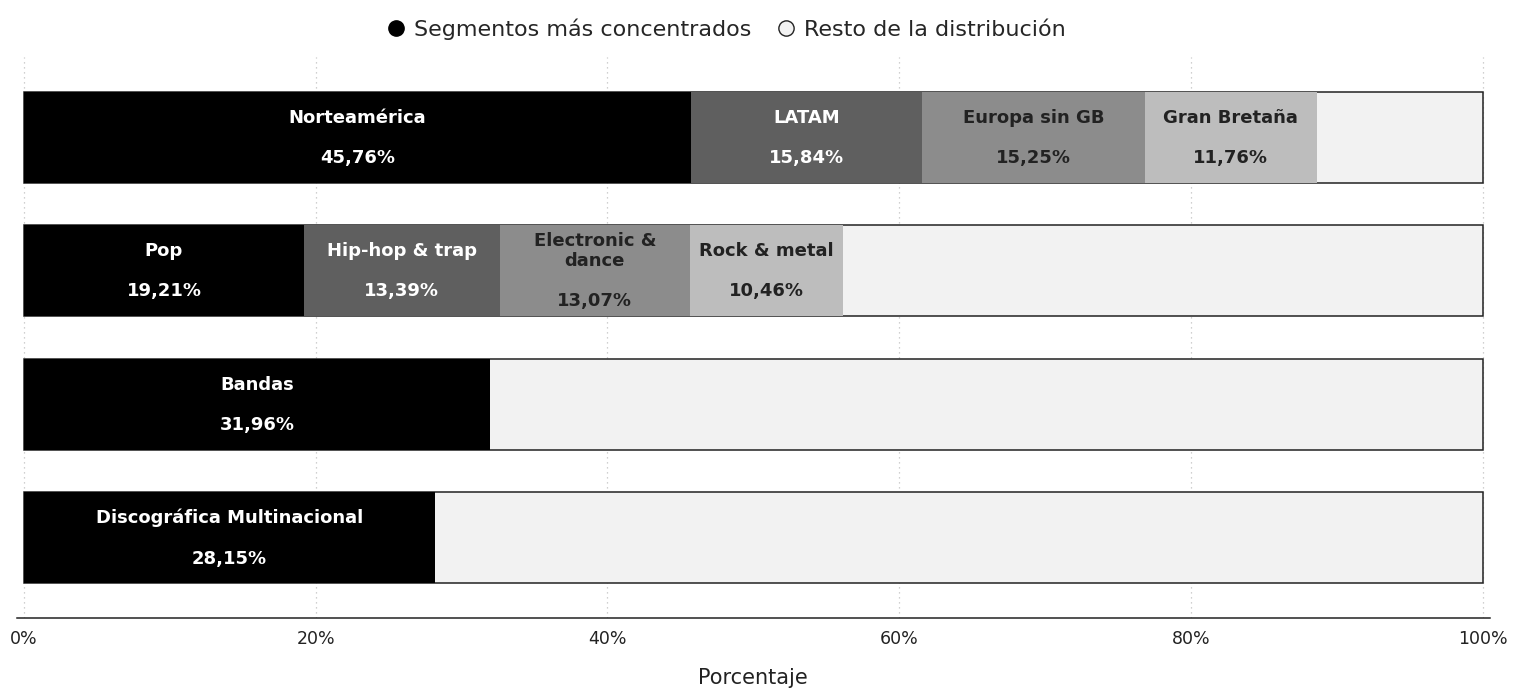

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\composicion_muestra_barras_concentracion.png


In [163]:
# ============================================================
# Composición de la muestra
# Barras totales con sub-bins destacados
# Basado en las celdas de frecuencias
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Estética
# ------------------------------------------------------------

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

color_gris_1 = "#D9D9D9"
color_gris_2 = "#BDBDBD"
color_gris_3 = "#8C8C8C"
color_gris_4 = "#5F5F5F"
color_gris_5 = "#000000"

color_resto = "#F2F2F2"
color_borde_resto = "#222222"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Helper porcentaje
# ------------------------------------------------------------

def fmt_pct(x):
    return f"{x:.2f}%".replace(".", ",")

# ------------------------------------------------------------
# Frecuencias categóricas
# ------------------------------------------------------------

def tabla_frecuencias(col):
    tabla = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="n")
    )
    tabla["pct"] = tabla["n"] / len(df) * 100
    return tabla

tabla_region = tabla_frecuencias("country_short")
tabla_genero = tabla_frecuencias("genre_short")
tabla_major = tabla_frecuencias("major_record_label")
tabla_band = tabla_frecuencias("band")

# ------------------------------------------------------------
# Extraer exactamente las cifras del párrafo
# ------------------------------------------------------------

# Región
region_map = {
    "North America": "Norteamérica",
    "LATAM": "LATAM",
    "Europe_sinGB": "Europa sin GB",
    "Great Britain": "Gran Bretaña"
}

segmentos_region = []
for cat in ["North America", "LATAM", "Europe_sinGB", "Great Britain"]:
    valor = tabla_region.loc[
        tabla_region["country_short"] == cat,
        "pct"
    ]
    if len(valor) > 0:
        segmentos_region.append((region_map[cat], float(valor.iloc[0])))

region_resto = 100 - sum(v for _, v in segmentos_region)

# Género
genero_map = {
    "Pop": "Pop",
    "Hip-hop & trap": "Hip-hop & trap",
    "Electronic & dance": "Electronic &\ndance",
    "Rock & metal": "Rock & metal"
}

segmentos_genero = []
for cat in ["Pop", "Hip-hop & trap", "Electronic & dance", "Rock & metal"]:
    valor = tabla_genero.loc[
        tabla_genero["genre_short"] == cat,
        "pct"
    ]
    if len(valor) > 0:
        segmentos_genero.append((genero_map[cat], float(valor.iloc[0])))

genero_resto = 100 - sum(v for _, v in segmentos_genero)

# Bandas
pct_bandas = float(
    tabla_band.loc[
        tabla_band["band"] == True,
        "pct"
    ].iloc[0]
)
bandas_resto = 100 - pct_bandas

# Major
pct_major = float(
    tabla_major.loc[
        tabla_major["major_record_label"] == True,
        "pct"
    ].iloc[0]
)
major_resto = 100 - pct_major

# ------------------------------------------------------------
# Estructura para graficar
# ------------------------------------------------------------

barras = [
    {
        "nombre": "Región de origen",
        "segmentos": segmentos_region,
        "resto": region_resto,
        "colores": [color_gris_5, color_gris_4, color_gris_3, color_gris_2]
    },
    {
        "nombre": "Género musical",
        "segmentos": segmentos_genero,
        "resto": genero_resto,
        "colores": [color_gris_5, color_gris_4, color_gris_3, color_gris_2]
    },
    {
        "nombre": "Formato del artista",
        "segmentos": [("Bandas", pct_bandas)],
        "resto": bandas_resto,
        "colores": [color_gris_5]
    },
    {
        "nombre": "Discográfica",
        "segmentos": [("Discográfica Multinacional", pct_major)],
        "resto": major_resto,
        "colores": [color_gris_5]
    }
]

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 7.4))
fig.patch.set_facecolor(color_fondo)
ax.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Título comentado para que no imprima
# ------------------------------------------------------------

# fig.suptitle(
#     "Composición de la muestra",
#     x=0.06,
#     y=0.98,
#     ha="left",
#     va="top",
#     fontsize=22,
#     fontweight="bold",
#     color=color_texto
# )

# ------------------------------------------------------------
# Dibujo de barras
# ------------------------------------------------------------

y_positions = np.arange(len(barras))[::-1]
alto_barra = 0.68

for y, barra in zip(y_positions, barras):

    # barra total
    ax.barh(
        y,
        100,
        height=alto_barra,
        color=color_resto,
        edgecolor=color_borde_resto,
        linewidth=1.1,
        zorder=1
    )

    acumulado = 0

    # segmentos destacados
    for (label, valor), color in zip(barra["segmentos"], barra["colores"]):
        ax.barh(
            y,
            valor,
            left=acumulado,
            height=alto_barra,
            color=color,
            edgecolor="none",
            zorder=2
        )

        texto_segmento = f"{label}\n\n{fmt_pct(valor)}"

        color_texto_segmento = "#FFFFFF" if color in [color_gris_5, color_gris_4] else "#222222"

        if valor >= 10:
            ax.text(
                acumulado + valor / 2,
                y,
                texto_segmento,
                ha="center",
                va="center",
                fontsize=13,
                color=color_texto_segmento,
                fontweight="bold",
                linespacing=1.15,
                zorder=3
            )
        else:
            ax.text(
                acumulado + valor + 1.2,
                y,
                texto_segmento,
                ha="left",
                va="center",
                fontsize=13,
                color=color_texto,
                fontweight="bold",
                linespacing=1.15,
                zorder=3
            )

        acumulado += valor

    # etiqueta izquierda (COMENTADA PARA OCULTAR SIN BORRAR EL NOMBRE)
    # ax.text(
    #     -2.5,
    #     y,
    #     barra["nombre"],
    #     ha="right",
    #     va="center",
    #     fontsize=13.5,
    #     color=color_texto,
    #     fontweight="bold"
    # )

# ------------------------------------------------------------
# Leyenda superior
# ------------------------------------------------------------

elementos_leyenda = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=color_gris_5,
        markeredgecolor=color_gris_5,
        markersize=11,
        label="Segmentos más concentrados"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=color_resto,
        markeredgecolor=color_borde_resto,
        markersize=11,
        label="Resto de la distribución"
    )
]

fig.legend(
    handles=elementos_leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),  # Centrado horizontalmente
    ncol=2,
    frameon=False,
    fontsize=16,
    handlelength=0.7,
    handletextpad=0.45,
    columnspacing=1.20
)

# ------------------------------------------------------------
# Ejes y estilo
# ------------------------------------------------------------

# Cambiado el límite de -18 a -0.5 para recentrar y aprovechar el espacio izquierdo
ax.set_xlim(-0.5, 100.5)
ax.set_ylim(-0.6, len(barras) - 0.4)

ax.set_yticks([])

ax.set_xlabel(
    "Porcentaje",
    fontsize=15,
    color=color_texto,
    labelpad=14
)

ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.xaxis.set_major_formatter(ticker.PercentFormatter(xmax=100, decimals=0))

ax.grid(
    axis="x",
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    color=color_grilla,
    alpha=0.95
)

ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(color_texto)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="x",
    length=5,
    width=1,
    color=color_texto,
    labelsize=12.5,
    labelcolor=color_texto
)

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

plt.tight_layout(rect=[0.04, 0.03, 1, 0.93])

ruta_figura_composicion = (
    directorio_salidas_proyecto /
    "composicion_muestra_barras_concentracion.png"
)

plt.savefig(
    ruta_figura_composicion,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_figura_composicion}")

# Análisis de la target

In [ ]:
# ============================================================
# Estadísticos descriptivos de la target
# ============================================================

target = "n_shows_24_25"

df[target].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count       4913.0
mean     24.299003
std      29.668945
min            0.0
25%            1.0
50%           13.0
75%           38.0
90%           68.0
95%           86.0
99%          124.0
max          179.0
Name: n_shows_24_25, dtype: Float64

In [ ]:
# ============================================================
# Cantidad y proporción de artistas con cero shows
# ============================================================

n_zero_shows = (df["n_shows_24_25"] == 0).sum()
pct_zero_shows = round(n_zero_shows / len(df) * 100, 2)

print("Artistas con 0 shows:", n_zero_shows)
print("Porcentaje con 0 shows:", pct_zero_shows)

Artistas con 0 shows: 860
Porcentaje con 0 shows: 17.5


In [ ]:
# ============================================================
# Composición de los ceros en la target
# ============================================================

zero_composition = (
    df.loc[df["n_shows_24_25"] == 0]
    .agg(
        total_ceros=("chartmetric_id", "count"),
        muerto_disuelto_true=("muerto_disuelto", lambda x: (x == True).sum()),
        off_cycle_true=("off_cycle", lambda x: (x == True).sum())
    )
)

zero_composition

,chartmetric_id,muerto_disuelto,off_cycle
total_ceros,860.0,NaN,NaN
muerto_disuelto_true,NaN,637.0,NaN
off_cycle_true,NaN,NaN,223.0


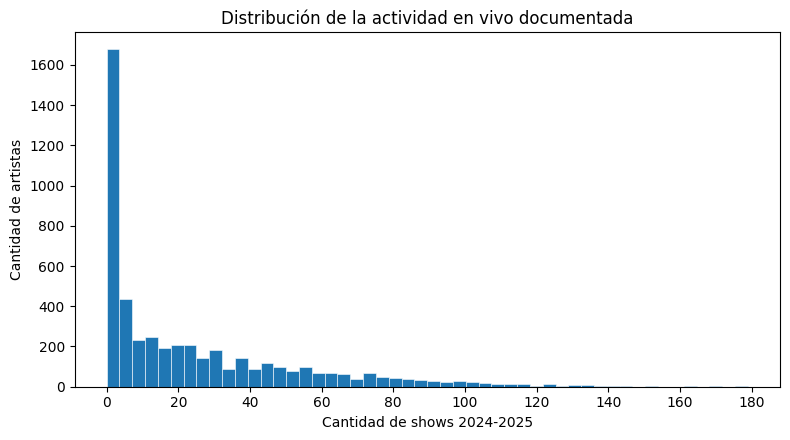

In [ ]:
# ============================================================
# Distribución de la variable target
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

target = "n_shows_24_25"

fig, ax = plt.subplots(figsize=(8, 4.5))

ax.hist(
    df[target],
    bins=50,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Distribución de la actividad en vivo documentada")
ax.set_xlabel("Cantidad de shows 2024-2025")
ax.set_ylabel("Cantidad de artistas")

ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# Distribución de la target: ceros y actividad positiva
# ============================================================

target_activity = pd.DataFrame({
    "grupo": [
        "0 shows",
        "> 0 shows"
    ],
    "n_artistas": [
        (df["n_shows_24_25"] == 0).sum(),
        (df["n_shows_24_25"] > 0).sum()
    ]
})

target_activity["pct"] = (
    target_activity["n_artistas"] / len(df) * 100
).round(2)

target_activity

,grupo,n_artistas,pct
0,0 shows,860,17.5
1,> 0 shows,4053,82.5


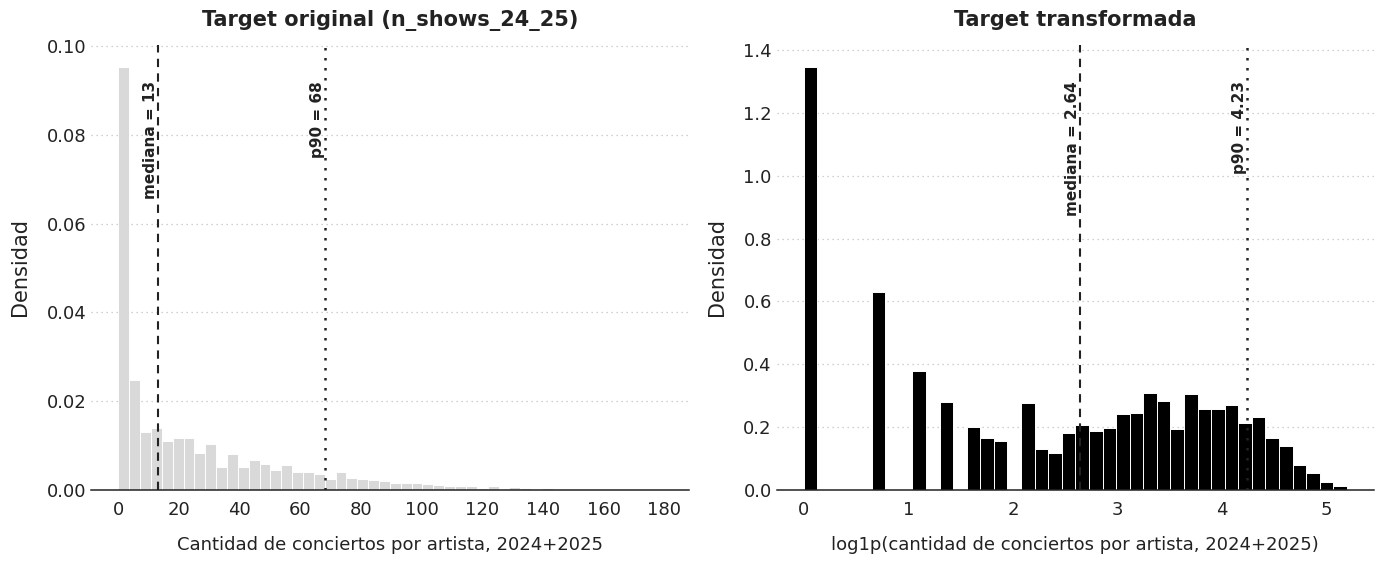

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\distribucion_target_original_transformada.png


In [155]:
# ============================================================
# Panel exploratorio de la variable target n_shows_24_25
# Target original y target transformada
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# KDE comentada porque no se visualiza en esta versión
# ------------------------------------------------------------

# try:
#     from scipy.stats import gaussian_kde
#     kde_disponible = True
# except Exception:
#     kde_disponible = False

target = "n_shows_24_25"

# ------------------------------------------------------------
# Paleta y estilo general
# ------------------------------------------------------------

color_original = "#D9D9D9"
color_transformada = "#000000"
color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"
color_linea = "#222222"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Datos
# ------------------------------------------------------------

s_all = df[target].astype(float)
s_pos = s_all[s_all > 0]

n_total = len(s_all)
n_zero = (s_all == 0).sum()
pct_zero = n_zero / n_total * 100

median_all = s_all.median()
mean_all = s_all.mean()
p90_all = s_all.quantile(0.90)

median_pos = s_pos.median()
mean_pos = s_pos.mean()
p90_pos = s_pos.quantile(0.90)

log_all = np.log1p(s_all)
log_pos = np.log1p(s_pos)

median_log = np.log1p(median_all)
p90_log = np.log1p(p90_all)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
fig.patch.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Título y subtítulo comentados para que no impriman
# ------------------------------------------------------------

# fig.suptitle(
#     "Distribución de target: n_shows_24_25",
#     fontsize=16,
#     fontweight="bold",
#     y=1.04,
#     color=color_texto
# )
#
# fig.text(
#     0.5,
#     0.96,
#     f"{n_zero} artistas registran 0 shows ({pct_zero:.1f}% de la muestra)",
#     ha="center",
#     fontsize=11,
#     color=color_texto
# )

# ------------------------------------------------------------
# 1. Target original
# ------------------------------------------------------------

ax = axes[0]
ax.set_facecolor(color_fondo)

ax.hist(
    s_all,
    bins=50,
    density=True,
    alpha=1.0,
    color=color_original,
    edgecolor="white",
    linewidth=0.7
)

# ------------------------------------------------------------
# Curvas KDE comentadas
# ------------------------------------------------------------

# if kde_disponible:
#     x_grid_all = np.linspace(s_all.min(), s_all.max(), 500)
#     kde_all = gaussian_kde(s_all)
#     ax.plot(
#         x_grid_all,
#         kde_all(x_grid_all),
#         linewidth=2
#     )
#
#     x_grid_pos = np.linspace(s_pos.min(), s_pos.max(), 500)
#     kde_pos = gaussian_kde(s_pos)
#     ax.plot(
#         x_grid_pos,
#         kde_pos(x_grid_pos),
#         linewidth=2,
#         linestyle="--"
#     )

ax.axvline(
    median_all,
    linestyle=(0, (4, 3)),
    linewidth=1.5,
    color=color_linea
)

ax.axvline(
    p90_all,
    linestyle=(0, (1, 3)),
    linewidth=1.8,
    color=color_linea
)

ylim_original = ax.get_ylim()

ax.text(
    median_all,
    ylim_original[1] * 0.92,
    f"mediana = {median_all:.0f}",
    ha="right",
    va="top",
    rotation=90,
    fontsize=11,
    fontweight="bold",
    color=color_texto
)

ax.text(
    p90_all,
    ylim_original[1] * 0.92,
    f"p90 = {p90_all:.0f}",
    ha="right",
    va="top",
    rotation=90,
    fontsize=11,
    fontweight="bold",
    color=color_texto
)

ax.set_title(
    "Target original (n_shows_24_25)",
    fontsize=15,
    fontweight="bold",
    color=color_texto,
    pad=14
)

ax.set_xlabel(
    "Cantidad de conciertos por artista, 2024+2025",
    fontsize=13,
    color=color_texto,
    labelpad=12
)

ax.set_ylabel(
    "Densidad",
    fontsize=15,
    color=color_texto,
    labelpad=12
)

ax.xaxis.set_major_locator(ticker.MaxNLocator(integer=True))

# ------------------------------------------------------------
# Recuadro anterior comentado
# Media y máximo ocultos
# ------------------------------------------------------------

# ax.text(
#     0.98,
#     0.92,
#     f"media = {mean_all:.1f}\nmediana = {median_all:.0f}\np90 = {p90_all:.0f}\nmáx. = {s_all.max():.0f}",
#     transform=ax.transAxes,
#     ha="right",
#     va="top",
#     fontsize=10,
#     bbox=dict(boxstyle="round,pad=0.3", alpha=0.12)
# )

# ------------------------------------------------------------
# 2. Target transformada con log1p
# ------------------------------------------------------------

ax = axes[1]
ax.set_facecolor(color_fondo)

ax.hist(
    log_all,
    bins=40,
    density=True,
    alpha=1.0,
    color=color_transformada,
    edgecolor="white",
    linewidth=0.7
)

# ------------------------------------------------------------
# Curvas KDE comentadas
# ------------------------------------------------------------

# if kde_disponible:
#     x_grid_all = np.linspace(log_all.min(), log_all.max(), 500)
#     kde_all = gaussian_kde(log_all)
#     ax.plot(
#         x_grid_all,
#         kde_all(x_grid_all),
#         linewidth=2
#     )
#
#     x_grid_pos = np.linspace(log_pos.min(), log_pos.max(), 500)
#     kde_pos = gaussian_kde(log_pos)
#     ax.plot(
#         x_grid_pos,
#         kde_pos(x_grid_pos),
#         linewidth=2,
#         linestyle="--"
#     )

ax.axvline(
    median_log,
    linestyle=(0, (4, 3)),
    linewidth=1.5,
    color=color_linea
)

ax.axvline(
    p90_log,
    linestyle=(0, (1, 3)),
    linewidth=1.8,
    color=color_linea
)

ylim_log = ax.get_ylim()

ax.text(
    median_log,
    ylim_log[1] * 0.92,
    f"mediana = {median_log:.2f}",
    ha="right",
    va="top",
    rotation=90,
    fontsize=11,
    fontweight="bold",
    color=color_texto
)

ax.text(
    p90_log,
    ylim_log[1] * 0.92,
    f"p90 = {p90_log:.2f}",
    ha="right",
    va="top",
    rotation=90,
    fontsize=11,
    fontweight="bold",
    color=color_texto
)

ax.set_title(
    "Target transformada",
    fontsize=15,
    fontweight="bold",
    color=color_texto,
    pad=14
)

ax.set_xlabel(
    "log1p(cantidad de conciertos por artista, 2024+2025)",
    fontsize=13,
    color=color_texto,
    labelpad=12
)

ax.set_ylabel(
    "Densidad",
    fontsize=15,
    color=color_texto,
    labelpad=12
)

# ------------------------------------------------------------
# Recuadro anterior comentado
# ------------------------------------------------------------

# ax.text(
#     0.98,
#     0.92,
#     f"log1p mediana = {np.log1p(median_all):.2f}\nlog1p p90 = {np.log1p(p90_all):.2f}",
#     transform=ax.transAxes,
#     ha="right",
#     va="top",
#     fontsize=10,
#     bbox=dict(boxstyle="round,pad=0.3", alpha=0.12)
# )

# ------------------------------------------------------------
# Ajustes generales
# ------------------------------------------------------------

for ax in axes:

    ax.grid(
        axis="y",
        linestyle=(0, (1, 3)),
        linewidth=0.9,
        color=color_grilla,
        alpha=0.95
    )

    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color(color_texto)
    ax.spines["bottom"].set_linewidth(1.1)

    ax.tick_params(
        axis="x",
        length=5,
        width=1,
        color=color_texto,
        labelsize=13,
        labelcolor=color_texto
    )

    ax.tick_params(
        axis="y",
        length=0,
        labelsize=13,
        colors=color_texto
    )

# ------------------------------------------------------------
# Leyendas comentadas
# ------------------------------------------------------------

# ax.legend(frameon=False)
#
# ax.legend(
#     frameon=False,
#     loc="upper left",
#     bbox_to_anchor=(0.12, 1.00)
# )

plt.tight_layout()

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

ruta_grafico_target_distribucion = (
    directorio_salidas_proyecto /
    "distribucion_target_original_transformada.png"
)

plt.savefig(
    ruta_grafico_target_distribucion,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_grafico_target_distribucion}")

## Curva de Lorenz

Artistas con actividad positiva: 4053
Umbral top 20%: 52.0
Artistas en top 20%: 838
Porcentaje de artistas: 20.68
Porcentaje de shows concentrados: 55.22
Gini: 0.536


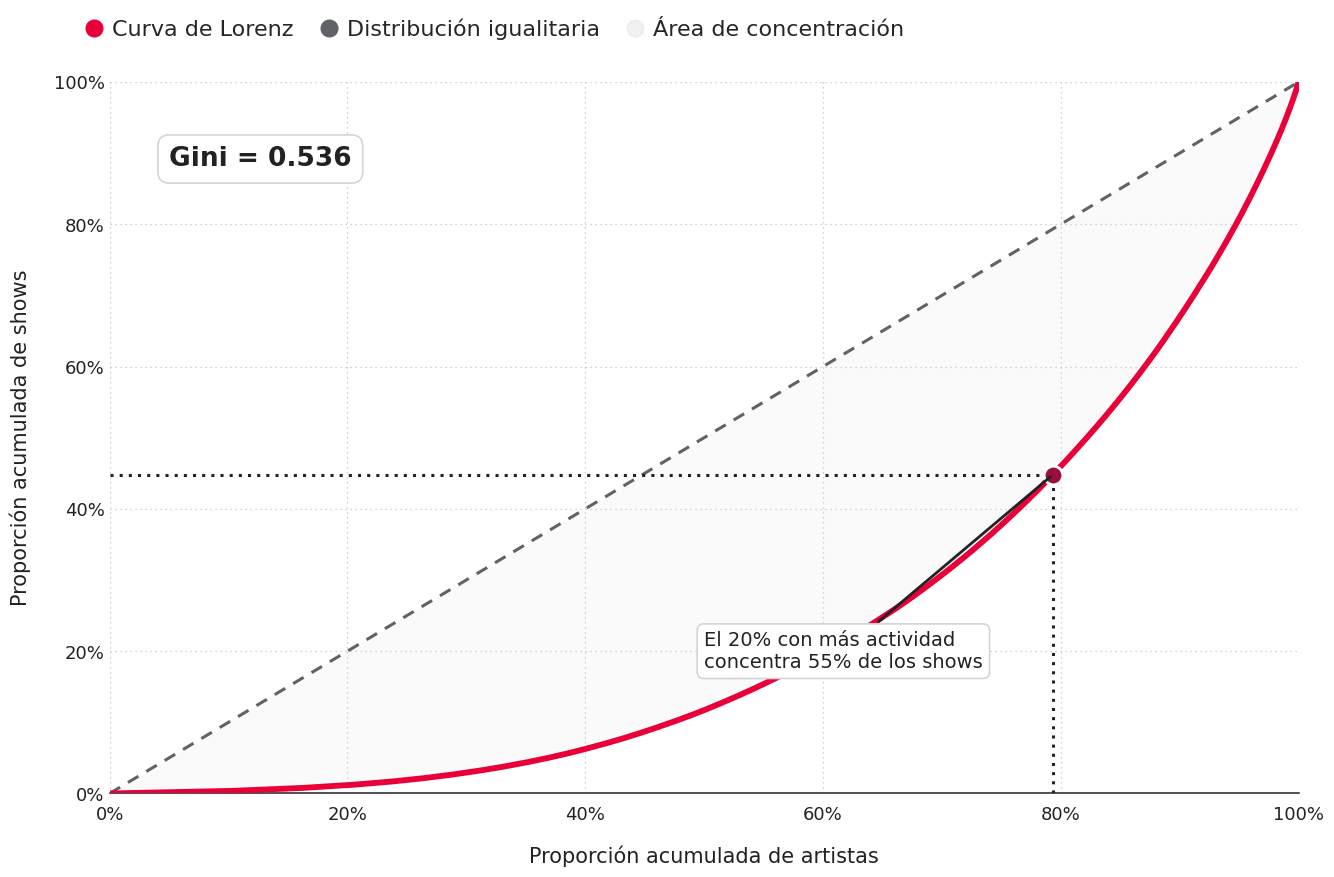

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\curva_lorenz_n_shows_24_25_artistas_positivos.png


In [152]:
# ============================================================
# Curva de Lorenz para concentración de shows
# Artistas con actividad positiva en 2024-2025
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from pathlib import Path

# ------------------------------------------------------------
# Parámetros
# ------------------------------------------------------------

target = "n_shows_24_25"

color_rojo = "#E90038"
color_rojo_oscuro = "#9B0F3F"
color_gris = "#D9D9D9"
color_grilla = "#BDBDBD"
color_texto = "#222222"
color_fondo = "#FFFFFF"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Datos positivos
# ------------------------------------------------------------

s_pos = df.loc[df[target] > 0, target].astype(float)

valores_ordenados = np.sort(s_pos.to_numpy())
n_artistas_positivos = len(valores_ordenados)

shows_acumulados = np.cumsum(valores_ordenados)
shows_total_pos = shows_acumulados[-1]

proporcion_acumulada_artistas = np.arange(1, n_artistas_positivos + 1) / n_artistas_positivos
proporcion_acumulada_shows = shows_acumulados / shows_total_pos

proporcion_acumulada_artistas = np.insert(proporcion_acumulada_artistas, 0, 0)
proporcion_acumulada_shows = np.insert(proporcion_acumulada_shows, 0, 0)

# ------------------------------------------------------------
# Métricas de concentración
# ------------------------------------------------------------

area_bajo_lorenz = np.trapezoid(
    proporcion_acumulada_shows,
    proporcion_acumulada_artistas
)

gini_shows = 1 - 2 * area_bajo_lorenz

umbral_top_20 = s_pos.quantile(0.80)

shows_top_20 = s_pos[s_pos >= umbral_top_20].sum()
shows_total_pos = s_pos.sum()

pct_shows_top_20 = shows_top_20 / shows_total_pos * 100
n_artistas_top_20 = (s_pos >= umbral_top_20).sum()
pct_artistas_top_20 = n_artistas_top_20 / len(s_pos) * 100

#proporcion_artistas_base_top_20 = 0.80
#proporcion_shows_base_top_20 = 1 - (pct_shows_top_20 / 100)

proporcion_artistas_base_top_20 = 1 - (pct_artistas_top_20 / 100)
proporcion_shows_base_top_20 = 1 - (pct_shows_top_20 / 100)

print("Artistas con actividad positiva:", n_artistas_positivos)
print("Umbral top 20%:", umbral_top_20)
print("Artistas en top 20%:", n_artistas_top_20)
print("Porcentaje de artistas:", round(pct_artistas_top_20, 2))
print("Porcentaje de shows concentrados:", round(pct_shows_top_20, 2))
print("Gini:", round(gini_shows, 3))

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(13.5, 9))
fig.patch.set_facecolor(color_fondo)
ax.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Título y subtítulo comentados para que no impriman
# ------------------------------------------------------------

# fig.suptitle(
#     "Concentración de shows entre artistas con actividad positiva",
#     x=0.06,
#     y=0.98,
#     ha="left",
#     va="top",
#     fontsize=24,
#     fontweight="bold",
#     color=color_texto
# )
#
# fig.text(
#     0.06,
#     0.925,
#     f"Curva de Lorenz sobre {n_artistas_positivos:,} artistas con al menos un show en 2024-2025",
#     ha="left",
#     va="top",
#     fontsize=14,
#     color="#555555"
# )

# ------------------------------------------------------------
# Área de concentración
# ------------------------------------------------------------

ax.fill_between(
    proporcion_acumulada_artistas,
    proporcion_acumulada_shows,
    proporcion_acumulada_artistas,
    color=color_gris,
    alpha=0.12,
    linewidth=0,
    zorder=1
)

# ------------------------------------------------------------
# Línea de distribución igualitaria
# ------------------------------------------------------------

ax.plot(
    [0, 1],
    [0, 1],
    linestyle=(0, (4, 3)),
    linewidth=2.2,
    color="#5F6368",
    zorder=2
)

# ------------------------------------------------------------
# Curva de Lorenz
# ------------------------------------------------------------

ax.plot(
    proporcion_acumulada_artistas,
    proporcion_acumulada_shows,
    color=color_rojo,
    linewidth=4.2,
    solid_capstyle="round",
    zorder=3
)

# ------------------------------------------------------------
# Guías para top 20%
# ------------------------------------------------------------

ax.plot(
    [proporcion_artistas_base_top_20, proporcion_artistas_base_top_20],
    [0, proporcion_shows_base_top_20],
    linestyle=(0, (1, 2)),
    linewidth=2.2,
    color=color_texto,
    zorder=2
)

ax.plot(
    [0, proporcion_artistas_base_top_20],
    [proporcion_shows_base_top_20, proporcion_shows_base_top_20],
    linestyle=(0, (1, 2)),
    linewidth=2.2,
    color=color_texto,
    zorder=2
)

ax.scatter(
    proporcion_artistas_base_top_20,
    proporcion_shows_base_top_20,
    s=180,
    color=color_rojo_oscuro,
    edgecolor="white",
    linewidth=2,
    zorder=4
)

# ------------------------------------------------------------
# Etiquetas internas
# ------------------------------------------------------------

ax.text(
    0.05,
    0.91,
    f"Gini = {gini_shows:.3f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=19,
    fontweight="bold",
    color=color_texto,
    bbox=dict(
        boxstyle="round,pad=0.42",
        facecolor=color_fondo,
        edgecolor="#D0D5DD",
        linewidth=1.2
    )
)

ax.annotate(
    f"El 20% con más actividad\nconcentra {pct_shows_top_20:.0f}% de los shows",
    xy=(proporcion_artistas_base_top_20, proporcion_shows_base_top_20),
    xytext=(0.50, 0.20),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=14,
    color=color_texto,
    arrowprops=dict(
        arrowstyle="-",
        color=color_texto,
        linewidth=2.0
    ),
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor=color_fondo,
        edgecolor="#D0D5DD",
        linewidth=1.2
    ),
    zorder=5
)

# ------------------------------------------------------------
# Leyenda superior
# ------------------------------------------------------------

elementos_leyenda = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_rojo,
        markeredgecolor=color_rojo,
        markersize=12,
        label="Curva de Lorenz"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#5F6368",
        markeredgecolor="#5F6368",
        markersize=12,
        label="Distribución igualitaria"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_gris,
        markeredgecolor=color_gris,
        alpha=0.35,
        markersize=12,
        label="Área de concentración"
    )
]

fig.legend(
    handles=elementos_leyenda,
    loc="upper left",
    bbox_to_anchor=(0.055, 0.985),
    ncol=3,
    frameon=False,
    fontsize=16,
    handlelength=0.7,
    handletextpad=0.45,
    columnspacing=1.25
)

# ------------------------------------------------------------
# Ejes
# ------------------------------------------------------------

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel(
    "Proporción acumulada de artistas",
    fontsize=15,
    color=color_texto,
    labelpad=16
)

ax.set_ylabel(
    "Proporción acumulada de shows",
    fontsize=15,
    color=color_texto,
    labelpad=16
)

ax.xaxis.set_major_locator(ticker.MultipleLocator(0.20))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.20))

ax.xaxis.set_major_formatter(
    ticker.PercentFormatter(xmax=1, decimals=0)
)

ax.yaxis.set_major_formatter(
    ticker.PercentFormatter(xmax=1, decimals=0)
)

ax.grid(
    axis="both",
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    color=color_grilla,
    alpha=0.95
)

ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(color_texto)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="x",
    length=5,
    width=1,
    color=color_texto,
    labelsize=13,
    labelcolor=color_texto
)

ax.tick_params(
    axis="y",
    length=0,
    labelsize=13,
    colors=color_texto
)

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

plt.tight_layout(rect=[0, 0, 1, 0.92])

ruta_grafico_lorenz_shows = (
    directorio_salidas_proyecto /
    "curva_lorenz_n_shows_24_25_artistas_positivos.png"
)

plt.savefig(
    ruta_grafico_lorenz_shows,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_grafico_lorenz_shows}")

# Distribuciones

In [ ]:
# ============================================================
# Subconjuntos de variables para EDA y modelado
# ============================================================

id_vars = [
    "chartmetric_id",
    "artist_name"
]

# ============================================================
# Metadata para EDA descriptivo y gráfico
# ============================================================

metadata_eda_vars = [
    "country_short",
    "genre_short",
    "pronoun_short",
    "band",
    "major_record_label"
]

# ============================================================
# Metadata de alta cardinalidad conservada para modelado posterior
# ============================================================

metadata_high_cardinality_vars = [
    "record_label",
    "country",
    "primary_genre",
    "pronoun_title"
]

digital_numeric_vars = (
    streaming_cols
    + playlist_cols
    + social_cols
    + youtube_cols
)

live_target_vars = [
    "n_shows_24_25"
]

live_aux_vars = [
    "n_shows_with_capacity_24_25",
    "capacity_24_25",
    "avg_venue_capacity_24_25",
    "n_cities_24_25",
    "n_countries_24_25",
    "shows_per_country_24_25",
    "off_cycle",
    "muerto_disuelto"
]

vars_excluir_predictoras = (
    id_vars
    + live_target_vars
    + live_aux_vars
)


In [57]:
# ============================================================
# Verificación de clasificación de todas las variables
# ============================================================

subconjuntos = {
    "Identificación": id_vars,
    "Metadata EDA": metadata_eda_vars,
    "Metadata alta cardinalidad": metadata_high_cardinality_vars,
    "Variables digitales numéricas": digital_numeric_vars,
    "Target": live_target_vars,
    "Live auxiliares/derivadas": live_aux_vars
}

# Contar cuántas variables totales
total_vars = sum(len(v) for v in subconjuntos.values())
print(f"Total de variables clasificadas: {total_vars}")
print(f"Columnas en df: {df.shape[1]}\n")

# Resumen por bloque
for name, cols in subconjuntos.items():
    print(f"{name}: {len(cols)} variables")

# Verificación de que no quedó ninguna columna sin clasificar
clasificadas = [col for cols in subconjuntos.values() for col in cols]
no_clasificadas = sorted(set(df.columns) - set(clasificadas))
if no_clasificadas:
    print("\nColumnas no clasificadas:", no_clasificadas)
else:
    print("\nTodas las columnas han sido clasificadas correctamente.")

Total de variables clasificadas: 53
Columnas en df: 53

Identificación: 2 variables
Metadata EDA: 5 variables
Metadata alta cardinalidad: 4 variables
Variables digitales numéricas: 33 variables
Target: 1 variables
Live auxiliares/derivadas: 8 variables

Todas las columnas han sido clasificadas correctamente.


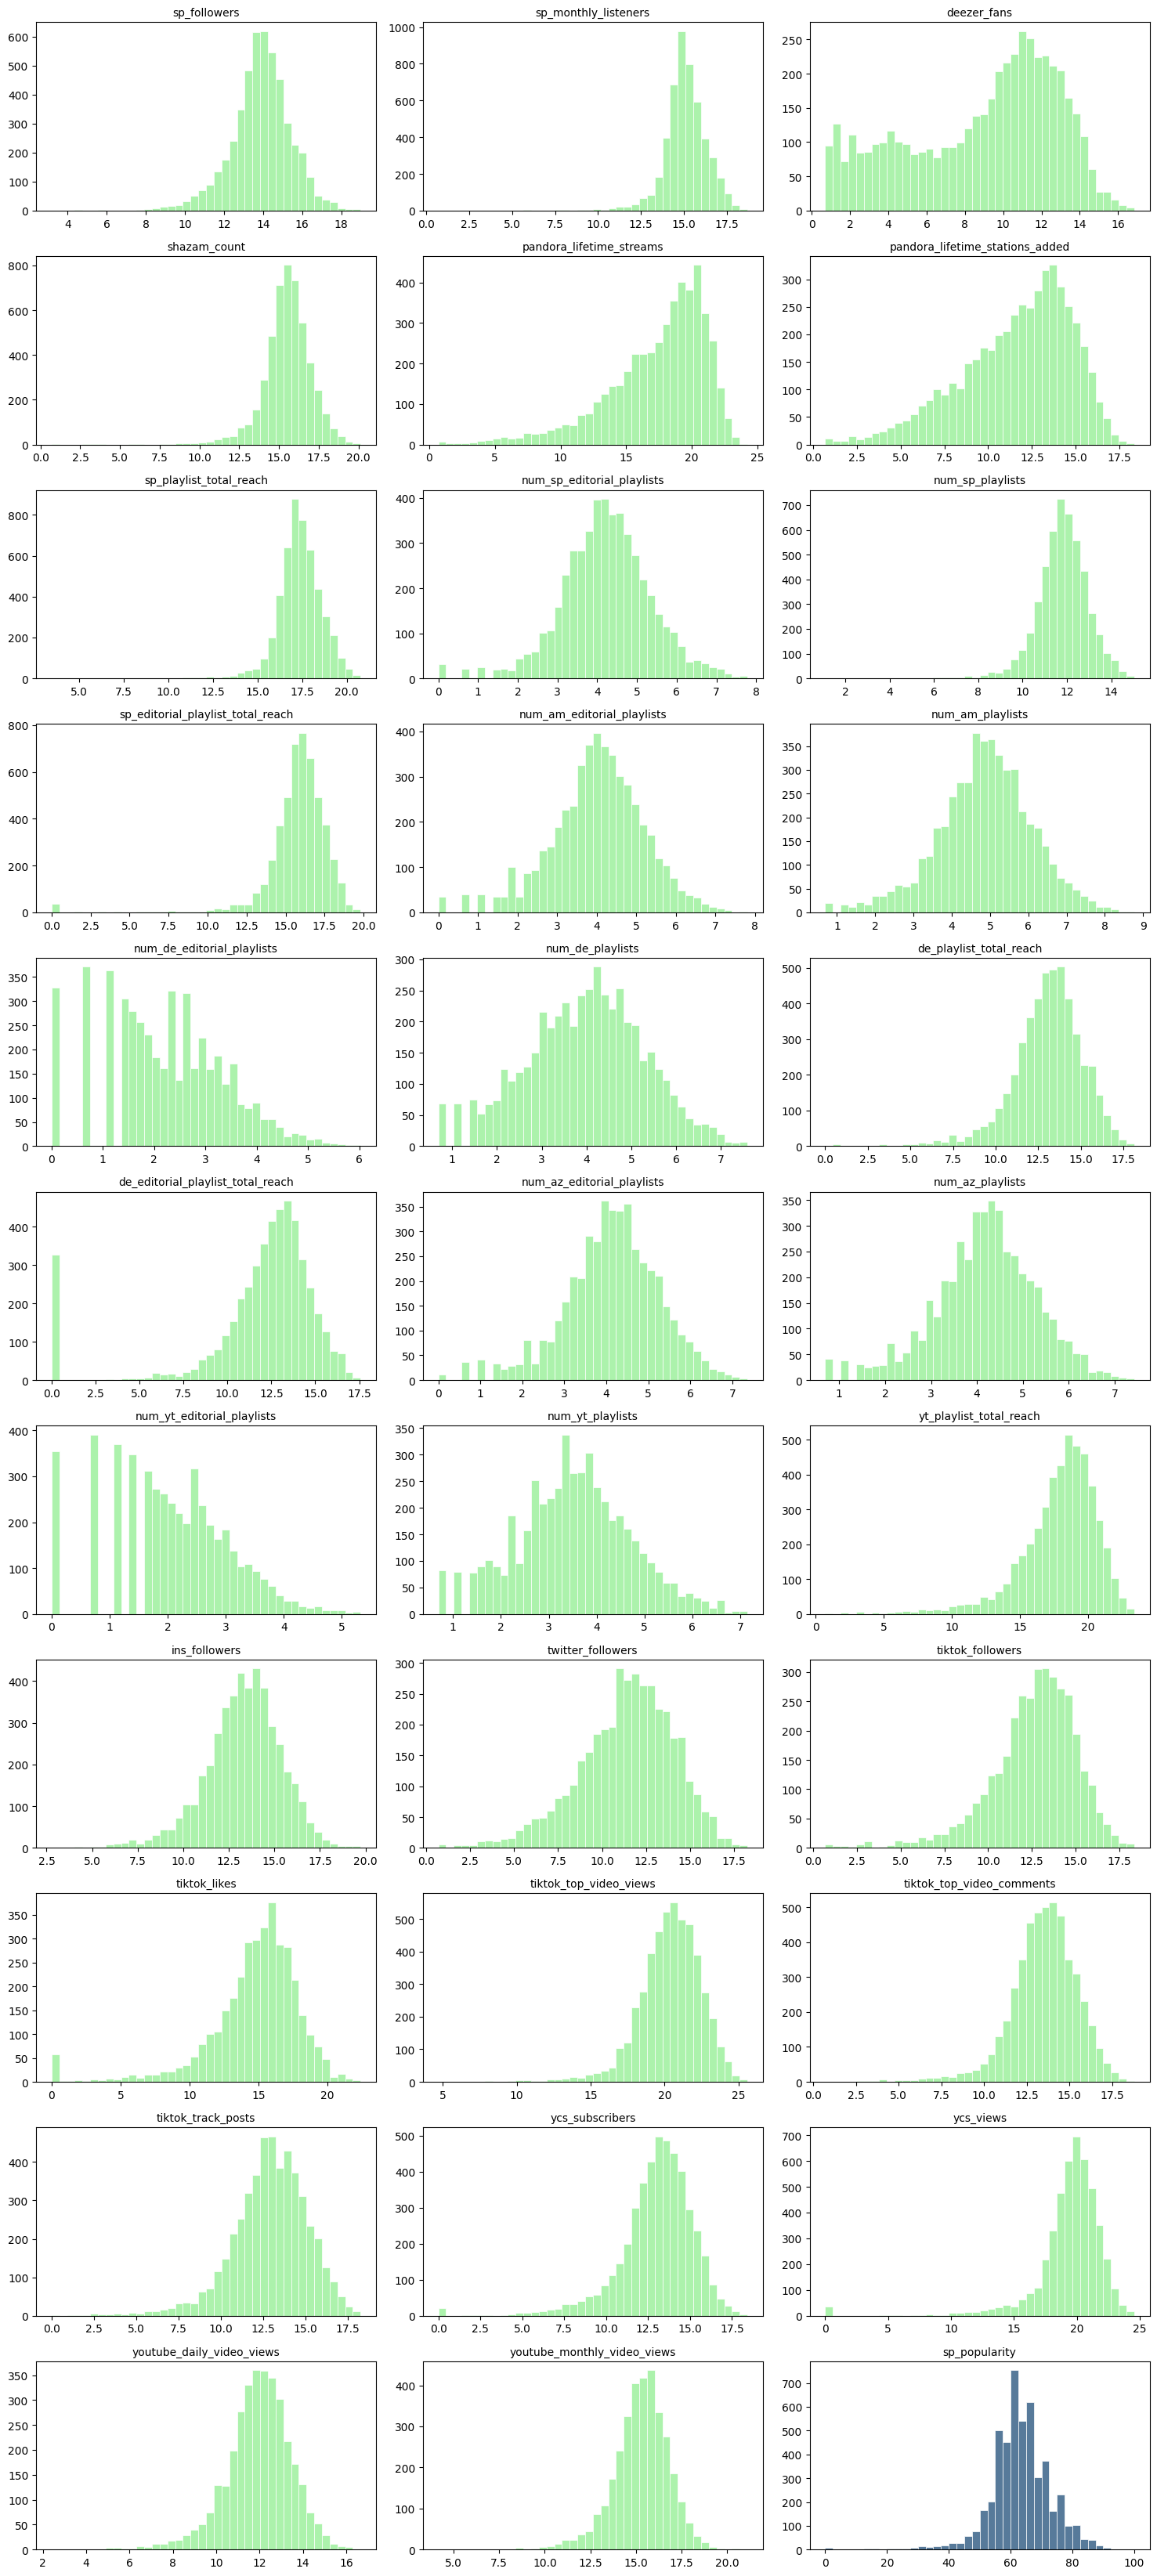

In [59]:
# ============================================================
# Panel de histogramas con log1p (verde claro) y sp_popularity en azul
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Variables a graficar
num_vars = digital_numeric_vars  # todas las variables numéricas
num_vars_plot = num_vars.copy()
# sp_popularity al final para aplicarle color azul
num_vars_plot.remove("sp_popularity")
num_vars_plot.append("sp_popularity")

n_cols = 3
n_rows = int(np.ceil(len(num_vars_plot) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(num_vars_plot):
    ax = axes[i]
    s = df[col].dropna().astype(float)
    
    # Aplicar log1p a todas menos sp_popularity
    if col != "sp_popularity":
        s_plot = np.log1p(s)
        color = "#90EE90"  # verde claro
    else:
        s_plot = s
        color = "#1F4E79"  # azul original
    
    sns.histplot(
        s_plot,
        bins=40,
        ax=ax,
        color=color,
        edgecolor="white",
        linewidth=0.5
    )
    
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Eliminar ejes vacíos si sobran
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

ruta_variables_log = (
    directorio_salidas_proyecto /
    "histogramas_log.png"
)

plt.savefig(
    ruta_variables_log,
    dpi=300,
    bbox_inches="tight"
)


plt.show()

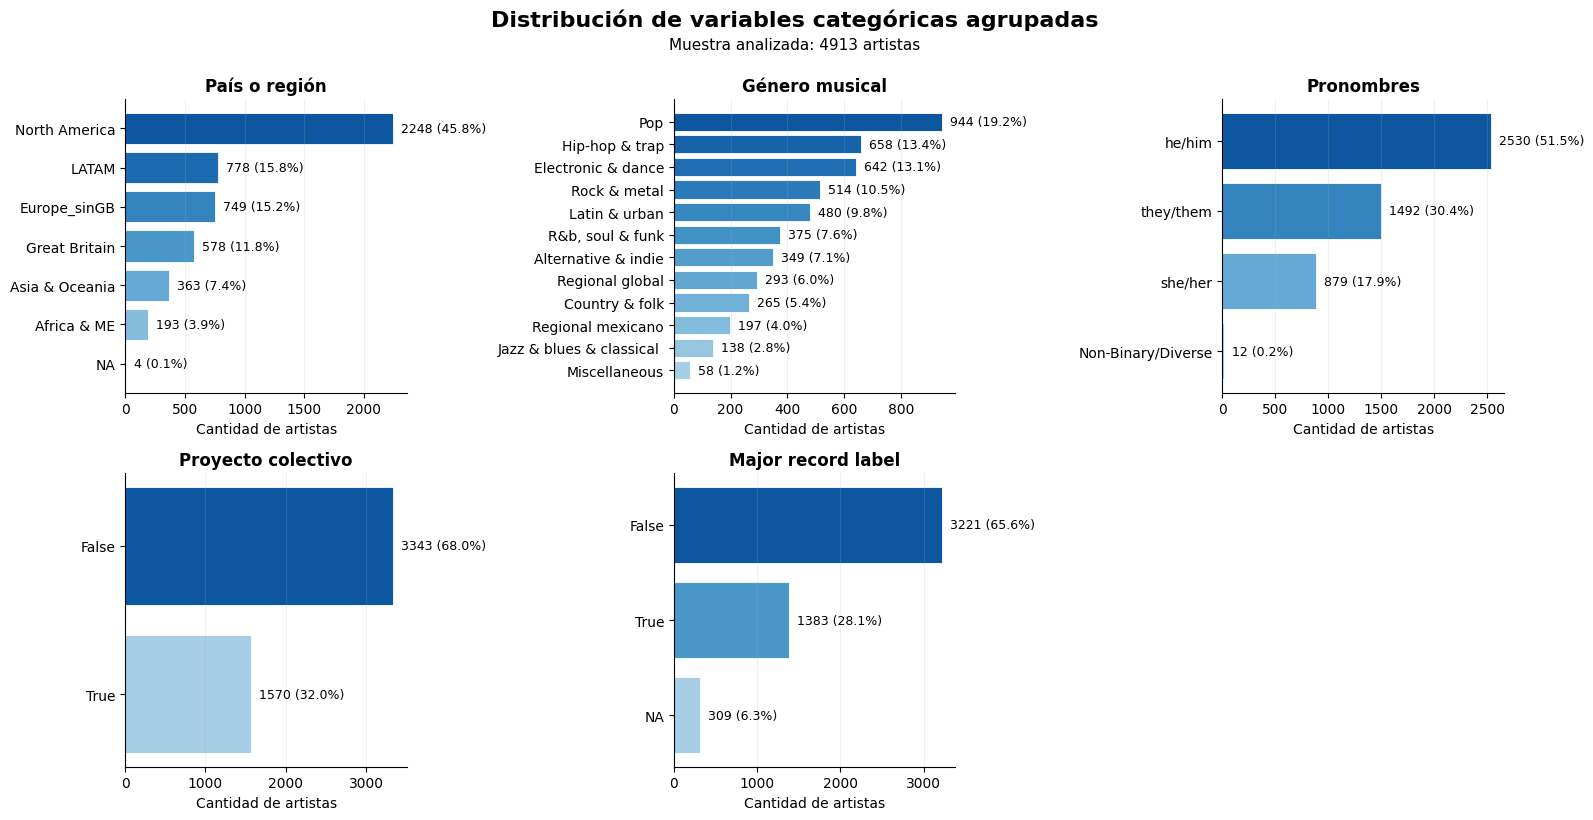

In [60]:
# ============================================================
# Panel estético de variables categóricas resumidas
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

cat_vars = [
    "country_short",
    "genre_short",
    "pronoun_short",
    "band",
    "major_record_label"
]

titulos = {
    "country_short": "País o región",
    "genre_short": "Género musical",
    "pronoun_short": "Pronombres",
    "band": "Proyecto colectivo",
    "major_record_label": "Major record label"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

fig.suptitle(
    "Distribución de variables categóricas agrupadas",
    fontsize=16,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5,
    0.97,
    f"Muestra analizada: {len(df)} artistas",
    ha="center",
    fontsize=11
)

for i, col in enumerate(cat_vars):
    ax = axes[i]

    freq = (
        df[col]
        .astype("string")
        .fillna("NA")
        .value_counts(dropna=False)
        .sort_values(ascending=True)
    )

    labels = freq.index.tolist()
    values = freq.values
    pct = values / values.sum() * 100

    colors = plt.cm.Blues(np.linspace(0.35, 0.85, len(values)))

    bars = ax.barh(
        labels,
        values,
        color=colors,
        edgecolor="white",
        linewidth=0.6
    )

    ax.set_title(titulos[col], fontsize=12, fontweight="bold")
    ax.set_xlabel("Cantidad de artistas", fontsize=10)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.18)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    for bar, v, p in zip(bars, values, pct):
        ax.text(
            v,
            bar.get_y() + bar.get_height() / 2,
            f"  {v} ({p:.1f}%)",
            va="center",
            fontsize=9
        )

# Ocultar subplot vacío
for j in range(len(cat_vars), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

ruta_categ = (
    directorio_salidas_proyecto /
    "distribucion_categoricas.png"
)

plt.savefig(
    ruta_categ,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Correlación de Spearman con la target

In [61]:
# ============================================================
# Correlación entre variables digitales y target transformada
# ============================================================

target = "n_shows_24_25"

# Variables digitales numéricas
eda_num_vars = digital_numeric_vars.copy()

# Variables que se transforman con log1p
vars_log = [col for col in eda_num_vars if col != "sp_popularity"]

df_corr = df.copy()

# Target transformada
df_corr["log1p_n_shows_24_25"] = np.log1p(df_corr[target].astype(float))

# Transformación de variables digitales
for col in vars_log:
    df_corr[f"log1p_{col}"] = np.log1p(df_corr[col].astype(float))

# sp_popularity se conserva en escala original
vars_corr = [f"log1p_{col}" for col in vars_log] + ["sp_popularity"]

# Cálculo de correlaciones con la target transformada
corr_target = (
    df_corr[vars_corr + ["log1p_n_shows_24_25"]]
    .corr(method="spearman")["log1p_n_shows_24_25"]
    .drop("log1p_n_shows_24_25")
    .sort_values(ascending=False)
    .reset_index()
)

corr_target.columns = ["variable", "correlacion_log1p_shows_24_25"]

corr_target

,variable,correlacion_log1p_shows_24_25
0,log1p_num_yt_editorial_playlists,0.222200
1,sp_popularity,0.215865
2,log1p_pandora_lifetime_streams,0.208348
3,log1p_pandora_lifetime_stations_added,0.208279
4,log1p_sp_editorial_playlist_total_reach,0.205673
5,log1p_num_az_playlists,0.197888
6,log1p_num_az_editorial_playlists,0.193805
7,log1p_num_sp_playlists,0.189253
8,log1p_sp_playlist_total_reach,0.174624
9,log1p_sp_followers,0.171460


In [62]:
# ============================================================
# Preparación de correlaciones con dimensión de pertenencia
# ============================================================

corr_plot = corr_target.copy()

corr_plot["variable_original"] = (
    corr_plot["variable"]
    .str.replace("log1p_", "", regex=False)
)

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    elif variable == "sp_popularity":
        return "streaming"
    else:
        return "otra"

corr_plot["dimension"] = corr_plot["variable_original"].apply(asignar_dimension)

corr_plot.head(15)

,variable,correlacion_log1p_shows_24_25,variable_original,dimension
0,log1p_num_yt_editorial_playlists,0.222200,num_yt_editorial_playlists,playlists
1,sp_popularity,0.215865,sp_popularity,streaming
2,log1p_pandora_lifetime_streams,0.208348,pandora_lifetime_streams,streaming
3,log1p_pandora_lifetime_stations_added,0.208279,pandora_lifetime_stations_added,streaming
4,log1p_sp_editorial_playlist_total_reach,0.205673,sp_editorial_playlist_total_reach,playlists
5,log1p_num_az_playlists,0.197888,num_az_playlists,playlists
6,log1p_num_az_editorial_playlists,0.193805,num_az_editorial_playlists,playlists
7,log1p_num_sp_playlists,0.189253,num_sp_playlists,playlists
8,log1p_sp_playlist_total_reach,0.174624,sp_playlist_total_reach,playlists
9,log1p_sp_followers,0.171460,sp_followers,streaming


In [63]:
# ============================================================
# Control de asignación de dimensiones en correlaciones
# ============================================================

corr_plot["dimension"].value_counts()

corr_plot.loc[
    corr_plot["dimension"] == "otra",
    ["variable", "variable_original", "dimension"]
]

,variable,variable_original,dimension


In [64]:
# ============================================================
# Resumen de correlaciones por dimensión
# ============================================================

resumen_corr_dimension = (
    corr_plot
    .groupby("dimension")
    .agg(
        n_variables=("variable_original", "count"),
        correlacion_media=("correlacion_log1p_shows_24_25", "mean"),
        correlacion_mediana=("correlacion_log1p_shows_24_25", "median"),
        correlacion_maxima=("correlacion_log1p_shows_24_25", "max")
    )
    .reset_index()
    .sort_values("correlacion_maxima", ascending=False)
)

resumen_corr_dimension[
    ["correlacion_media", "correlacion_mediana", "correlacion_maxima"]
] = resumen_corr_dimension[
    ["correlacion_media", "correlacion_mediana", "correlacion_maxima"]
].round(3)

resumen_corr_dimension

,dimension,n_variables,correlacion_media,correlacion_mediana,correlacion_maxima
0,playlists,15,0.141,0.149,0.222
2,streaming,7,0.171,0.171,0.216
3,youtube,4,0.070,0.069,0.134
1,redes_sociales,7,0.089,0.100,0.129


In [65]:
# ============================================================
# Comparación de correlaciones crudas y transformadas
# ============================================================

target = "n_shows_24_25"

corr_raw = (
    df[digital_numeric_vars + [target]]
    .corr(method="spearman")[target]
    .drop(target)
    .reset_index()
)

corr_raw.columns = ["variable_original", "correlacion_raw_shows"]

corr_comparada = corr_plot.merge(
    corr_raw,
    on="variable_original",
    how="left"
)

corr_comparada = corr_comparada[
    [
        "variable_original",
        "dimension",
        "correlacion_log1p_shows_24_25",
        "correlacion_raw_shows"
    ]
].sort_values("correlacion_log1p_shows_24_25", ascending=False)

corr_comparada

,variable_original,dimension,correlacion_log1p_shows_24_25,correlacion_raw_shows
0,num_yt_editorial_playlists,playlists,0.222200,0.222200
1,sp_popularity,streaming,0.215865,0.215865
2,pandora_lifetime_streams,streaming,0.208348,0.208348
3,pandora_lifetime_stations_added,streaming,0.208279,0.208279
4,sp_editorial_playlist_total_reach,playlists,0.205673,0.205673
5,num_az_playlists,playlists,0.197888,0.197888
6,num_az_editorial_playlists,playlists,0.193805,0.193805
7,num_sp_playlists,playlists,0.189253,0.189253
8,sp_playlist_total_reach,playlists,0.174624,0.174624
9,sp_followers,streaming,0.171460,0.171460


# Correlación de Pearson con la target
Con variables transformadas mejora la asociación lineal con la target transformada; Spearman no refleja esa diferencia.

In [66]:
# ============================================================
# Comparación de correlaciones Pearson crudas y transformadas
# ============================================================

import numpy as np
import pandas as pd

target = "n_shows_24_25"

# Variables digitales numéricas
eda_num_vars = digital_numeric_vars.copy()

# Variables a transformar con log1p
vars_log = [col for col in eda_num_vars if col != "sp_popularity"]

# Copia auxiliar para correlaciones
df_pearson = df.copy()

# Target transformada
df_pearson["log1p_n_shows_24_25"] = np.log1p(df_pearson[target].astype(float))

# Variables digitales transformadas
for col in vars_log:
    df_pearson[f"log1p_{col}"] = np.log1p(df_pearson[col].astype(float))

# ============================================================
# Pearson con variables originales y target original
# ============================================================

pearson_raw = (
    df_pearson[eda_num_vars + [target]]
    .corr(method="pearson")[target]
    .drop(target)
    .reset_index()
)

pearson_raw.columns = [
    "variable_original",
    "pearson_original_vs_target_original"
]

# ============================================================
# Pearson con variables transformadas y target transformada
# ============================================================

vars_transformadas = [f"log1p_{col}" for col in vars_log] + ["sp_popularity"]

pearson_log = (
    df_pearson[vars_transformadas + ["log1p_n_shows_24_25"]]
    .corr(method="pearson")["log1p_n_shows_24_25"]
    .drop("log1p_n_shows_24_25")
    .reset_index()
)

pearson_log.columns = [
    "variable",
    "pearson_transformada_vs_target_transformada"
]

pearson_log["variable_original"] = (
    pearson_log["variable"]
    .str.replace("log1p_", "", regex=False)
)

# ============================================================
# Comparación final
# ============================================================

pearson_comparada = pearson_raw.merge(
    pearson_log[[
        "variable_original",
        "pearson_transformada_vs_target_transformada"
    ]],
    on="variable_original",
    how="left"
)

pearson_comparada["diferencia_transformacion"] = (
    pearson_comparada["pearson_transformada_vs_target_transformada"]
    - pearson_comparada["pearson_original_vs_target_original"]
)

pearson_comparada = pearson_comparada.sort_values(
    "pearson_transformada_vs_target_transformada",
    ascending=False
).reset_index(drop=True)

pearson_comparada

,variable_original,pearson_original_vs_target_original,pearson_transformada_vs_target_transformada,diferencia_transformacion
0,sp_popularity,0.208104,0.224380,0.016277
1,num_yt_editorial_playlists,0.156586,0.217208,0.060622
2,num_sp_playlists,0.138444,0.201269,0.062825
3,sp_followers,0.071511,0.195621,0.124110
4,sp_playlist_total_reach,0.150194,0.194272,0.044078
5,num_az_playlists,0.163842,0.193625,0.029784
6,sp_editorial_playlist_total_reach,0.176967,0.192697,0.015730
7,sp_monthly_listeners,0.152989,0.189604,0.036615
8,pandora_lifetime_stations_added,0.137430,0.189364,0.051934
9,num_az_editorial_playlists,0.160709,0.188515,0.027806


In [67]:
# ============================================================
# Preparación de Pearson transformado con dimensión de pertenencia
# ============================================================

pearson_plot = pearson_comparada.copy()

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

pearson_plot["dimension"] = pearson_plot["variable_original"].apply(asignar_dimension)

pearson_plot["dimension"].value_counts()

dimension
playlists         15
streaming          7
redes_sociales     7
youtube            4
Name: count, dtype: int64

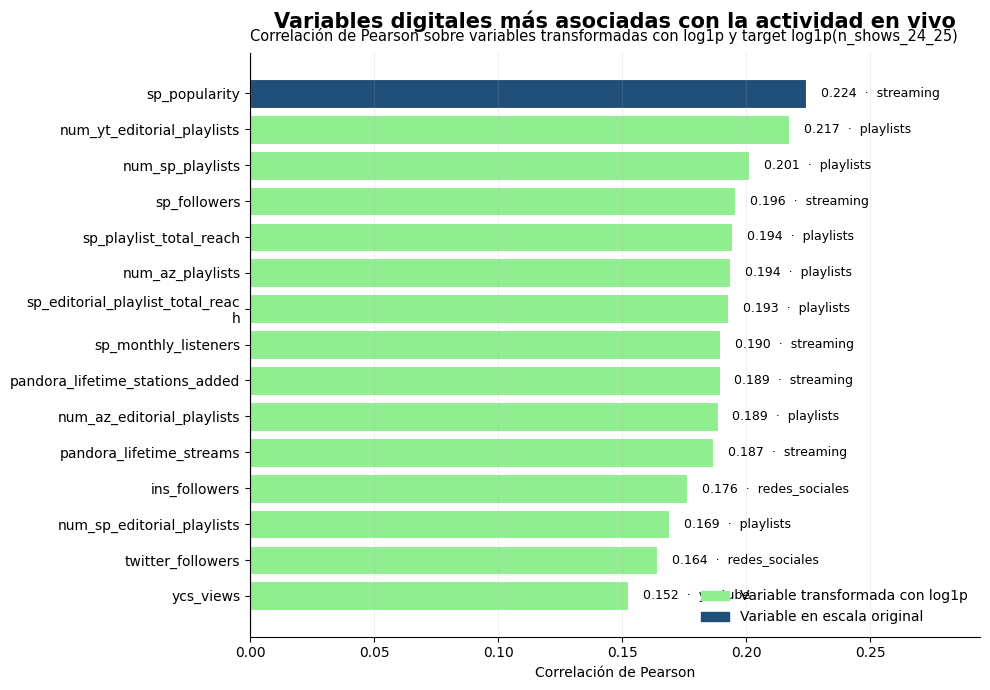

In [68]:
# ============================================================
# Gráfico de correlaciones Pearson con la target transformada
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import textwrap

corr_col = "pearson_transformada_vs_target_transformada"
top_n = 15

pearson_plot = pearson_comparada.copy()

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

pearson_plot["dimension"] = pearson_plot["variable_original"].apply(asignar_dimension)

corr_top = (
    pearson_plot
    .sort_values(corr_col, ascending=False)
    .head(top_n)
    .sort_values(corr_col, ascending=True)
    .copy()
)

color_log = "#90EE90"
color_original = "#1F4E79"
line_green = "#2E7D32"
line_blue = "#0B2F4F"

corr_top["tipo_escala"] = np.where(
    corr_top["variable_original"].eq("sp_popularity"),
    "original",
    "log1p"
)

corr_top["color"] = np.where(
    corr_top["tipo_escala"].eq("original"),
    color_original,
    color_log
)

corr_top["variable_label"] = corr_top["variable_original"].apply(
    lambda x: "\n".join(textwrap.wrap(x, width=32))
)

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.barh(
    corr_top["variable_label"],
    corr_top[corr_col],
    color=corr_top["color"],
    edgecolor="white",
    linewidth=0.8
)

ax.set_title(
    "Variables digitales más asociadas con la actividad en vivo",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.text(
    0,
    1.02,
    "Correlación de Pearson sobre variables transformadas con log1p y target log1p(n_shows_24_25)",
    transform=ax.transAxes,
    ha="left",
    fontsize=10.5
)

ax.set_xlabel("Correlación de Pearson")
ax.set_ylabel("")

for bar, value, dimension in zip(bars, corr_top[corr_col], corr_top["dimension"]):
    ax.text(
        value + 0.006,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}  ·  {dimension}",
        va="center",
        fontsize=9
    )

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=color_log),
    plt.Rectangle((0, 0), 1, 1, color=color_original)
]

ax.legend(
    legend_handles,
    ["Variable transformada con log1p", "Variable en escala original"],
    frameon=False,
    loc="lower right"
)

ax.axvline(0, color="#555555", linewidth=0.8)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", alpha=0.18)

ax.set_xlim(
    0,
    corr_top[corr_col].max() + 0.07
)

plt.tight_layout()
plt.show()

# Correlación de Pearson en el subconjunto
Variables conservadas tras el análisis de multicolinealidad.

In [69]:
# ============================================================
# Preparación de correlaciones Pearson del subset seleccionado
# ============================================================

import numpy as np
import pandas as pd

variables_corr_subset = [
    "num_sp_playlists",
    "num_az_playlists",
    "sp_monthly_listeners",
    "num_yt_editorial_playlists",
    "tiktok_top_video_comments",
    "sp_followers",
    "pandora_lifetime_streams",
    "tiktok_followers",
    "ycs_views",
    "deezer_fans",
    "ins_followers",
    "twitter_followers"
]

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

corr_vars = (
    pearson_comparada
    .loc[
        pearson_comparada["variable_original"].isin(variables_corr_subset),
        ["variable_original", "pearson_transformada_vs_target_transformada"]
    ]
    .copy()
)

corr_vars["dimension"] = corr_vars["variable_original"].apply(asignar_dimension)

corr_vars = corr_vars.rename(
    columns={
        "variable_original": "label",
        "pearson_transformada_vs_target_transformada": "correlacion"
    }
)

corr_vars = (
    corr_vars
    .sort_values("correlacion", ascending=True)
    .reset_index(drop=True)
)

corr_vars

,label,correlacion,dimension
0,tiktok_followers,0.068738,redes_sociales
1,deezer_fans,0.078867,streaming
2,tiktok_top_video_comments,0.137060,redes_sociales
3,ycs_views,0.152315,youtube
4,twitter_followers,0.164293,redes_sociales
5,ins_followers,0.176289,redes_sociales
6,pandora_lifetime_streams,0.186859,streaming
7,sp_monthly_listeners,0.189604,streaming
8,num_az_playlists,0.193625,playlists
9,sp_followers,0.195621,streaming


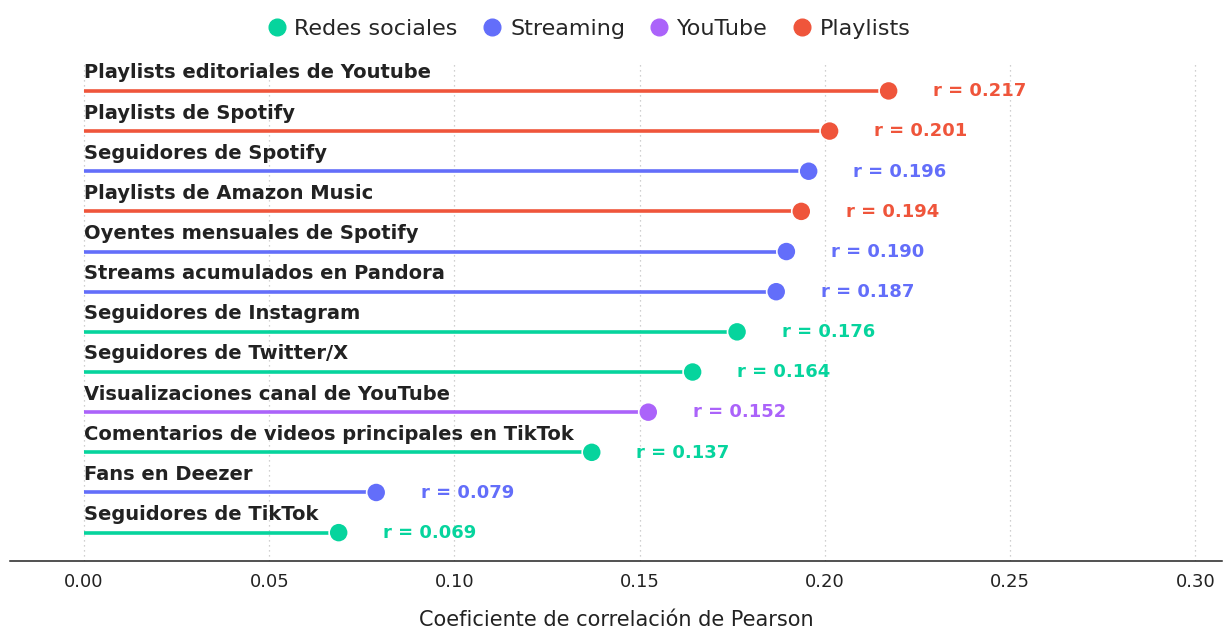

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\correlacion_final.png


In [156]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Paleta y estilo general del informe
# ------------------------------------------------------------

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"


colores_dimension = { "streaming": "#264C96", "playlists": "#93C4F0", "redes_sociales": "#D63A2F", "youtube": "#6F7BD0", "otra": "#666666" }

etiquetas_dimension = {
    "streaming": "Streaming",
    "playlists": "Playlists",
    "redes_sociales": "Redes sociales",
    "youtube": "YouTube",
    "otra": "Otras variables"
}

etiquetas_variables = {
    "sp_followers": "Seguidores de Spotify",
    "sp_monthly_listeners": "Oyentes mensuales de Spotify",
    "pandora_lifetime_streams": "Streams acumulados en Pandora",
    "ins_followers": "Seguidores de Instagram",
    "twitter_followers": "Seguidores de Twitter/X",
    "tiktok_followers": "Seguidores de TikTok",
    "tiktok_likes": "Likes en TikTok",
    "tiktok_top_video_views": "Visualizaciones de videos principales en TikTok",
    "tiktok_top_video_likes": "Likes de videos principales en TikTok",
    "tiktok_top_video_comments": "Comentarios de videos principales en TikTok",
    "ycs_views": "Visualizaciones canal de YouTube",
    "ycs_subscribers": "Suscriptores de canal de YouTube",
    "num_sp_playlists": "Playlists de Spotify",
    "num_az_playlists": "Playlists de Amazon Music",
    "num_am_playlists": "Playlists de Apple Music",
    "num_de_playlists": "Playlists de Deezer",
    "num_yt_playlists": "Playlists de YouTube",
    "num_sp_editorial_playlists": "Playlists editoriales de Spotify",
    "num_sp_algorithmic_playlists": "Playlists algorítmicas de Spotify",
    "log_ins_sp_ratio": "Ratio Instagram / Spotify",
    "log_tiktok_sp_ratio": "Ratio TikTok / Spotify",
    "log_youtube_sp_ratio": "Ratio YouTube / Spotify",
    "num_yt_editorial_playlists": "Playlists editoriales de Youtube",
    "deezer_fans": "Fans en Deezer"
}

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Preparación de datos
# ------------------------------------------------------------

corr_vars = corr_vars.copy()

corr_vars["color"] = corr_vars["dimension"].map(colores_dimension)
corr_vars["label_largo"] = corr_vars["label"].replace(etiquetas_variables)

corr_vars = (
    corr_vars
    .sort_values("correlacion", ascending=True)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Figura (Se achicó la altura de 8.2 a 6.8)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6.8))
fig.patch.set_facecolor(color_fondo)
ax.set_facecolor(color_fondo)

y_pos = np.arange(len(corr_vars))

# ------------------------------------------------------------
# Líneas del lollipop
# ------------------------------------------------------------

ax.hlines(
    y=y_pos,
    xmin=0,
    xmax=corr_vars["correlacion"],
    color=corr_vars["color"],
    linewidth=2.6,
    alpha=1.0,
    zorder=2
)

# ------------------------------------------------------------
# Puntos principales
# ------------------------------------------------------------

ax.scatter(
    corr_vars["correlacion"],
    y_pos,
    s=190,
    color=corr_vars["color"],
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

# ------------------------------------------------------------
# Etiquetas sobre cada línea 
# ------------------------------------------------------------

for i, row in corr_vars.iterrows():

    x_label = 0.0 

    ax.text(
        x_label,
        i + 0.22, # Ajustado levemente para la nueva densidad vertical
        row["label_largo"],
        va="bottom",
        ha="left", 
        fontsize=14,
        fontweight="bold",
        color=color_texto,
        zorder=4
    )

    ax.text(
        row["correlacion"] + 0.012,
        i,
        f"r = {row['correlacion']:.3f}".replace(".", ","),
        va="center",
        ha="left",
        fontsize=13,
        fontweight="bold",
        color=color_texto,  # texto en gris oscuro: el celeste no se lee como texto
        zorder=4
    )

# ------------------------------------------------------------
# Leyenda superior
# ------------------------------------------------------------

dimensiones_presentes = corr_vars["dimension"].drop_duplicates().tolist()

elementos_leyenda = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=colores_dimension[dimension],
        markeredgecolor=colores_dimension[dimension],
        markersize=12,
        label=etiquetas_dimension[dimension]
    )
    for dimension in dimensiones_presentes
]

fig.legend(
    handles=elementos_leyenda,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=len(elementos_leyenda),
    frameon=False,
    fontsize=16,
    handlelength=0.7,
    handletextpad=0.45,
    columnspacing=1.20
)

# ------------------------------------------------------------
# Ejes y grilla
# ------------------------------------------------------------

ax.set_yticks([])

ax.set_xlabel(
    "Coeficiente de correlación de Pearson",
    fontsize=15,
    color=color_texto,
    labelpad=14
)

ax.set_xlim(
    -0.02,
    corr_vars["correlacion"].max() + 0.09
)

ax.set_ylim(
    -0.7,
    len(corr_vars) - 0.25
)

ax.grid(
    axis="x",
    linestyle=(0, (1, 3)),
    linewidth=0.9,
    color=color_grilla,
    alpha=0.95
)

ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(color_texto)
ax.spines["bottom"].set_linewidth(1.1)

ax.tick_params(
    axis="x",
    length=5,
    width=1,
    color=color_texto,
    labelsize=13,
    labelcolor=color_texto
)

ax.tick_params(
    axis="y",
    length=0
)

# Coma decimal en el eje, igual que en el resto de la tesis
ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda valor, _: f"{valor:.2f}".replace(".", ","))
)

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

plt.tight_layout(rect=[0.04, 0.03, 1, 0.92])

ruta_pearson = (
    directorio_salidas_proyecto /
    "correlacion_final.png"
)

plt.savefig(
    ruta_pearson,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

# Mismo gráfico con el nombre usado en la tesis
plt.savefig(
    directorio_salidas_proyecto / "redundancia_metricas_digitales.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_pearson}")

# Comparación Spearman vs Pearson

In [73]:
# ============================================================
# Comparación de rankings entre Spearman y Pearson transformado
# ============================================================

spearman_rank = corr_plot.copy()

spearman_rank = spearman_rank.rename(
    columns={
        "correlacion_log1p_shows_24_25": "spearman"
    }
)

spearman_rank["rank_spearman"] = (
    spearman_rank["spearman"]
    .rank(ascending=False, method="min")
    .astype(int)
)

pearson_rank = pearson_plot.copy()

pearson_rank = pearson_rank.rename(
    columns={
        "pearson_transformada_vs_target_transformada": "pearson_transformado"
    }
)

pearson_rank["rank_pearson"] = (
    pearson_rank["pearson_transformado"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparado = spearman_rank[
    ["variable_original", "dimension", "spearman", "rank_spearman"]
].merge(
    pearson_rank[
        ["variable_original", "pearson_transformado", "rank_pearson"]
    ],
    on="variable_original",
    how="inner"
)

ranking_comparado["diferencia_rank"] = (
    ranking_comparado["rank_pearson"] - ranking_comparado["rank_spearman"]
)

ranking_comparado = ranking_comparado.sort_values("rank_spearman")

ranking_comparado.head(20)

,variable_original,dimension,spearman,rank_spearman,pearson_transformado,rank_pearson,diferencia_rank
0,num_yt_editorial_playlists,playlists,0.222200,1,0.217208,2,1
1,sp_popularity,streaming,0.215865,2,0.224380,1,-1
2,pandora_lifetime_streams,streaming,0.208348,3,0.186859,11,8
3,pandora_lifetime_stations_added,streaming,0.208279,4,0.189364,9,5
4,sp_editorial_playlist_total_reach,playlists,0.205673,5,0.192697,7,2
5,num_az_playlists,playlists,0.197888,6,0.193625,6,0
6,num_az_editorial_playlists,playlists,0.193805,7,0.188515,10,3
7,num_sp_playlists,playlists,0.189253,8,0.201269,3,-5
8,sp_playlist_total_reach,playlists,0.174624,9,0.194272,5,-4
9,sp_followers,streaming,0.171460,10,0.195621,4,-6


In [74]:
# ============================================================
# Variables que más cambian de posición entre métodos
# ============================================================

ranking_comparado.sort_values(
    "diferencia_rank",
    ascending=True
).head(10)

,variable_original,dimension,spearman,rank_spearman,pearson_transformado,rank_pearson,diferencia_rank
18,ins_followers,redes_sociales,0.128806,19,0.176289,12,-7
9,sp_followers,streaming,0.171460,10,0.195621,4,-6
21,ycs_subscribers,youtube,0.111251,22,0.146769,17,-5
7,num_sp_playlists,playlists,0.189253,8,0.201269,3,-5
8,sp_playlist_total_reach,playlists,0.174624,9,0.194272,5,-4
17,twitter_followers,redes_sociales,0.129265,18,0.164293,14,-4
26,tiktok_track_posts,redes_sociales,0.083497,27,0.114177,24,-3
10,sp_monthly_listeners,streaming,0.171233,11,0.189604,8,-3
22,tiktok_top_video_views,redes_sociales,0.099510,23,0.133574,21,-2
29,tiktok_likes,redes_sociales,0.030579,30,0.057645,29,-1


# Slope chart: rankings Spearman vs Pearson

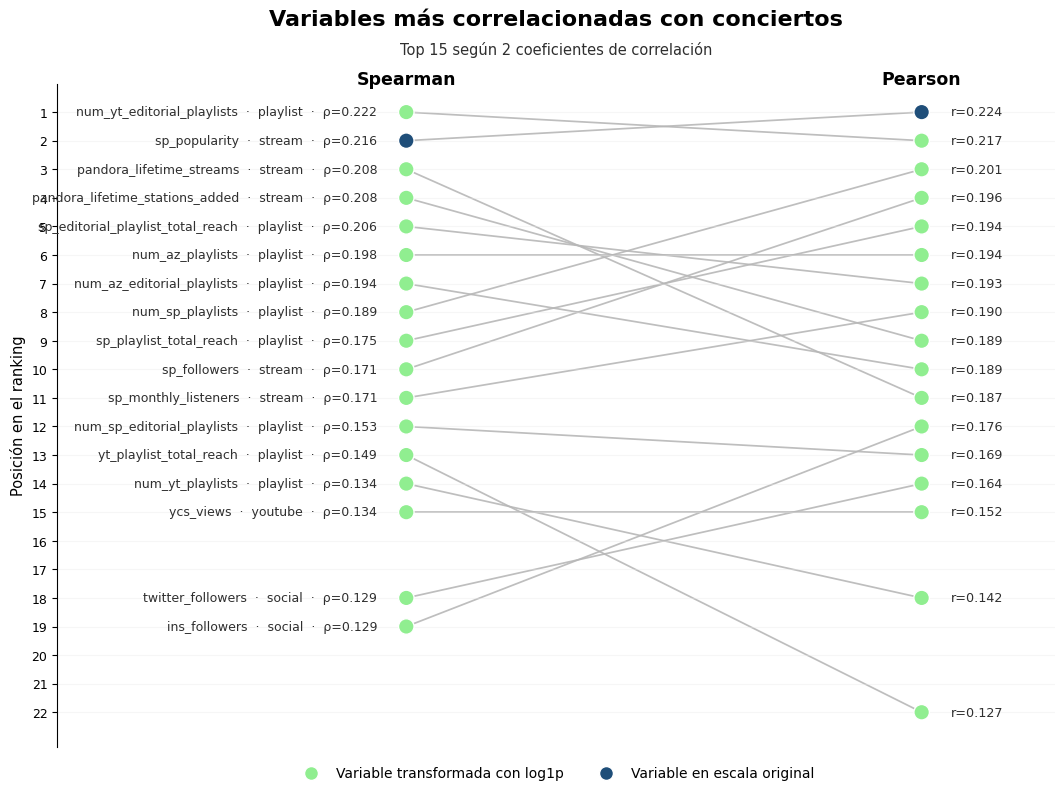

In [77]:


import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

top_n = 15

color_log = "#90EE90"
color_original = "#1F4E79"
color_line = "#B7B7B7"
color_text = "#2F2F2F"
color_grid = "#E6E6E6"

# ------------------------------------------------------------
# Selección de variables a mostrar
# ------------------------------------------------------------

top_spearman = (
    ranking_comparado
    .sort_values("rank_spearman")
    .head(top_n)["variable_original"]
    .tolist()
)

top_pearson = (
    ranking_comparado
    .sort_values("rank_pearson")
    .head(top_n)["variable_original"]
    .tolist()
)

vars_union = sorted(set(top_spearman).union(set(top_pearson)))

plot_df = ranking_comparado[
    ranking_comparado["variable_original"].isin(vars_union)
].copy()

plot_df["rank_promedio"] = (
    plot_df["rank_spearman"] + plot_df["rank_pearson"]
) / 2

plot_df = plot_df.sort_values("rank_promedio").reset_index(drop=True)

# ------------------------------------------------------------
# Definición de escala de las variables
# ------------------------------------------------------------

plot_df["tipo_escala"] = np.where(
    plot_df["variable_original"].eq("sp_popularity"),
    "original",
    "log1p"
)

plot_df["color"] = np.where(
    plot_df["tipo_escala"].eq("original"),
    color_original,
    color_log
)

# ------------------------------------------------------------
# Etiquetas de dimensión
# ------------------------------------------------------------

# def asignar_dimension(variable):
#     if variable in streaming_cols:
#         return "streaming"
#     elif variable in playlist_cols:
#         return "playlists"
#     elif variable in social_cols:
#         return "redes sociales"
#     elif variable in youtube_cols:
#         return "youtube"
#     else:
#         return "otra"

# if "dimension" not in plot_df.columns:
#     plot_df["dimension"] = plot_df["variable_original"].apply(asignar_dimension)

# dimension_map = {
#     "streaming": "streaming",
#     "playlists": "playlists",
#     "redes_sociales": "redes sociales",
#     "redes sociales": "redes sociales",
#     "youtube": "youtube",
#     "otra": "otra"
# }

# plot_df["dimension_label"] = (
#     plot_df["dimension"]
#     .map(dimension_map)
#     .fillna(plot_df["dimension"])
# )

# ------------------------------------------------------------
# Etiquetas de dimensión
# ------------------------------------------------------------

def asignar_dimension_grafico(variable):
    if variable in playlist_cols:
        return "playlists"
    elif variable in streaming_cols:
        return "streaming"
    elif variable in social_cols:
        return "redes sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

plot_df["dimension_label"] = (
    plot_df["variable_original"]
    .apply(asignar_dimension_grafico)
)

# ------------------------------------------------------------
# Posiciones de columnas
# ------------------------------------------------------------

x_left = 0.00
x_right = 0.62

fig, ax = plt.subplots(figsize=(17.5, 8.5))

# ------------------------------------------------------------
# Líneas de conexión
# ------------------------------------------------------------

for _, row in plot_df.iterrows():
    ax.plot(
        [x_left, x_right],
        [row["rank_spearman"], row["rank_pearson"]],
        color=color_line,
        linewidth=1.25,
        alpha=0.9,
        zorder=1
    )

# ------------------------------------------------------------
# Puntos
# ------------------------------------------------------------

ax.scatter(
    np.repeat(x_left, len(plot_df)),
    plot_df["rank_spearman"],
    s=125,
    c=plot_df["color"],
    edgecolors="white",
    linewidths=1.0,
    zorder=3
)

ax.scatter(
    np.repeat(x_right, len(plot_df)),
    plot_df["rank_pearson"],
    s=125,
    c=plot_df["color"],
    edgecolors="white",
    linewidths=1.0,
    zorder=3
)


# ------------------------------------------------------------
# Etiquetas izquierda: variable, dimensión y Spearman
# ------------------------------------------------------------

dimension_short_map = {
    "streaming": "stream",
    "playlists": "playlist",
    "redes sociales": "social",
    "youtube": "youtube",
    "otra": "otra"
}

plot_df["dimension_label_short"] = (
    plot_df["dimension_label"]
    .map(dimension_short_map)
    .fillna(plot_df["dimension_label"])
)

for _, row in plot_df.iterrows():
    ax.text(
        x_left - 0.035,
        row["rank_spearman"],
        # f'{row["variable_original"]}  ·  {row["dimension_label"]}  ·  ρ={row["spearman"]:.3f}',
        f'{row["variable_original"]}  ·  {row["dimension_label_short"]}  ·  ρ={row["spearman"]:.3f}',
        ha="right",
        va="center",
        fontsize=9,
        color=color_text
    )
    

# # ------------------------------------------------------------
# # Etiquetas derecha: Pearson y dimensión
# # ------------------------------------------------------------

# for _, row in plot_df.iterrows():
#     ax.text(
#         x_right + 0.035,
#         row["rank_pearson"],
#         f'r={row["pearson_transformado"]:.3f}',
#         ha="left",
#         va="center",
#         fontsize=9.2,
#         color=color_text
#     )
    
#     ax.text(
#         x_right + 0.125,
#         row["rank_pearson"],
#         f'{row["dimension_label"]}',
#         ha="left",
#         va="center",
#         fontsize=9.2,
#         color="#777777",
#         fontstyle="italic"
#     )


# ------------------------------------------------------------
# Etiquetas derecha: Pearson
# ------------------------------------------------------------

for _, row in plot_df.iterrows():
    ax.text(
        x_right + 0.035,
        row["rank_pearson"],
        f'r={row["pearson_transformado"]:.3f}',
        ha="left",
        va="center",
        fontsize=9.2,
        color=color_text
    )

# ------------------------------------------------------------
# Encabezados de columnas
# ------------------------------------------------------------

ax.text(
    x_left,
    0.15,
    "Spearman",
    ha="center",
    va="bottom",
    fontsize=12.5,
    fontweight="bold"
)

ax.text(
    x_right,
    0.15,
    "Pearson",
    ha="center",
    va="bottom",
    fontsize=12.5,
    fontweight="bold"
)

# ------------------------------------------------------------
# Título y subtítulo
# ------------------------------------------------------------

ax.set_title(
    "Variables más correlacionadas con conciertos",
    fontsize=16,
    fontweight="bold",
    pad=42,
    loc="center"
)

ax.text(
    0.5,
    1.04,
    "Top 15 según 2 coeficientes de correlación",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10.5,
    color=color_text
)

# ------------------------------------------------------------
# Estética general
# ------------------------------------------------------------

n_filas = max(
    plot_df["rank_spearman"].max(),
    plot_df["rank_pearson"].max()
)

ax.set_xlim(-0.42, 0.78)
ax.set_ylim(n_filas + 1.2, 0)


ax.set_xticks([])
ax.set_xlabel("")

ax.set_yticks(range(1, int(n_filas) + 1))
ax.set_yticklabels(range(1, int(n_filas) + 1), fontsize=9)

ax.set_ylabel("Posición en el ranking", fontsize=10.5)

ax.grid(axis="y", alpha=0.35, color=color_grid)
ax.grid(axis="x", alpha=0)

for spine in ["top", "right", "bottom"]:
    ax.spines[spine].set_visible(False)

# ------------------------------------------------------------
# Leyenda
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color_log,
        markeredgecolor="white",
        markersize=10,
        label="Variable transformada con log1p"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor=color_original,
        markeredgecolor="white",
        markersize=10,
        label="Variable en escala original"
    )
]

ax.legend(
    handles=legend_handles,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    fontsize=10,
    bbox_transform=ax.transAxes
)


plt.subplots_adjust(
    left=0.33,
    right=0.90,
    top=0.90,
    bottom=0.12
)

plt.savefig(
    "grafico_correlaciones_comparadas.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Outliers

In [78]:
# ============================================================
# Percentiles altos de variables digitales numéricas
# ============================================================

percentiles_outliers = []

for col in digital_numeric_vars:
    s = df[col].dropna().astype(float)
    
    percentiles_outliers.append({
        "variable": col,
        "n": s.shape[0],
        "p50": s.quantile(0.50),
        "p75": s.quantile(0.75),
        "p90": s.quantile(0.90),
        "p95": s.quantile(0.95),
        "p99": s.quantile(0.99),
        "max": s.max(),
        "ratio_max_p99": s.max() / s.quantile(0.99) if s.quantile(0.99) != 0 else np.nan
    })

outliers_table = pd.DataFrame(percentiles_outliers)

outliers_table = (
    outliers_table
    .sort_values("ratio_max_p99", ascending=False)
    .reset_index(drop=True)
)

outliers_table

,variable,n,p50,p75,p90,p95,p99,max,ratio_max_p99
0,youtube_monthly_video_views,3401,4802067.0,1.151468e+07,2.602091e+07,4.194251e+07,1.099306e+08,1.456427e+09,13.248608
1,tiktok_likes,3604,4200000.0,1.915000e+07,6.692000e+07,1.556050e+08,5.490460e+08,5.300000e+09,9.653107
2,ins_followers,4580,665946.5,2.269546e+06,7.039771e+06,1.350860e+07,4.325371e+07,3.716868e+08,8.593176
3,twitter_followers,3968,114127.0,5.880365e+05,2.238386e+06,4.796359e+06,1.545483e+07,8.555388e+07,5.535736
4,sp_followers,4907,1136670.0,2.682848e+06,6.911443e+06,1.122251e+07,3.520164e+07,1.768927e+08,5.025126
5,pandora_lifetime_stations_added,4764,196163.0,1.159762e+06,4.117056e+06,7.672900e+06,1.891175e+07,9.229892e+07,4.880506
6,youtube_daily_video_views,3401,167838.0,4.045760e+05,9.172940e+05,1.486708e+06,3.619183e+06,1.719111e+07,4.749996
7,deezer_fans,4853,19684.0,1.597040e+05,6.481290e+05,1.253339e+06,4.490637e+06,2.074040e+07,4.618589
8,tiktok_top_video_comments,4905,801640.0,2.524224e+06,7.136003e+06,1.239006e+07,3.442127e+07,1.460943e+08,4.244304
9,ycs_subscribers,4670,561500.0,1.770000e+06,4.902000e+06,8.292000e+06,2.470000e+07,1.000000e+08,4.048583


In [79]:
# ============================================================
# Comparación de outliers antes y después de log1p
# ============================================================

import numpy as np
import pandas as pd

outlier_comparison = []

for col in digital_numeric_vars:
    s_raw = df[col].dropna().astype(float)
    
    if col == "sp_popularity":
        s_trans = s_raw.copy()
        transformacion = "original"
    else:
        s_trans = np.log1p(s_raw)
        transformacion = "log1p"
    
    p99_raw = s_raw.quantile(0.99)
    max_raw = s_raw.max()
    
    p99_trans = s_trans.quantile(0.99)
    max_trans = s_trans.max()
    
    ratio_raw = max_raw / p99_raw if p99_raw != 0 else np.nan
    ratio_trans = max_trans / p99_trans if p99_trans != 0 else np.nan
    
    outlier_comparison.append({
        "variable": col,
        "transformacion": transformacion,
        "ratio_max_p99_raw": ratio_raw,
        "ratio_max_p99_transformada": ratio_trans,
        "reduccion_ratio": ratio_raw - ratio_trans
    })

outlier_comparison = pd.DataFrame(outlier_comparison)

outlier_comparison = (
    outlier_comparison
    .sort_values("reduccion_ratio", ascending=False)
    .reset_index(drop=True)
)

outlier_comparison

,variable,transformacion,ratio_max_p99_raw,ratio_max_p99_transformada,reduccion_ratio
0,youtube_monthly_video_views,log1p,13.248608,1.139554,12.109054
1,tiktok_likes,log1p,9.653107,1.112667,8.540440
2,ins_followers,log1p,8.593176,1.122335,7.470841
3,twitter_followers,log1p,5.535736,1.103376,4.432360
4,sp_followers,log1p,5.025126,1.092909,3.932217
5,pandora_lifetime_stations_added,log1p,4.880506,1.094613,3.785893
6,youtube_daily_video_views,log1p,4.749996,1.103176,3.646820
7,deezer_fans,log1p,4.618589,1.099892,3.518697
8,tiktok_top_video_comments,log1p,4.244304,1.083299,3.161005
9,ycs_subscribers,log1p,4.048583,1.082149,2.966434


# Multicolinealidad

In [80]:
# ============================================================
# Pares de variables digitales altamente correlacionadas
# ============================================================

import numpy as np
import pandas as pd

umbral_corr = 0.75

df_multi = df.copy()

vars_log = [col for col in digital_numeric_vars if col != "sp_popularity"]

for col in vars_log:
    df_multi[f"log1p_{col}"] = np.log1p(df_multi[col].astype(float))

vars_multi = [f"log1p_{col}" for col in vars_log] + ["sp_popularity"]

corr_matrix = df_multi[vars_multi].corr(method="pearson")

corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["variable_1", "variable_2", "correlacion"]

corr_pairs["abs_correlacion"] = corr_pairs["correlacion"].abs()

corr_pairs_altas = (
    corr_pairs
    .loc[corr_pairs["abs_correlacion"] >= umbral_corr]
    .sort_values("abs_correlacion", ascending=False)
    .reset_index(drop=True)
)

corr_pairs_altas

,variable_1,variable_2,correlacion,abs_correlacion
0,log1p_num_az_editorial_playlists,log1p_num_az_playlists,0.995863,0.995863
1,log1p_tiktok_top_video_views,log1p_tiktok_top_video_comments,0.971184,0.971184
2,log1p_num_am_editorial_playlists,log1p_num_am_playlists,0.950284,0.950284
3,log1p_pandora_lifetime_streams,log1p_pandora_lifetime_stations_added,0.937331,0.937331
4,log1p_sp_monthly_listeners,sp_popularity,0.927539,0.927539
5,log1p_tiktok_followers,log1p_tiktok_likes,0.926640,0.926640
6,log1p_tiktok_top_video_views,log1p_tiktok_track_posts,0.923826,0.923826
7,log1p_tiktok_top_video_comments,log1p_tiktok_track_posts,0.922331,0.922331
8,log1p_sp_playlist_total_reach,log1p_num_sp_playlists,0.898405,0.898405
9,log1p_ycs_subscribers,log1p_ycs_views,0.880380,0.880380


In [81]:
# ============================================================
# Pares de variables digitales correlacionadas con información auxiliar
# ============================================================

import numpy as np
import pandas as pd

umbral_corr = 0.70

df_multi = df.copy()

vars_log = [col for col in digital_numeric_vars if col != "sp_popularity"]

for col in vars_log:
    df_multi[f"log1p_{col}"] = np.log1p(df_multi[col].astype(float))

vars_multi = [f"log1p_{col}" for col in vars_log] + ["sp_popularity"]

corr_matrix = df_multi[vars_multi].corr(method="pearson")

corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["variable_1", "variable_2", "correlacion_entre_vars"]

corr_pairs["abs_correlacion_entre_vars"] = corr_pairs["correlacion_entre_vars"].abs()

corr_pairs_070 = (
    corr_pairs
    .loc[corr_pairs["abs_correlacion_entre_vars"] >= umbral_corr]
    .sort_values("abs_correlacion_entre_vars", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Funciones auxiliares para recuperar variable original y dimensión
# ------------------------------------------------------------

def quitar_log1p(variable):
    return variable.replace("log1p_", "")

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

corr_pairs_070["var1_original"] = corr_pairs_070["variable_1"].apply(quitar_log1p)
corr_pairs_070["var2_original"] = corr_pairs_070["variable_2"].apply(quitar_log1p)

corr_pairs_070["dimension_1"] = corr_pairs_070["var1_original"].apply(asignar_dimension)
corr_pairs_070["dimension_2"] = corr_pairs_070["var2_original"].apply(asignar_dimension)

# ------------------------------------------------------------
# Correlación con target transformada
# ------------------------------------------------------------

target_corr_lookup = pearson_comparada.set_index("variable_original")[
    "pearson_transformada_vs_target_transformada"
].to_dict()

corr_pairs_070["corr_target_var1"] = corr_pairs_070["var1_original"].map(target_corr_lookup)
corr_pairs_070["corr_target_var2"] = corr_pairs_070["var2_original"].map(target_corr_lookup)

corr_pairs_070["mejor_corr_target"] = np.where(
    corr_pairs_070["corr_target_var1"] >= corr_pairs_070["corr_target_var2"],
    corr_pairs_070["var1_original"],
    corr_pairs_070["var2_original"]
)

corr_pairs_070["diferencia_corr_target"] = (
    corr_pairs_070["corr_target_var1"] - corr_pairs_070["corr_target_var2"]
).abs()

# ------------------------------------------------------------
# Porcentaje de nulos
# ------------------------------------------------------------

null_pct_lookup = (
    df[digital_numeric_vars]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

corr_pairs_070["pct_null_var1"] = corr_pairs_070["var1_original"].map(null_pct_lookup)
corr_pairs_070["pct_null_var2"] = corr_pairs_070["var2_original"].map(null_pct_lookup)

# ------------------------------------------------------------
# Selección de columnas para revisión
# ------------------------------------------------------------

corr_pairs_070 = corr_pairs_070[
    [
        "var1_original",
        "var2_original",
        "dimension_1",
        "dimension_2",
        "correlacion_entre_vars",
        "corr_target_var1",
        "corr_target_var2",
        "mejor_corr_target",
        "diferencia_corr_target",
        "pct_null_var1",
        "pct_null_var2"
    ]
].round({
    "correlacion_entre_vars": 3,
    "corr_target_var1": 3,
    "corr_target_var2": 3,
    "diferencia_corr_target": 3
})

pd.set_option("display.max_rows", 100)
pd.set_option("display.min_rows", 100)
corr_pairs_070

,var1_original,var2_original,dimension_1,dimension_2,correlacion_entre_vars,corr_target_var1,corr_target_var2,mejor_corr_target,diferencia_corr_target,pct_null_var1,pct_null_var2
0,num_az_editorial_playlists,num_az_playlists,playlists,playlists,0.996,0.189,0.194,num_az_playlists,0.005,4.84,4.84
1,tiktok_top_video_views,tiktok_top_video_comments,redes_sociales,redes_sociales,0.971,0.134,0.137,tiktok_top_video_comments,0.003,0.16,0.16
2,num_am_editorial_playlists,num_am_playlists,playlists,playlists,0.950,0.139,0.126,num_am_editorial_playlists,0.013,0.57,0.57
3,pandora_lifetime_streams,pandora_lifetime_stations_added,streaming,streaming,0.937,0.187,0.189,pandora_lifetime_stations_added,0.003,1.95,3.03
4,sp_monthly_listeners,sp_popularity,streaming,streaming,0.928,0.190,0.224,sp_popularity,0.035,0.12,0.04
5,tiktok_followers,tiktok_likes,redes_sociales,redes_sociales,0.927,0.069,0.058,tiktok_followers,0.011,26.64,26.64
6,tiktok_top_video_views,tiktok_track_posts,redes_sociales,redes_sociales,0.924,0.134,0.114,tiktok_top_video_views,0.019,0.16,0.22
7,tiktok_top_video_comments,tiktok_track_posts,redes_sociales,redes_sociales,0.922,0.137,0.114,tiktok_top_video_comments,0.023,0.16,0.22
8,sp_playlist_total_reach,num_sp_playlists,playlists,playlists,0.898,0.194,0.201,num_sp_playlists,0.007,0.00,0.00
9,ycs_subscribers,ycs_views,youtube,youtube,0.880,0.147,0.152,ycs_views,0.006,4.95,4.95


In [82]:
# ============================================================
# Variables más involucradas en pares altamente correlacionados
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Tabla larga con una fila por variable dentro de cada par
# ------------------------------------------------------------

vars_en_pares_1 = corr_pairs_070[
    [
        "var1_original",
        "dimension_1",
        "correlacion_entre_vars",
        "corr_target_var1",
        "pct_null_var1"
    ]
].copy()

vars_en_pares_1.columns = [
    "variable",
    "dimension",
    "correlacion_entre_vars",
    "corr_target",
    "pct_null"
]

vars_en_pares_2 = corr_pairs_070[
    [
        "var2_original",
        "dimension_2",
        "correlacion_entre_vars",
        "corr_target_var2",
        "pct_null_var2"
    ]
].copy()

vars_en_pares_2.columns = [
    "variable",
    "dimension",
    "correlacion_entre_vars",
    "corr_target",
    "pct_null"
]

vars_en_pares = pd.concat(
    [vars_en_pares_1, vars_en_pares_2],
    ignore_index=True
)

# ------------------------------------------------------------
# Resumen por variable
# ------------------------------------------------------------

redundancia_por_variable = (
    vars_en_pares
    .groupby(["variable", "dimension"])
    .agg(
        n_pares_altos=("correlacion_entre_vars", "count"),
        max_corr_con_otra_var=("correlacion_entre_vars", "max"),
        corr_media_con_otras_vars=("correlacion_entre_vars", "mean"),
        corr_target=("corr_target", "first"),
        pct_null=("pct_null", "first")
    )
    .reset_index()
)

redundancia_por_variable = (
    redundancia_por_variable
    .sort_values(
        ["n_pares_altos", "max_corr_con_otra_var", "corr_target"],
        ascending=[False, False, False]
    )
    .reset_index(drop=True)
)

redundancia_por_variable = redundancia_por_variable.round({
    "max_corr_con_otra_var": 3,
    "corr_media_con_otras_vars": 3,
    "corr_target": 3,
    "pct_null": 2
})

redundancia_por_variable

,variable,dimension,n_pares_altos,max_corr_con_otra_var,corr_media_con_otras_vars,corr_target,pct_null
0,sp_playlist_total_reach,playlists,13,0.898,0.779,0.194,0.00
1,num_sp_editorial_playlists,playlists,12,0.864,0.774,0.169,0.00
2,num_am_editorial_playlists,playlists,11,0.950,0.761,0.139,0.57
3,num_am_playlists,playlists,11,0.950,0.794,0.126,0.57
4,num_sp_playlists,playlists,8,0.898,0.790,0.201,0.00
5,num_de_playlists,playlists,7,0.877,0.778,0.038,2.08
6,num_az_playlists,playlists,6,0.996,0.794,0.194,4.84
7,sp_monthly_listeners,streaming,6,0.928,0.787,0.190,0.12
8,num_de_editorial_playlists,playlists,6,0.877,0.779,0.057,2.08
9,shazam_count,streaming,6,0.850,0.770,0.151,0.02


In [83]:
# ============================================================
# Tabla preliminar de decisión para variables redundantes
# ============================================================

decision_manual = {
    "sp_playlist_total_reach": {
        "decision": "evaluar",
        "motivo": "Alta correlación con target y sin nulos, pero muy redundante con varias métricas de playlists"
    },
    "num_sp_editorial_playlists": {
        "decision": "evaluar",
        "motivo": "Sin nulos y conceptualmente relevante para curaduría editorial, aunque redundante con playlists de otras plataformas"
    },
    "num_am_editorial_playlists": {
        "decision": "evaluar",
        "motivo": "Representa curaduría editorial de Apple Music, pero está muy correlacionada con num_am_playlists"
    },
    "num_am_playlists": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con num_am_editorial_playlists y menor correlación con target"
    },
    "num_sp_playlists": {
        "decision": "conservar_preliminar",
        "motivo": "Buena correlación con target, sin nulos y señal fuerte de presencia general en Spotify playlists"
    },
    "num_de_playlists": {
        "decision": "descartar_preliminar",
        "motivo": "Redundante con variables Deezer y baja correlación con target"
    },
    "num_az_playlists": {
        "decision": "conservar_preliminar",
        "motivo": "Buena correlación con target y ligeramente superior a su versión editorial"
    },
    "sp_monthly_listeners": {
        "decision": "evaluar",
        "motivo": "Métrica transparente de audiencia actual, aunque muy correlacionada con sp_popularity"
    },
    "num_de_editorial_playlists": {
        "decision": "descartar_preliminar",
        "motivo": "Redundante con variables Deezer y baja correlación con target"
    },
    "shazam_count": {
        "decision": "evaluar",
        "motivo": "Señal de descubrimiento, pero correlacionada con playlists de Spotify"
    },
    "num_yt_editorial_playlists": {
        "decision": "conservar_preliminar",
        "motivo": "Mayor correlación con target dentro de playlists y señal editorial clara"
    },
    "num_yt_playlists": {
        "decision": "descartar_preliminar",
        "motivo": "Correlacionada con num_yt_editorial_playlists y menor correlación con target"
    },
    "num_az_editorial_playlists": {
        "decision": "descartar_preliminar",
        "motivo": "Casi duplicada con num_az_playlists y correlación con target apenas menor"
    },
    "sp_popularity": {
        "decision": "evaluar",
        "motivo": "Mayor correlación con target, pero es un score propietario menos interpretable"
    },
    "de_playlist_total_reach": {
        "decision": "descartar_preliminar",
        "motivo": "Redundante con variables Deezer y baja correlación con target"
    },
    "sp_editorial_playlist_total_reach": {
        "decision": "evaluar",
        "motivo": "Alta correlación con target y señal editorial de alcance, pero cercana a sp_playlist_total_reach"
    },
    "tiktok_top_video_comments": {
        "decision": "conservar_preliminar",
        "motivo": "Mejor correlación con target dentro del bloque de viralidad TikTok"
    },
    "tiktok_top_video_views": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con tiktok_top_video_comments y correlación con target apenas menor"
    },
    "tiktok_track_posts": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con views y comments, con menor correlación con target"
    },
    "de_editorial_playlist_total_reach": {
        "decision": "descartar_preliminar",
        "motivo": "Redundante con de_playlist_total_reach y baja correlación con target"
    },
    "sp_followers": {
        "decision": "conservar_preliminar",
        "motivo": "Buena correlación con target, baja proporción de nulos y métrica interpretable"
    },
    "pandora_lifetime_stations_added": {
        "decision": "conservar_preliminar",
        "motivo": "Ligeramente mayor correlación con target que pandora_lifetime_streams"
    },
    "pandora_lifetime_streams": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con pandora_lifetime_stations_added y correlación con target apenas menor"
    },
    "tiktok_followers": {
        "decision": "evaluar",
        "motivo": "Representa base de audiencia TikTok, aunque tiene muchos nulos y correlación baja con target"
    },
    "tiktok_likes": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con tiktok_followers, muchos nulos y menor correlación con target"
    },
    "ycs_views": {
        "decision": "conservar_preliminar",
        "motivo": "Ligeramente mayor correlación con target que ycs_subscribers"
    },
    "ycs_subscribers": {
        "decision": "descartar_preliminar",
        "motivo": "Muy correlacionada con ycs_views y correlación con target apenas menor"
    },
    "yt_playlist_total_reach": {
        "decision": "evaluar",
        "motivo": "Métrica de alcance de playlists de YouTube, aunque menos asociada a target que num_yt_editorial_playlists"
    },
    "youtube_daily_video_views": {
        "decision": "descartar_preliminar",
        "motivo": "Alta proporción de nulos y baja correlación con target"
    },
    "youtube_monthly_video_views": {
        "decision": "descartar_preliminar",
        "motivo": "Alta proporción de nulos y correlación casi nula con target"
    }
}

decision_rows = []

for _, row in redundancia_por_variable.iterrows():
    variable = row["variable"]
    info = decision_manual.get(
        variable,
        {
            "decision": "sin_definir",
            "motivo": "Variable pendiente de revisión"
        }
    )
    
    decision_rows.append({
        "variable": variable,
        "dimension": row["dimension"],
        "n_pares_altos": row["n_pares_altos"],
        "max_corr_con_otra_var": row["max_corr_con_otra_var"],
        "corr_media_con_otras_vars": row["corr_media_con_otras_vars"],
        "corr_target": row["corr_target"],
        "pct_null": row["pct_null"],
        "decision_preliminar": info["decision"],
        "motivo": info["motivo"]
    })

tabla_decision_variables = pd.DataFrame(decision_rows)

tabla_decision_variables


# ============================================================
# Exportación de tabla preliminar de decisión
# ============================================================

nombre_archivo = "tabla_decision_variables_redundantes.xlsx"

tabla_decision_variables.to_excel(
    nombre_archivo,
    index=False
)

print(f"Archivo exportado: {nombre_archivo}")

Archivo exportado: tabla_decision_variables_redundantes.xlsx


# Selección de variables (regresión lineal)
Entre pares con alta multicolinealidad se conserva una variable. Para LightGBM se usan todas.

Umbral: correlación > 0,7. Criterios: cantidad de pares, correlación máxima y promedio, correlación con la target, nulos e interpretabilidad.

Conservadas: `num_sp_playlists`, `num_az_playlists`, `sp_monthly_listeners`, `num_yt_editorial_playlists`, `tiktok_top_video_comments`, `sp_followers`, `pandora_lifetime_streams`, `tiktok_followers`, `ycs_views`; más tres sin multicolinealidad: `deezer_fans`, `ins_followers`, `twitter_followers`.

In [84]:
# ============================================================
# Control de cobertura sobre todas las variables digitales
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Decisiones consolidadas sobre variables redundantes
# ------------------------------------------------------------

decision_consolidada = {
    "sp_playlist_total_reach": "descartar_preliminar",
    "num_sp_editorial_playlists": "descartar_preliminar",
    "num_am_editorial_playlists": "descartar_preliminar",
    "num_am_playlists": "descartar_preliminar",
    "num_sp_playlists": "conservar_preliminar",
    "num_de_playlists": "descartar_preliminar",
    "num_az_playlists": "conservar_preliminar",
    "sp_monthly_listeners": "conservar_preliminar",
    "num_de_editorial_playlists": "descartar_preliminar",
    "shazam_count": "descartar_preliminar",
    "num_yt_editorial_playlists": "conservar_preliminar",
    "num_yt_playlists": "descartar_preliminar",
    "num_az_editorial_playlists": "descartar_preliminar",
    "sp_popularity": "descartar_preliminar",
    "de_playlist_total_reach": "descartar_preliminar",
    "sp_editorial_playlist_total_reach": "descartar_preliminar",
    "tiktok_top_video_comments": "conservar_preliminar",
    "tiktok_top_video_views": "descartar_preliminar",
    "tiktok_track_posts": "descartar_preliminar",
    "de_editorial_playlist_total_reach": "descartar_preliminar",
    "sp_followers": "conservar_preliminar",
    "pandora_lifetime_stations_added": "descartar_preliminar",
    "pandora_lifetime_streams": "conservar_preliminar",
    "tiktok_followers": "conservar_preliminar",
    "tiktok_likes": "descartar_preliminar",
    "ycs_views": "conservar_preliminar",
    "ycs_subscribers": "descartar_preliminar",
    "yt_playlist_total_reach": "descartar_preliminar",
    "youtube_daily_video_views": "descartar_preliminar",
    "youtube_monthly_video_views": "descartar_preliminar"
}

# ------------------------------------------------------------
# Función auxiliar de dimensión
# ------------------------------------------------------------

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes_sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

# ------------------------------------------------------------
# Tabla completa de variables digitales
# ------------------------------------------------------------

control_variables = pd.DataFrame({
    "variable": digital_numeric_vars
})

control_variables["dimension"] = control_variables["variable"].apply(asignar_dimension)

# ------------------------------------------------------------
# Correlaciones con target
# ------------------------------------------------------------

pearson_lookup = pearson_comparada.set_index("variable_original")[
    "pearson_transformada_vs_target_transformada"
].to_dict()

spearman_lookup = ranking_comparado.set_index("variable_original")[
    "spearman"
].to_dict()

control_variables["pearson_target"] = control_variables["variable"].map(pearson_lookup)
control_variables["spearman_target"] = control_variables["variable"].map(spearman_lookup)

# ------------------------------------------------------------
# Valores faltantes
# ------------------------------------------------------------

null_lookup = (
    df[digital_numeric_vars]
    .isna()
    .mean()
    .mul(100)
    .round(2)
    .to_dict()
)

control_variables["pct_null"] = control_variables["variable"].map(null_lookup)

# ------------------------------------------------------------
# Información de redundancia
# ------------------------------------------------------------

redundancia_lookup = redundancia_por_variable.set_index("variable")[
    ["n_pares_altos", "max_corr_con_otra_var", "corr_media_con_otras_vars"]
].to_dict("index")

control_variables["n_pares_altos"] = control_variables["variable"].map(
    lambda x: redundancia_lookup.get(x, {}).get("n_pares_altos", 0)
)

control_variables["max_corr_con_otra_var"] = control_variables["variable"].map(
    lambda x: redundancia_lookup.get(x, {}).get("max_corr_con_otra_var", np.nan)
)

control_variables["corr_media_con_otras_vars"] = control_variables["variable"].map(
    lambda x: redundancia_lookup.get(x, {}).get("corr_media_con_otras_vars", np.nan)
)

control_variables["aparece_en_pares_altos"] = control_variables["n_pares_altos"] > 0

# ------------------------------------------------------------
# Decisión consolidada
# ------------------------------------------------------------

control_variables["decision_consolidada"] = (
    control_variables["variable"]
    .map(decision_consolidada)
    .fillna("sin_decision_por_no_redundante")
)

# ------------------------------------------------------------
# Orden para revisión
# ------------------------------------------------------------

control_variables = (
    control_variables
    .sort_values(
        ["dimension", "decision_consolidada", "pearson_target"],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

control_variables = control_variables.round({
    "pearson_target": 3,
    "spearman_target": 3,
    "pct_null": 2,
    "max_corr_con_otra_var": 3,
    "corr_media_con_otras_vars": 3
})

control_variables

,variable,dimension,pearson_target,spearman_target,pct_null,n_pares_altos,max_corr_con_otra_var,corr_media_con_otras_vars,aparece_en_pares_altos,decision_consolidada
0,num_yt_editorial_playlists,playlists,0.217,0.222,1.91,6,0.796,0.722,True,conservar_preliminar
1,num_sp_playlists,playlists,0.201,0.189,0.00,8,0.898,0.790,True,conservar_preliminar
2,num_az_playlists,playlists,0.194,0.198,4.84,6,0.996,0.794,True,conservar_preliminar
3,sp_playlist_total_reach,playlists,0.194,0.175,0.00,13,0.898,0.779,True,descartar_preliminar
4,sp_editorial_playlist_total_reach,playlists,0.193,0.206,0.00,3,0.821,0.757,True,descartar_preliminar
5,num_az_editorial_playlists,playlists,0.189,0.194,4.84,5,0.996,0.807,True,descartar_preliminar
6,num_sp_editorial_playlists,playlists,0.169,0.153,0.00,12,0.864,0.774,True,descartar_preliminar
7,num_yt_playlists,playlists,0.142,0.134,1.91,6,0.796,0.743,True,descartar_preliminar
8,num_am_editorial_playlists,playlists,0.139,0.132,0.57,11,0.950,0.761,True,descartar_preliminar
9,yt_playlist_total_reach,playlists,0.127,0.149,2.87,1,0.748,0.748,True,descartar_preliminar


In [85]:
# ============================================================
# Variables digitales que no aparecieron en pares con r >= 0.70
# ============================================================

variables_no_redundantes = control_variables[
    control_variables["decision_consolidada"] == "sin_decision_por_no_redundante"
].copy()

variables_no_redundantes.sort_values(
    ["dimension", "pearson_target"],
    ascending=[True, False]
)

,variable,dimension,pearson_target,spearman_target,pct_null,n_pares_altos,max_corr_con_otra_var,corr_media_con_otras_vars,aparece_en_pares_altos,decision_consolidada
20,ins_followers,redes_sociales,0.176,0.129,6.78,0,NaN,NaN,False,sin_decision_por_no_redundante
21,twitter_followers,redes_sociales,0.164,0.129,19.23,0,NaN,NaN,False,sin_decision_por_no_redundante
28,deezer_fans,streaming,0.079,0.087,1.22,0,NaN,NaN,False,sin_decision_por_no_redundante


In [86]:
# ============================================================
# Set preliminar para regresión lineal
# Variables seleccionadas + variables no redundantes
# ============================================================

variables_seleccionadas_redundancia = [
    "num_sp_playlists",
    "num_az_playlists",
    "sp_monthly_listeners",
    "num_yt_editorial_playlists",
    "tiktok_top_video_comments",
    "sp_followers",
    "pandora_lifetime_streams",
    "tiktok_followers",
    "ycs_views"
]

variables_no_redundantes_lista = (
    variables_no_redundantes["variable"]
    .tolist()
)

variables_regresion_preliminar = sorted(
    set(variables_seleccionadas_redundancia + variables_no_redundantes_lista)
)

print("Variables seleccionadas desde análisis de redundancia:", len(variables_seleccionadas_redundancia))
print("Variables no redundantes incorporadas:", len(variables_no_redundantes_lista))
print("Total de variables preliminares para regresión:", len(variables_regresion_preliminar))

variables_regresion_preliminar

Variables seleccionadas desde análisis de redundancia: 9
Variables no redundantes incorporadas: 3
Total de variables preliminares para regresión: 12


['deezer_fans',
 'ins_followers',
 'num_az_playlists',
 'num_sp_playlists',
 'num_yt_editorial_playlists',
 'pandora_lifetime_streams',
 'sp_followers',
 'sp_monthly_listeners',
 'tiktok_followers',
 'tiktok_top_video_comments',
 'twitter_followers',
 'ycs_views']

In [88]:
# ============================================================
# Control del set preliminar para regresión lineal
# Incluye redundancia dentro del subset seleccionado
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Tabla base del set preliminar
# ------------------------------------------------------------

control_regresion_preliminar = (
    control_variables[
        control_variables["variable"].isin(variables_regresion_preliminar)
    ]
    .copy()
    .sort_values(["dimension", "pearson_target"], ascending=[True, False])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Matriz de correlación interna del subset
# ------------------------------------------------------------

df_subset_corr = df.copy()

vars_log_subset = [
    col for col in variables_regresion_preliminar
    if col != "sp_popularity"
]

for col in vars_log_subset:
    df_subset_corr[f"log1p_{col}"] = np.log1p(df_subset_corr[col].astype(float))

vars_subset_corr = [
    f"log1p_{col}" if col != "sp_popularity" else col
    for col in variables_regresion_preliminar
]

corr_subset_matrix = df_subset_corr[vars_subset_corr].corr(method="pearson")

# ------------------------------------------------------------
# Pasaje de matriz a pares
# ------------------------------------------------------------

corr_subset_pairs = (
    corr_subset_matrix
    .where(np.triu(np.ones(corr_subset_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_subset_pairs.columns = [
    "variable_1",
    "variable_2",
    "correlacion_subset"
]

corr_subset_pairs["variable_1"] = (
    corr_subset_pairs["variable_1"]
    .str.replace("log1p_", "", regex=False)
)

corr_subset_pairs["variable_2"] = (
    corr_subset_pairs["variable_2"]
    .str.replace("log1p_", "", regex=False)
)

corr_subset_pairs["abs_correlacion_subset"] = (
    corr_subset_pairs["correlacion_subset"]
    .abs()
)

# ------------------------------------------------------------
# Cálculo de redundancia dentro del subset por variable
# ------------------------------------------------------------

vars_subset_1 = corr_subset_pairs[
    ["variable_1", "correlacion_subset", "abs_correlacion_subset"]
].copy()

vars_subset_1.columns = [
    "variable",
    "correlacion_subset",
    "abs_correlacion_subset"
]

vars_subset_2 = corr_subset_pairs[
    ["variable_2", "correlacion_subset", "abs_correlacion_subset"]
].copy()

vars_subset_2.columns = [
    "variable",
    "correlacion_subset",
    "abs_correlacion_subset"
]

vars_subset_larga = pd.concat(
    [vars_subset_1, vars_subset_2],
    ignore_index=True
)

redundancia_subset = (
    vars_subset_larga
    .groupby("variable")
    .agg(
        max_corr_dentro_subset=("abs_correlacion_subset", "max"),
        corr_media_dentro_subset=("abs_correlacion_subset", "mean"),
        n_pares_subset_070=("abs_correlacion_subset", lambda x: (x >= 0.70).sum()),
        n_pares_subset_085=("abs_correlacion_subset", lambda x: (x >= 0.85).sum())
    )
    .reset_index()
)

# ------------------------------------------------------------
# Integración con tabla de control
# ------------------------------------------------------------

control_regresion_preliminar = (
    control_regresion_preliminar
    .merge(
        redundancia_subset,
        on="variable",
        how="left"
    )
)

control_regresion_preliminar = control_regresion_preliminar.round({
    "pearson_target": 3,
    "spearman_target": 3,
    "pct_null": 2,
    "max_corr_con_otra_var": 3,
    "corr_media_con_otras_vars": 3,
    "max_corr_dentro_subset": 3,
    "corr_media_dentro_subset": 3
})

control_regresion_preliminar

,variable,dimension,pearson_target,spearman_target,pct_null,n_pares_altos,max_corr_con_otra_var,corr_media_con_otras_vars,aparece_en_pares_altos,decision_consolidada,max_corr_dentro_subset,corr_media_dentro_subset,n_pares_subset_070,n_pares_subset_085
0,num_yt_editorial_playlists,playlists,0.217,0.222,1.91,6,0.796,0.722,True,conservar_preliminar,0.700,0.425,1,0
1,num_sp_playlists,playlists,0.201,0.189,0.00,8,0.898,0.790,True,conservar_preliminar,0.774,0.426,1,0
2,num_az_playlists,playlists,0.194,0.198,4.84,6,0.996,0.794,True,conservar_preliminar,0.700,0.401,1,0
3,ins_followers,redes_sociales,0.176,0.129,6.78,0,NaN,NaN,False,sin_decision_por_no_redundante,0.661,0.376,0,0
4,twitter_followers,redes_sociales,0.164,0.129,19.23,0,NaN,NaN,False,sin_decision_por_no_redundante,0.650,0.356,0,0
5,tiktok_top_video_comments,redes_sociales,0.137,0.113,0.16,2,0.971,0.946,True,conservar_preliminar,0.681,0.444,0,0
6,tiktok_followers,redes_sociales,0.069,0.041,26.64,1,0.927,0.927,True,conservar_preliminar,0.661,0.270,0,0
7,sp_followers,streaming,0.196,0.171,0.12,2,0.761,0.731,True,conservar_preliminar,0.701,0.503,1,0
8,sp_monthly_listeners,streaming,0.190,0.171,0.12,6,0.928,0.787,True,conservar_preliminar,0.774,0.459,2,0
9,pandora_lifetime_streams,streaming,0.187,0.208,1.95,1,0.937,0.937,True,conservar_preliminar,0.462,0.271,0,0


In [169]:
# ============================================================
# Correlaciones internas del set preliminar para regresión
# ============================================================

import numpy as np
import pandas as pd

df_subset_corr = df.copy()

vars_log_subset = [
    col for col in variables_regresion_preliminar
    if col != "sp_popularity"
]

for col in vars_log_subset:
    df_subset_corr[f"log1p_{col}"] = np.log1p(df_subset_corr[col].astype(float))

vars_subset_corr = [
    f"log1p_{col}" if col != "sp_popularity" else col
    for col in variables_regresion_preliminar
]

corr_subset_matrix = df_subset_corr[vars_subset_corr].corr(method="pearson")

corr_subset_pairs = (
    corr_subset_matrix
    .where(np.triu(np.ones(corr_subset_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_subset_pairs.columns = ["variable_1", "variable_2", "correlacion"]

corr_subset_pairs["variable_1"] = corr_subset_pairs["variable_1"].str.replace(
    "log1p_", "", regex=False
)

corr_subset_pairs["variable_2"] = corr_subset_pairs["variable_2"].str.replace(
    "log1p_", "", regex=False
)

corr_subset_pairs["abs_correlacion"] = corr_subset_pairs["correlacion"].abs()

corr_subset_pairs_altas = (
    corr_subset_pairs
    .loc[corr_subset_pairs["abs_correlacion"] >= 0.70]
    .sort_values("abs_correlacion", ascending=False)
    .reset_index(drop=True)
)

corr_subset_pairs_altas = corr_subset_pairs_altas.round({
    "correlacion": 3,
    "abs_correlacion": 3
})

corr_subset_pairs_altas

,variable_1,variable_2,correlacion,abs_correlacion
0,num_sp_playlists,sp_monthly_listeners,0.774,0.774
1,sp_followers,sp_monthly_listeners,0.701,0.701
2,num_az_playlists,num_yt_editorial_playlists,0.700,0.700


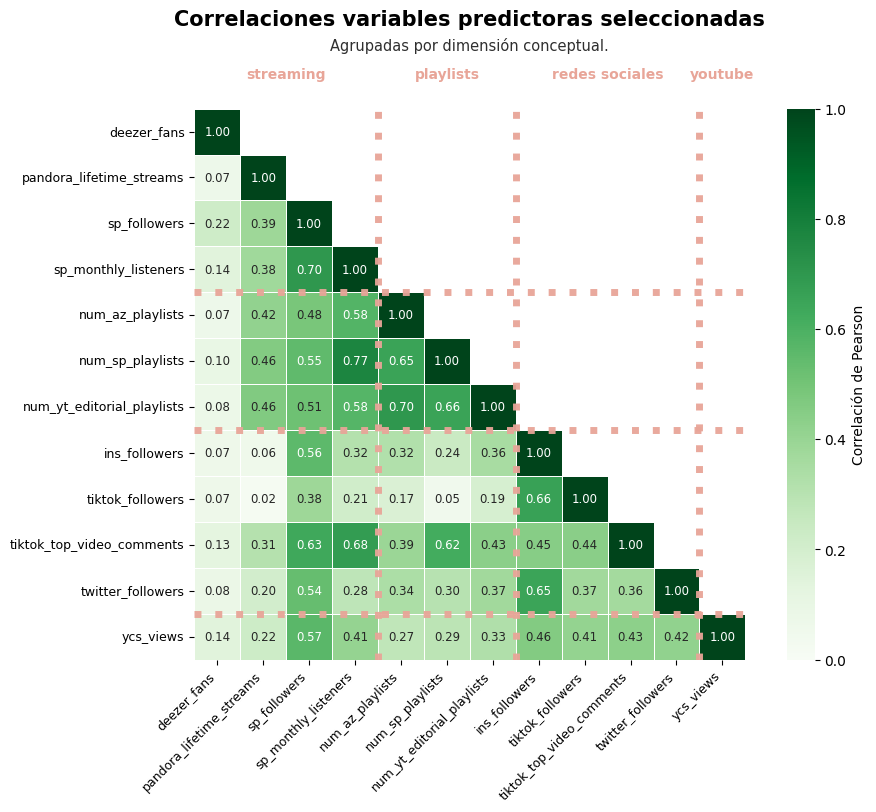

In [ ]:
# ============================================================
# Heatmap de correlaciones internas agrupado por dimensión
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Función auxiliar de dimensión
# ------------------------------------------------------------

def asignar_dimension(variable):
    if variable in streaming_cols:
        return "streaming"
    elif variable in playlist_cols:
        return "playlists"
    elif variable in social_cols:
        return "redes sociales"
    elif variable in youtube_cols:
        return "youtube"
    else:
        return "otra"

# ------------------------------------------------------------
# Orden conceptual de dimensiones
# ------------------------------------------------------------

orden_dimensiones = [
    "streaming",
    "playlists",
    "redes sociales",
    "youtube"
]

# ------------------------------------------------------------
# Tabla de orden del subset preliminar
# ------------------------------------------------------------

orden_variables_heatmap = pd.DataFrame({
    "variable": variables_regresion_preliminar
})

orden_variables_heatmap["dimension"] = (
    orden_variables_heatmap["variable"]
    .apply(asignar_dimension)
)

orden_variables_heatmap["orden_dimension"] = (
    orden_variables_heatmap["dimension"]
    .map({dim: i for i, dim in enumerate(orden_dimensiones)})
)

orden_variables_heatmap = (
    orden_variables_heatmap
    .sort_values(["orden_dimension", "variable"])
    .reset_index(drop=True)
)

variables_ordenadas = orden_variables_heatmap["variable"].tolist()

# ------------------------------------------------------------
# Preparación de variables transformadas
# ------------------------------------------------------------

df_heatmap_dim = df.copy()

vars_log_heatmap = [
    col for col in variables_ordenadas
    if col != "sp_popularity"
]

for col in vars_log_heatmap:
    df_heatmap_dim[f"log1p_{col}"] = np.log1p(df_heatmap_dim[col].astype(float))

vars_heatmap = [
    f"log1p_{col}" if col != "sp_popularity" else col
    for col in variables_ordenadas
]

labels_heatmap = [
    col.replace("log1p_", "")
    for col in vars_heatmap
]

# ------------------------------------------------------------
# Matriz de correlación
# ------------------------------------------------------------

corr_heatmap_dim = df_heatmap_dim[vars_heatmap].corr(method="pearson")

# ------------------------------------------------------------
# Máscara para mostrar solo triángulo inferior
# ------------------------------------------------------------

mask = np.triu(
    np.ones_like(corr_heatmap_dim, dtype=bool),
    k=1
)

# ------------------------------------------------------------
# Posiciones de cortes entre dimensiones
# ------------------------------------------------------------

conteo_dimensiones = (
    orden_variables_heatmap
    .groupby("dimension", sort=False)
    .size()
)

cortes = np.cumsum(conteo_dimensiones.values)[:-1]

# ------------------------------------------------------------
# Gráfico
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 9.5))

sns.heatmap(
    corr_heatmap_dim,
    mask=mask,
    cmap="Greens",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.6,
    linecolor="white",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8.5},
    cbar_kws={"label": "Correlación de Pearson"},
    xticklabels=labels_heatmap,
    yticklabels=labels_heatmap,
    ax=ax
)

# ------------------------------------------------------------
# Líneas separadoras entre dimensiones
# ------------------------------------------------------------

color_separador = "#E8A598"

for corte in cortes:
    ax.axhline(
        corte,
        color=color_separador,
        linewidth=5,
        linestyle=(0, (1, 2)),
        alpha=0.95
    )
    
    ax.axvline(
        corte,
        color=color_separador,
        linewidth=5,
        linestyle=(0, (1, 2)),
        alpha=0.95
    )

# ------------------------------------------------------------
# Título y subtítulo
# ------------------------------------------------------------

# ax.set_title(
#     "Correlaciones variables seleccionadas",
#     fontsize=15,
#     fontweight="bold",
#     pad=24,
#     loc="center"
# )

# ax.text(
#     0.5,
#     1.025,
#     "Agrupadas por dimensión conceptual",
#     transform=ax.transAxes,
#     ha="center",
#     va="bottom",
#     fontsize=10.5,
#     color="#2F2F2F"
# )

ax.set_title(
    "Correlaciones variables predictoras seleccionadas",
    fontsize=15,
    fontweight="bold",
    pad=60,
    loc="center"
)

ax.text(
    0.5,
    1.1,
    "Agrupadas por dimensión conceptual.",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10.5,
    color="#2F2F2F"
)


# ------------------------------------------------------------
# Etiquetas de dimensión sobre el eje superior
# ------------------------------------------------------------

inicio = 0

for dimension, cantidad in conteo_dimensiones.items():
    centro = inicio + cantidad / 2
    
    ax.text(
        centro,
        -0.75,
        dimension,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        color= color_separador
    )
    
    inicio += cantidad

# ------------------------------------------------------------
# Estética general
# ------------------------------------------------------------

ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.subplots_adjust(
    top=0.82,
    bottom=0.24,
    left=0.22,
    right=0.92
)

plt.savefig(
    "graficos/grafico_heatmap_correlaciones_subset.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



# Pares del subconjunto con la target

Registros disponibles para pairplot: 2941
Variables incluidas: 13


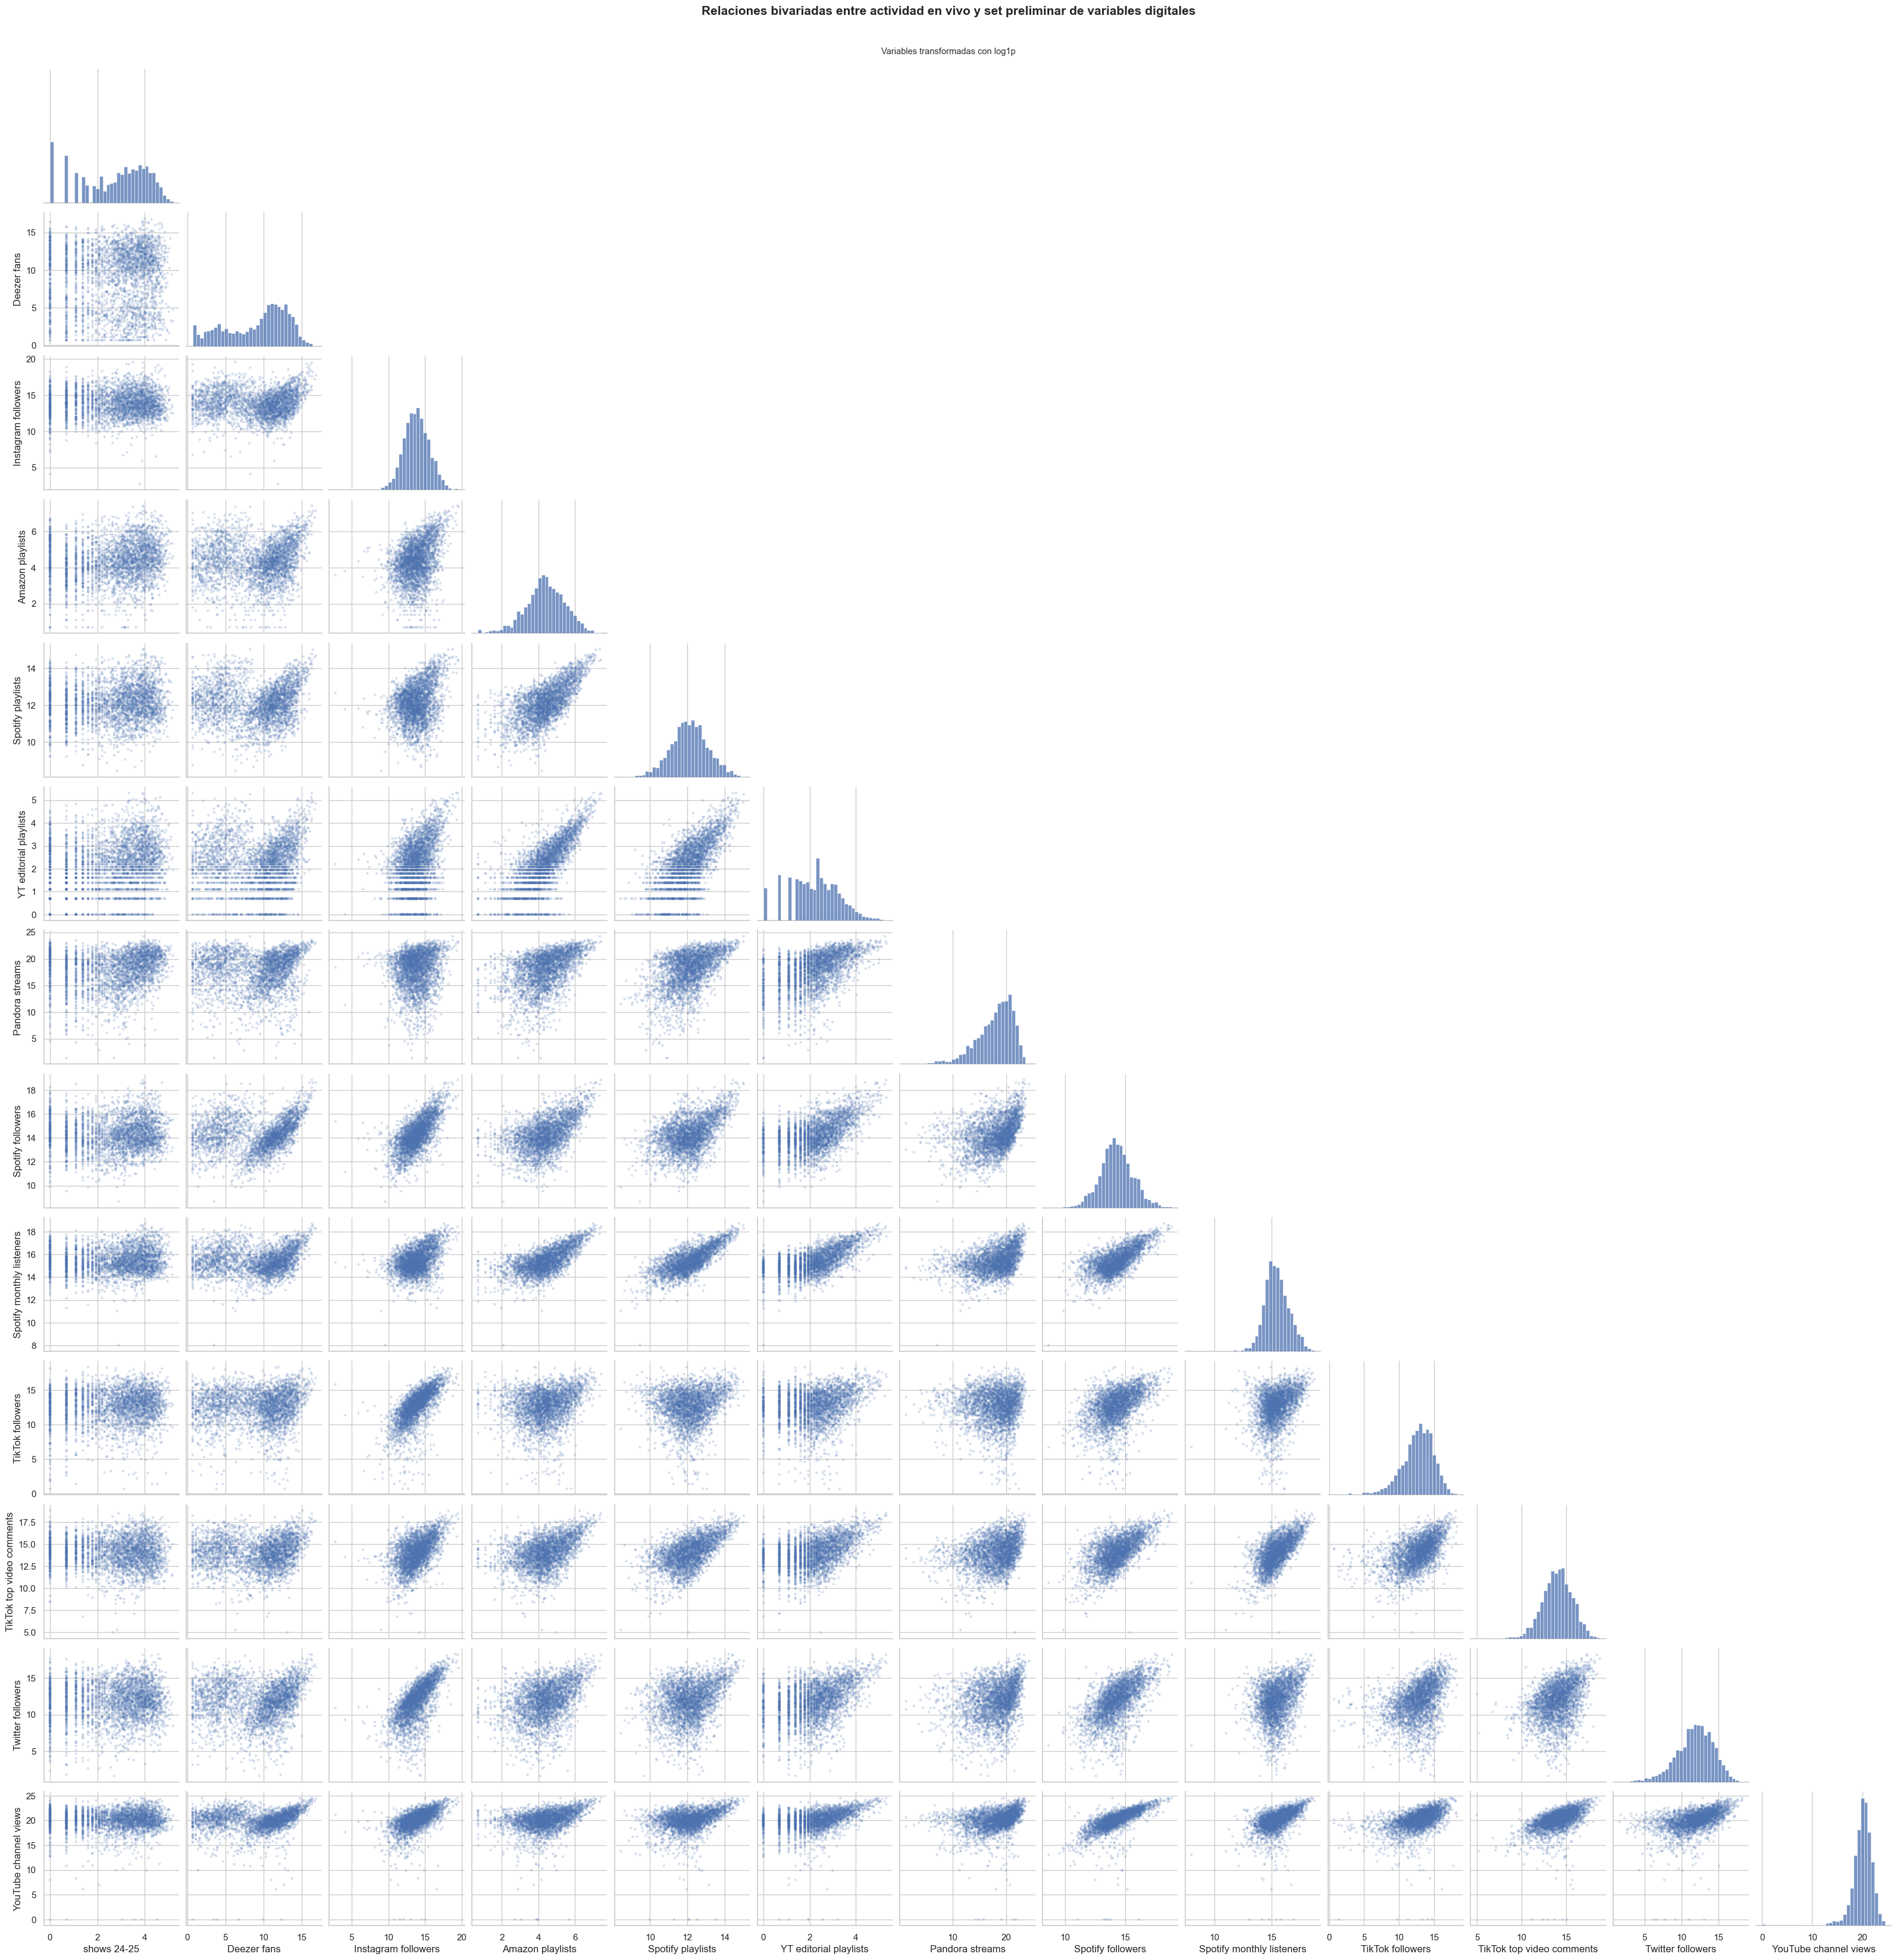

In [ ]:
# ============================================================
# Pairplot completo del set preliminar con target transformada
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Definición de target y variables
# ------------------------------------------------------------

target = "n_shows_24_25"

variables_pairplot = variables_regresion_preliminar.copy()

# ------------------------------------------------------------
# Preparación de dataframe transformado
# ------------------------------------------------------------

df_pair = df[[target] + variables_pairplot].copy()

df_pair["log1p_n_shows_24_25"] = np.log1p(df_pair[target].astype(float))

for col in variables_pairplot:
    if col == "sp_popularity":
        df_pair[col] = df_pair[col].astype(float)
    else:
        df_pair[f"log1p_{col}"] = np.log1p(df_pair[col].astype(float))

vars_pairplot_transformadas = ["log1p_n_shows_24_25"]

for col in variables_pairplot:
    if col == "sp_popularity":
        vars_pairplot_transformadas.append(col)
    else:
        vars_pairplot_transformadas.append(f"log1p_{col}")

df_pair_plot = df_pair[vars_pairplot_transformadas].dropna().copy()

print("Registros disponibles para pairplot:", df_pair_plot.shape[0])
print("Variables incluidas:", df_pair_plot.shape[1])

# ------------------------------------------------------------
# Etiquetas limpias
# ------------------------------------------------------------

labels_pairplot = {
    "log1p_n_shows_24_25": "shows 24-25",
    "log1p_deezer_fans": "Deezer fans",
    "log1p_ins_followers": "Instagram followers",
    "log1p_num_az_playlists": "Amazon playlists",
    "log1p_num_sp_playlists": "Spotify playlists",
    "log1p_num_yt_editorial_playlists": "YT editorial playlists",
    "log1p_pandora_lifetime_streams": "Pandora streams",
    "log1p_sp_followers": "Spotify followers",
    "log1p_sp_monthly_listeners": "Spotify monthly listeners",
    "log1p_tiktok_followers": "TikTok followers",
    "log1p_tiktok_top_video_comments": "TikTok top video comments",
    "log1p_twitter_followers": "Twitter followers",
    "log1p_ycs_views": "YouTube channel views",
    "sp_popularity": "Spotify popularity"
}

df_pair_plot = df_pair_plot.rename(columns=labels_pairplot)

# ------------------------------------------------------------
# Pairplot
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

g = sns.pairplot(
    df_pair_plot,
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.22,
        "s": 10,
        "edgecolor": "none"
    },
    diag_kws={
        "bins": 35,
        "edgecolor": "white",
        "linewidth": 0.4
    }
)

g.fig.suptitle(
    "Relaciones bivariadas entre actividad en vivo y set preliminar de variables digitales",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

g.fig.text(
    0.5,
    0.995,
    "Variables transformadas con log1p",
    ha="center",
    fontsize=10.5,
    color="#2F2F2F"
)

plt.savefig(
    "grafico_pairplot_subset_target.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Registros disponibles para pairplot: 4390
Variables incluidas: 7


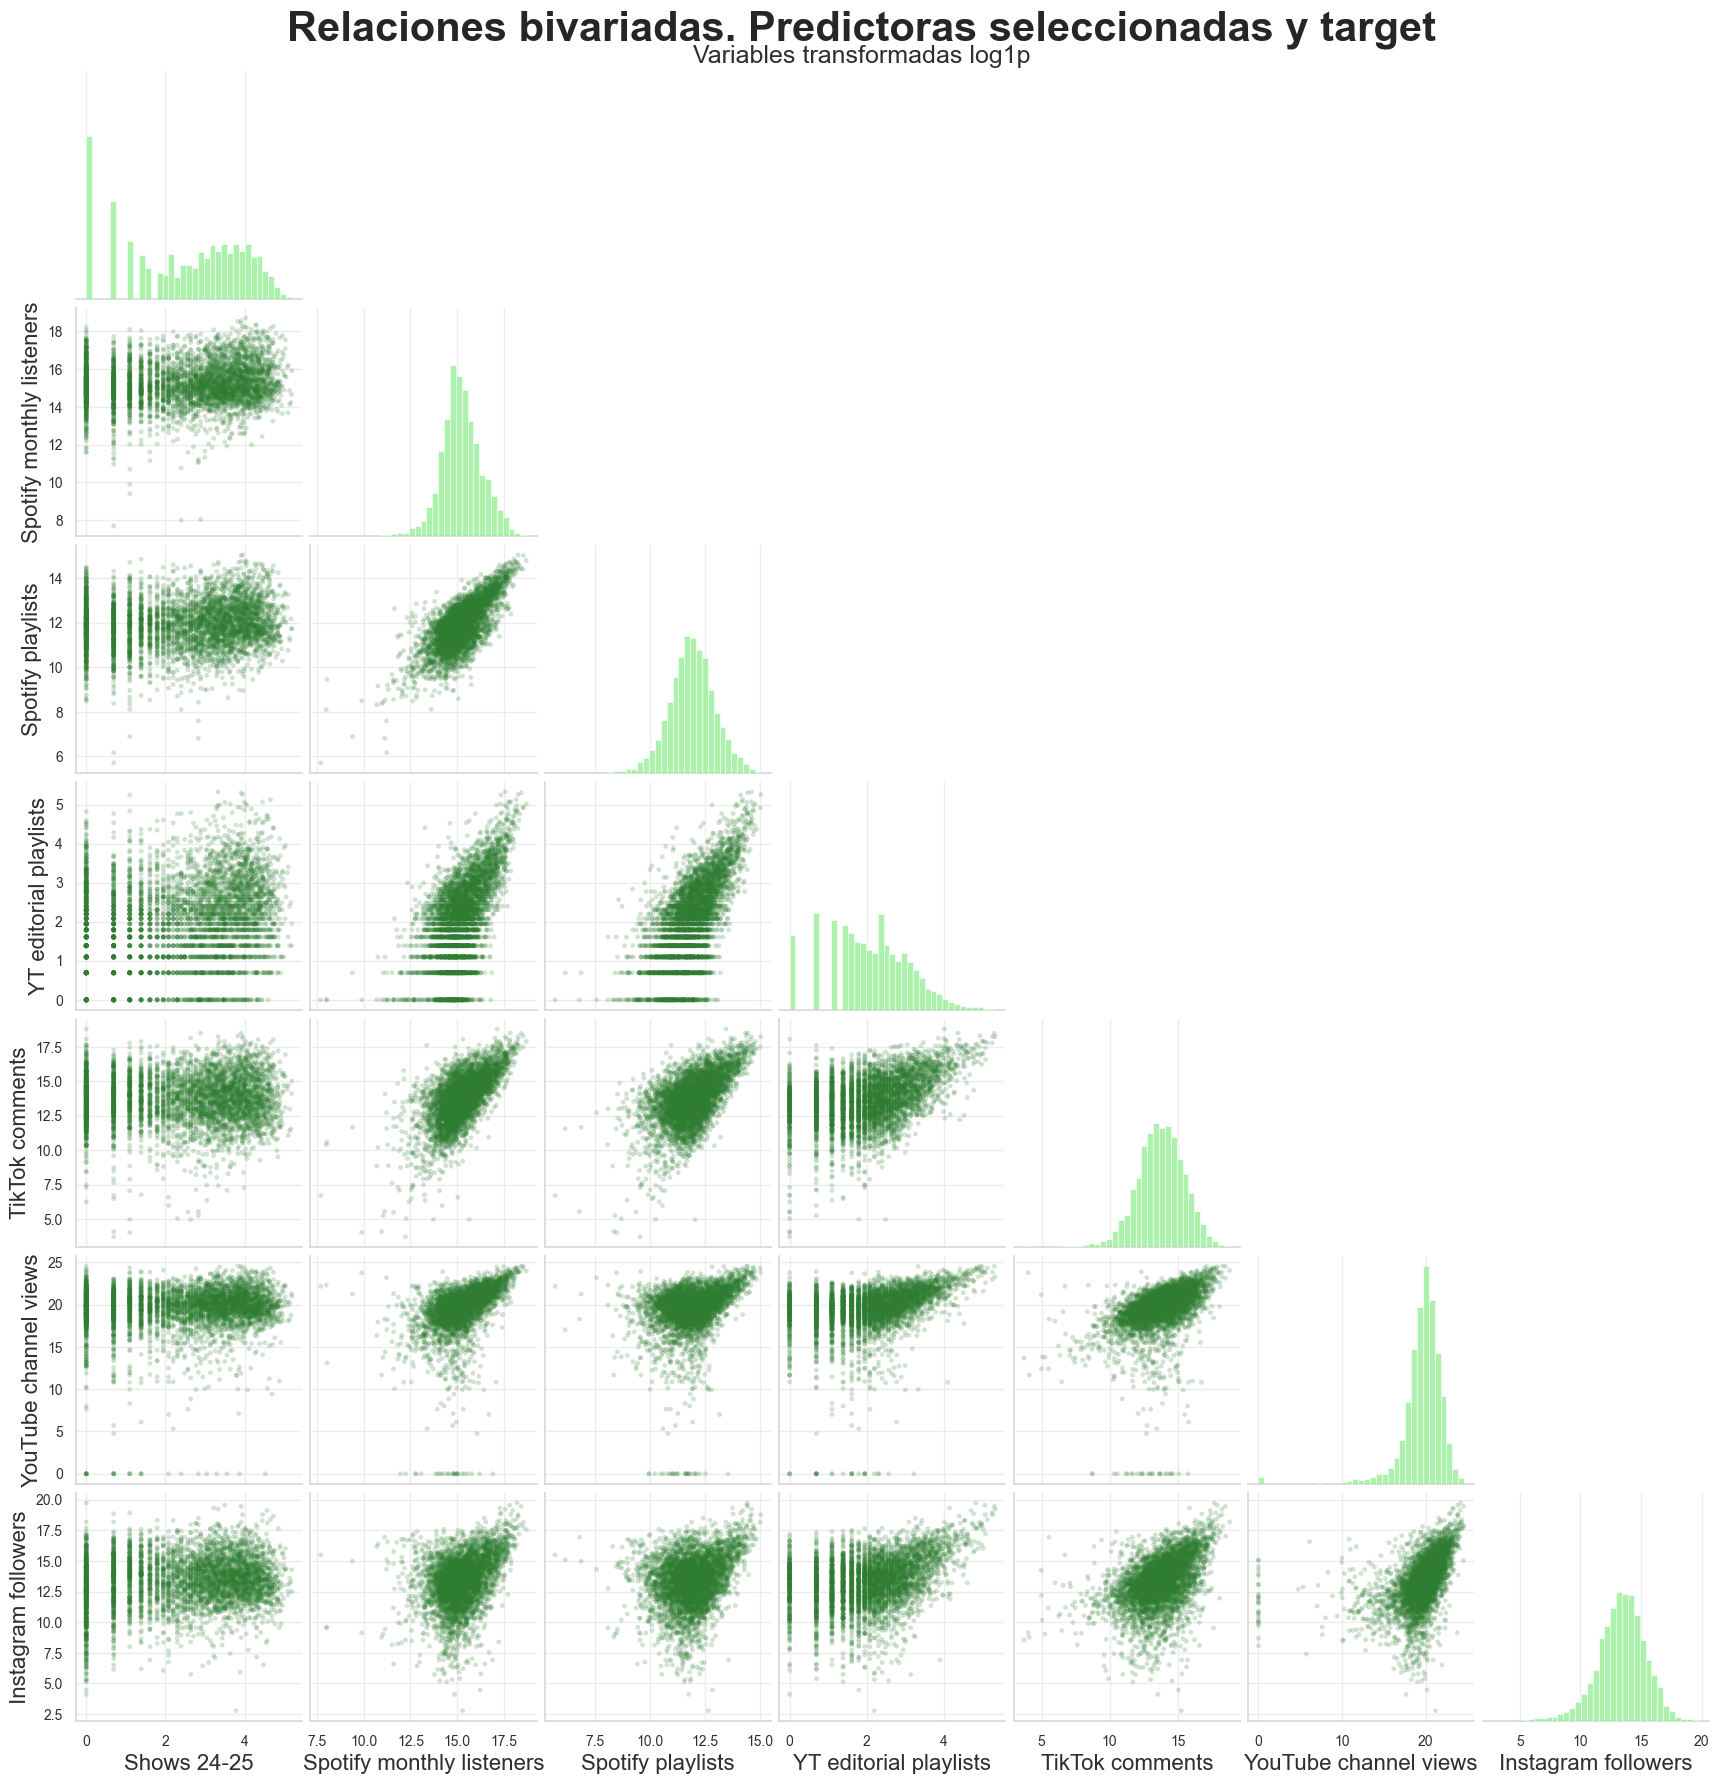

In [143]:
# ============================================================
# Pairplot curado sobre subset preliminar + target + Instagram
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Dataframe base
# ------------------------------------------------------------

df_base = df.copy()  # reemplazar df por el nombre del dataframe de trabajo si corresponde

# ------------------------------------------------------------
# Target y variables seleccionadas
# ------------------------------------------------------------

target = "n_shows_24_25"

variables_pairplot = [
    "sp_monthly_listeners",
    "num_sp_playlists",
    "num_yt_editorial_playlists",
    "tiktok_top_video_comments",
    "ycs_views",
    "ins_followers"
]

# ------------------------------------------------------------
# Control de existencia de columnas
# ------------------------------------------------------------

columnas_necesarias = [target] + variables_pairplot

columnas_faltantes = [
    col for col in columnas_necesarias
    if col not in df_base.columns
]

if len(columnas_faltantes) > 0:
    raise ValueError(f"Columnas faltantes en el dataframe: {columnas_faltantes}")

# ------------------------------------------------------------
# Preparación de dataframe transformado
# ------------------------------------------------------------

df_pair = pd.DataFrame()

df_pair["log1p_n_shows_24_25"] = np.log1p(
    df_base[target].astype(float)
)

for col in variables_pairplot:
    df_pair[f"log1p_{col}"] = np.log1p(
        df_base[col].astype(float)
    )

df_pair_plot = df_pair.dropna().copy()

print("Registros disponibles para pairplot:", df_pair_plot.shape[0])
print("Variables incluidas:", df_pair_plot.shape[1])

# ------------------------------------------------------------
# Etiquetas limpias
# ------------------------------------------------------------

labels_pairplot = {
    "log1p_n_shows_24_25": "Shows 24-25",
    "log1p_sp_monthly_listeners": "Spotify monthly listeners",
    "log1p_num_sp_playlists": "Spotify playlists",
    "log1p_num_yt_editorial_playlists": "YT editorial playlists",
    "log1p_tiktok_top_video_comments": "TikTok comments",
    "log1p_ycs_views": "YouTube channel views",
    "log1p_ins_followers": "Instagram followers"
}

df_pair_plot = df_pair_plot.rename(columns=labels_pairplot)

# ------------------------------------------------------------
# Estilo visual
# ------------------------------------------------------------

color_verde = "#90EE90"
color_puntos = "#2E7D32"

sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#D8D8D8",
        "grid.color": "#ECECEC",
        "axes.labelcolor": "#2F2F2F",
        "xtick.color": "#2F2F2F",
        "ytick.color": "#2F2F2F"
    }
)

# ------------------------------------------------------------
# Pairplot
# ------------------------------------------------------------

g = sns.pairplot(
    df_pair_plot,
    corner=True,
    diag_kind="hist",
    plot_kws={
        "alpha": 0.22,
        "s": 12,
        "edgecolor": "none",
        "color": color_puntos
    },
    diag_kws={
        "bins": 35,
        "edgecolor": "white",
        "linewidth": 0.4,
        "color": color_verde
    }
)

# ------------------------------------------------------------
# Título y subtítulo
# ------------------------------------------------------------

g.fig.suptitle(
    "Relaciones bivariadas. Predictoras seleccionadas y target",
    fontsize=30,
    fontweight="bold",
    y=1.02
)

g.fig.text(
    0.5,
    0.99,
    "Variables transformadas log1p",
    ha="center",
    fontsize=18,
    color="#2F2F2F"
)

# ------------------------------------------------------------
# Ajustes de etiquetas
# ------------------------------------------------------------

for ax in g.axes.flatten():
    if ax is not None:
        ax.tick_params(axis="both", labelsize=10)
        ax.set_xlabel(ax.get_xlabel(), fontsize=16)
        ax.set_ylabel(ax.get_ylabel(), fontsize=16)

# ------------------------------------------------------------
# Exportación
# ------------------------------------------------------------


ruta_pairplot_small = (
    directorio_salidas_proyecto /
    "grafico_pairplot_subsubset_target.png"
)

plt.savefig(
    ruta_pairplot_small,
    dpi=300,
    bbox_inches="tight", facecolor="white"
)


plt.show()

# Pares altamente correlacionados conservados

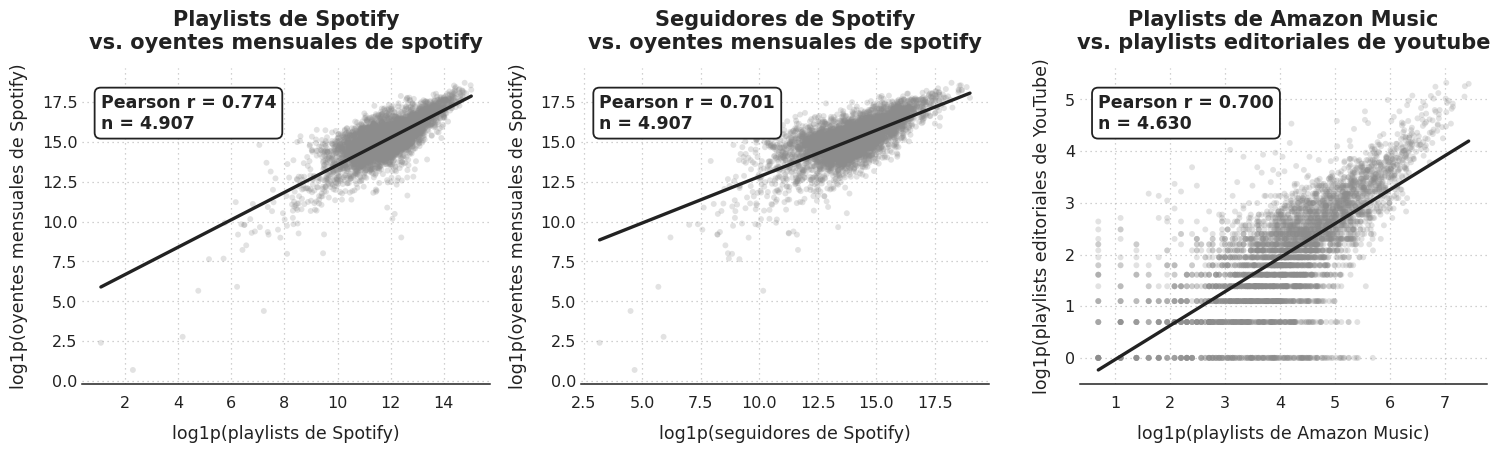

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\digital_metric_redundancy_pairs.png


In [170]:
# ============================================================
# Pares de métricas digitales altamente correlacionadas
# Construido a partir de corr_subset_pairs_altas, no hardcodeado
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Estética general del informe
# ------------------------------------------------------------

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

color_puntos = "#8C8C8C"
color_linea = "#222222"
color_recuadro = "#222222"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Etiquetas legibles por variable (única fuente a mantener a mano)
# ------------------------------------------------------------

etiquetas_variables = {
    "sp_monthly_listeners": "oyentes mensuales de Spotify",
    "num_sp_playlists": "playlists de Spotify",
    "sp_followers": "seguidores de Spotify",
    "num_az_playlists": "playlists de Amazon Music",
    "num_yt_editorial_playlists": "playlists editoriales de YouTube",
    "sp_popularity": "popularidad en Spotify",
}

def etiqueta_legible(nombre_variable):
    base = etiquetas_variables.get(nombre_variable, nombre_variable.replace("_", " "))
    if nombre_variable == "sp_popularity":
        return base
    return f"log1p({base})"

def titulo_legible(nombre_variable):
    base = etiquetas_variables.get(nombre_variable, nombre_variable.replace("_", " "))
    return base[0].upper() + base[1:]

# ------------------------------------------------------------
# Pares construidos dinámicamente desde corr_subset_pairs_altas
# ------------------------------------------------------------

pares_redundancia = []

for _, fila in corr_subset_pairs_altas.iterrows():
    var_x = fila["variable_1"]
    var_y = fila["variable_2"]

    pares_redundancia.append({
        "x": var_x,
        "y": var_y,
        "x_label": etiqueta_legible(var_x),
        "y_label": etiqueta_legible(var_y),
        "titulo": f"{titulo_legible(var_x)}\nvs. {titulo_legible(var_y).lower()}"
    })

# ------------------------------------------------------------
# Función auxiliar para transformar variables
# ------------------------------------------------------------

def transformar_variable_para_redundancia(serie, nombre_variable):
    serie_num = pd.to_numeric(serie, errors="coerce").astype("float64")

    if nombre_variable == "sp_popularity":
        return serie_num

    return np.log1p(serie_num)

# ------------------------------------------------------------
# Figura: 1 fila x N columnas, según cantidad real de pares
# ------------------------------------------------------------

n_pares = len(pares_redundancia)
n_cols = min(n_pares, 3)
n_filas = int(np.ceil(n_pares / n_cols))

fig, axes = plt.subplots(n_filas, n_cols, figsize=(5.2 * n_cols, 5.1 * n_filas))
fig.patch.set_facecolor(color_fondo)

axes_flat = np.atleast_1d(axes).flatten()

for ax, par in zip(axes_flat, pares_redundancia):

    x_transformada = transformar_variable_para_redundancia(df[par["x"]], par["x"])
    y_transformada = transformar_variable_para_redundancia(df[par["y"]], par["y"])

    df_par = (
        pd.DataFrame({"x": x_transformada, "y": y_transformada})
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .astype("float64")
        .copy()
    )

    r_pearson = df_par["x"].corr(df_par["y"])
    n_par = len(df_par)

    ax.set_facecolor(color_fondo)

    ax.scatter(
        df_par["x"], df_par["y"],
        s=18, color=color_puntos, alpha=0.25, edgecolor="none", zorder=2
    )

    x_vals = df_par["x"].to_numpy(dtype="float64")
    y_vals = df_par["y"].to_numpy(dtype="float64")

    pendiente, intercepto = np.polyfit(x_vals, y_vals, deg=1)
    x_linea = np.linspace(x_vals.min(), x_vals.max(), 200)
    y_linea = pendiente * x_linea + intercepto

    ax.plot(x_linea, y_linea, color=color_linea, linewidth=2.4, zorder=3)

    ax.text(
        0.045, 0.92,
        f"Pearson r = {r_pearson:.3f}\nn = {n_par:,}".replace(",", "."),
        transform=ax.transAxes, ha="left", va="top",
        fontsize=12.5, fontweight="bold", color=color_texto,
        bbox=dict(boxstyle="round,pad=0.35", facecolor=color_fondo,
                  edgecolor=color_recuadro, linewidth=1.3),
        zorder=4
    )

    ax.set_title(par["titulo"], fontsize=15, fontweight="bold", color=color_texto, pad=14)
    ax.set_xlabel(par["x_label"], fontsize=12.5, color=color_texto, labelpad=10)
    ax.set_ylabel(par["y_label"], fontsize=12.5, color=color_texto, labelpad=10)

    ax.grid(axis="both", linestyle=(0, (1, 3)), linewidth=0.9, color=color_grilla, alpha=0.95)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color(color_texto)
    ax.spines["bottom"].set_linewidth(1.1)

    ax.tick_params(axis="x", length=5, width=1, color=color_texto,
                    labelsize=11.5, labelcolor=color_texto)
    ax.tick_params(axis="y", length=0, labelsize=11.5, colors=color_texto)

# Apagar ejes sobrantes si n_pares no completa la grilla
for ax_sobrante in axes_flat[n_pares:]:
    ax_sobrante.set_visible(False)

plt.tight_layout(rect=[0.03, 0.03, 1, 0.95])

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

ruta_redundancia_digital = (
    directorio_salidas_proyecto / "digital_metric_redundancy_pairs.png"
)

plt.savefig(
    ruta_redundancia_digital,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_redundancia_digital}")

# EDA de conciertos

In [93]:
# ============================================================
# Resumen descriptivo de variables de actividad en vivo
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Variables live a revisar
# ------------------------------------------------------------

live_vars = [
    "n_shows_24_25",
    "capacity_24_25",
    "avg_venue_capacity_24_25",
    "shows_per_country_24_25",
    "n_shows_with_capacity_24_25",
    "n_cities_24_25",
    "n_countries_24_25"
]

live_vars = [
    col for col in live_vars
    if col in df.columns
]

# ------------------------------------------------------------
# Tabla descriptiva
# ------------------------------------------------------------

resumen_live = []

for col in live_vars:
    s = df[col].dropna().astype(float)
    
    resumen_live.append({
        "variable": col,
        "n": s.shape[0],
        "n_null": df[col].isna().sum(),
        "pct_null": df[col].isna().mean() * 100,
        "media": s.mean(),
        "p50": s.quantile(0.50),
        "p75": s.quantile(0.75),
        "p90": s.quantile(0.90),
        "p95": s.quantile(0.95),
        "p99": s.quantile(0.99),
        "max": s.max()
    })

resumen_live = pd.DataFrame(resumen_live)

resumen_live = resumen_live.round({
    "pct_null": 2,
    "media": 2,
    "p50": 2,
    "p75": 2,
    "p90": 2,
    "p95": 2,
    "p99": 2,
    "max": 2
})

resumen_live

,variable,n,n_null,pct_null,media,p50,p75,p90,p95,p99,max
0,n_shows_24_25,4913,0,0.00,24.30,13.00,38.00,68.00,86.00,124.00,179.0
1,capacity_24_25,4730,183,3.72,166325.52,35048.50,169594.00,501750.60,808735.95,1553556.77,4167910.0
2,avg_venue_capacity_24_25,3870,1043,21.23,7062.28,4165.65,9196.86,15803.25,19574.59,47073.19,130975.0
3,shows_per_country_24_25,4025,888,18.07,10.06,5.00,11.00,25.00,37.00,75.00,170.0
4,n_shows_with_capacity_24_25,4913,0,0.00,20.32,8.00,31.00,60.00,78.00,112.00,160.0
5,n_cities_24_25,4913,0,0.00,18.09,9.00,28.00,51.00,66.00,93.00,140.0
6,n_countries_24_25,4913,0,0.00,3.52,2.00,4.00,10.00,13.00,19.00,31.0


In [94]:
# ============================================================
# Correlaciones entre variables de actividad en vivo
# ============================================================

df_live_corr = df.copy()

# ------------------------------------------------------------
# Transformación log1p para variables live numéricas
# ------------------------------------------------------------

for col in live_vars:
    df_live_corr[f"log1p_{col}"] = np.log1p(
        df_live_corr[col].astype(float)
    )

live_corr_vars = [
    f"log1p_{col}"
    for col in live_vars
]

corr_live = df_live_corr[live_corr_vars].corr(method="pearson")

corr_live_limpia = corr_live.copy()

corr_live_limpia.index = [
    idx.replace("log1p_", "")
    for idx in corr_live_limpia.index
]

corr_live_limpia.columns = [
    col.replace("log1p_", "")
    for col in corr_live_limpia.columns
]

corr_live_limpia.round(3)

,n_shows_24_25,capacity_24_25,avg_venue_capacity_24_25,shows_per_country_24_25,n_shows_with_capacity_24_25,n_cities_24_25,n_countries_24_25
n_shows_24_25,1.000,0.894,0.297,0.718,0.977,0.984,0.787
capacity_24_25,0.894,1.000,0.750,0.556,0.877,0.878,0.761
avg_venue_capacity_24_25,0.297,0.750,1.000,0.170,0.276,0.284,0.221
shows_per_country_24_25,0.718,0.556,0.170,1.000,0.684,0.677,-0.107
n_shows_with_capacity_24_25,0.977,0.877,0.276,0.684,1.000,0.971,0.769
n_cities_24_25,0.984,0.878,0.284,0.677,0.971,1.000,0.788
n_countries_24_25,0.787,0.761,0.221,-0.107,0.769,0.788,1.000


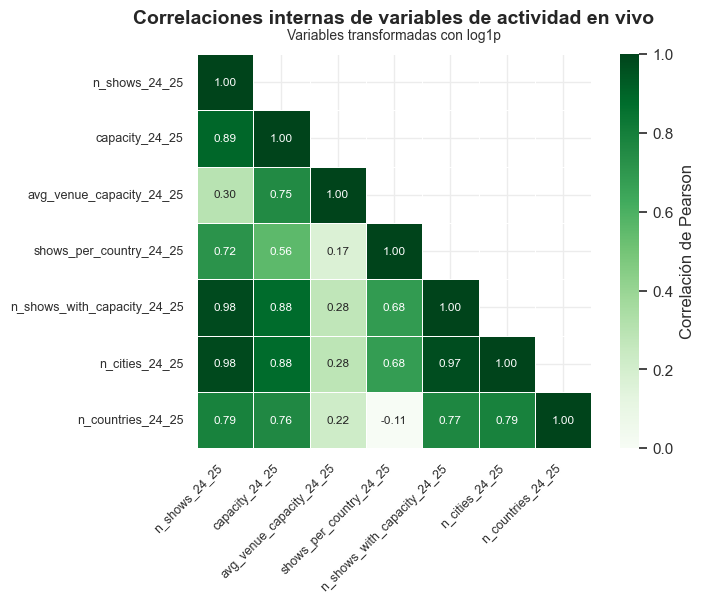

In [95]:
# ============================================================
# Heatmap de correlaciones entre variables live
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

mask = np.triu(
    np.ones_like(corr_live_limpia, dtype=bool),
    k=1
)

fig, ax = plt.subplots(figsize=(8.5, 6.8))

sns.heatmap(
    corr_live_limpia,
    mask=mask,
    cmap="Greens",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.6,
    linecolor="white",
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 8.5},
    cbar_kws={"label": "Correlación de Pearson"},
    ax=ax
)

ax.set_title(
    "Correlaciones internas de variables de actividad en vivo",
    fontsize=14,
    fontweight="bold",
    pad=22,
    loc="center"
)

ax.text(
    0.5,
    1.03,
    "Variables transformadas con log1p",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=10,
    color="#2F2F2F"
)

ax.tick_params(axis="x", rotation=45, labelsize=9)
ax.tick_params(axis="y", rotation=0, labelsize=9)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

plt.subplots_adjust(
    top=0.84,
    bottom=0.26,
    left=0.25,
    right=0.92
)

plt.savefig(
    "heatmap_correlaciones_live_events.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Cruces de categóricas

In [96]:
# ============================================================
# Cruces descriptivos entre target y variables categóricas
# ============================================================

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Dataframe base
# ------------------------------------------------------------

df_eda_cat = df.copy()

df_eda_cat["log1p_n_shows_24_25"] = np.log1p(
    df_eda_cat["n_shows_24_25"].astype(float)
)

# ------------------------------------------------------------
# Variables categóricas agrupadas
# ------------------------------------------------------------

categoricas_eda = [
    "country_short",
    "genre_short",
    "pronoun_short",
    "band",
    "major_record_label"
]

categoricas_eda = [
    col for col in categoricas_eda
    if col in df_eda_cat.columns
]

# ------------------------------------------------------------
# Tabla resumen por categoría
# ------------------------------------------------------------

resumen_categoricas = []

for cat in categoricas_eda:
    tabla_cat = (
        df_eda_cat
        .groupby(cat, observed=True)
        .agg(
            n_artistas=("n_shows_24_25", "size"),
            shows_media=("n_shows_24_25", "mean"),
            shows_mediana=("n_shows_24_25", "median"),
            shows_p75=("n_shows_24_25", lambda x: x.quantile(0.75)),
            shows_p90=("n_shows_24_25", lambda x: x.quantile(0.90)),
            log_shows_media=("log1p_n_shows_24_25", "mean"),
            log_shows_mediana=("log1p_n_shows_24_25", "median"),
            pct_cero=("n_shows_24_25", lambda x: (x == 0).mean() * 100)
        )
        .reset_index()
        .rename(columns={cat: "categoria"})
    )
    
    tabla_cat.insert(0, "variable", cat)
    
    resumen_categoricas.append(tabla_cat)

resumen_categoricas = pd.concat(
    resumen_categoricas,
    ignore_index=True
)

resumen_categoricas = resumen_categoricas.round({
    "shows_media": 2,
    "shows_mediana": 2,
    "shows_p75": 2,
    "shows_p90": 2,
    "log_shows_media": 3,
    "log_shows_mediana": 3,
    "pct_cero": 2
})

resumen_categoricas

,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,country_short,Africa & ME,193,15.62,6.0,22.0,43.8,1.998,1.946,13.47
1,country_short,Asia & Oceania,363,17.82,9.0,26.0,49.0,2.097,2.303,18.18
2,country_short,Europe_sinGB,749,15.68,7.0,21.0,45.0,1.962,2.079,20.16
3,country_short,Great Britain,578,23.36,14.0,36.75,62.0,2.384,2.708,15.92
4,country_short,LATAM,778,16.36,8.0,25.0,46.0,2.081,2.197,14.27
5,country_short,North America,2248,31.98,21.0,53.0,84.0,2.576,3.091,18.33
6,genre_short,Alternative & indie,349,35.82,29.0,56.0,79.2,2.969,3.401,8.02
7,genre_short,Country & folk,265,55.18,52.0,87.0,108.0,3.391,3.970,12.83
8,genre_short,Electronic & dance,642,18.96,11.0,26.75,53.9,2.230,2.485,11.84
9,genre_short,Hip-hop & trap,658,19.48,9.0,29.0,52.6,2.213,2.303,13.83


In [97]:
# ============================================================
# Vista ordenada por variable categórica
# ============================================================

for cat in categoricas_eda:
    print("\n" + "=" * 70)
    print(cat)
    print("=" * 70)
    
    display(
        resumen_categoricas[
            resumen_categoricas["variable"] == cat
        ]
        .sort_values("log_shows_mediana", ascending=False)
        .reset_index(drop=True)
    )


country_short


,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,country_short,North America,2248,31.98,21.0,53.0,84.0,2.576,3.091,18.33
1,country_short,Great Britain,578,23.36,14.0,36.75,62.0,2.384,2.708,15.92
2,country_short,Asia & Oceania,363,17.82,9.0,26.0,49.0,2.097,2.303,18.18
3,country_short,LATAM,778,16.36,8.0,25.0,46.0,2.081,2.197,14.27
4,country_short,Europe_sinGB,749,15.68,7.0,21.0,45.0,1.962,2.079,20.16
5,country_short,Africa & ME,193,15.62,6.0,22.0,43.8,1.998,1.946,13.47



genre_short


,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,genre_short,Country & folk,265,55.18,52.0,87.0,108.0,3.391,3.970,12.83
1,genre_short,Rock & metal,514,38.02,31.5,63.0,91.7,2.695,3.481,22.37
2,genre_short,Alternative & indie,349,35.82,29.0,56.0,79.2,2.969,3.401,8.02
3,genre_short,Regional mexicano,197,26.13,17.0,41.0,68.2,2.537,2.890,16.24
4,genre_short,"R&b, soul & funk",375,24.46,16.0,39.0,61.6,2.423,2.833,16.8
5,genre_short,Electronic & dance,642,18.96,11.0,26.75,53.9,2.230,2.485,11.84
6,genre_short,Pop,944,22.1,10.0,32.0,63.7,2.186,2.398,22.25
7,genre_short,Hip-hop & trap,658,19.48,9.0,29.0,52.6,2.213,2.303,13.83
8,genre_short,Latin & urban,480,14.78,8.0,23.25,42.0,2.042,2.197,13.96
9,genre_short,Miscellaneous,58,17.88,7.5,26.75,48.0,2.096,2.138,12.07



pronoun_short


,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,pronoun_short,Non-Binary/Diverse,12,35.25,33.5,57.5,75.5,2.989,3.502,8.33
1,pronoun_short,they/them,1492,28.96,17.0,48.0,77.0,2.488,2.890,18.5
2,pronoun_short,she/her,879,20.9,11.0,32.0,55.0,2.312,2.485,12.29
3,pronoun_short,he/him,2530,22.68,10.0,33.0,64.0,2.225,2.398,18.77



band


,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,band,True,1570,28.75,17.0,48.0,77.0,2.484,2.890,18.28
1,band,False,3343,22.21,10.0,33.0,62.0,2.246,2.398,17.14



major_record_label


,variable,categoria,n_artistas,shows_media,shows_mediana,shows_p75,shows_p90,log_shows_media,log_shows_mediana,pct_cero
0,major_record_label,True,1383,28.17,18.0,45.0,74.0,2.571,2.944,13.96
1,major_record_label,False,3221,23.51,11.0,36.0,67.0,2.285,2.485,17.32


C:\Users\Silvana\AppData\Local\Temp\ipykernel_27124\1910963600.py:194: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  resultado_boxplot = ax.boxplot(
C:\Users\Silvana\AppData\Local\Temp\ipykernel_27124\1910963600.py:194: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  resultado_boxplot = ax.boxplot(
C:\Users\Silvana\AppData\Local\Temp\ipykernel_27124\1910963600.py:194: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  resultado_boxplot = ax.boxplot(


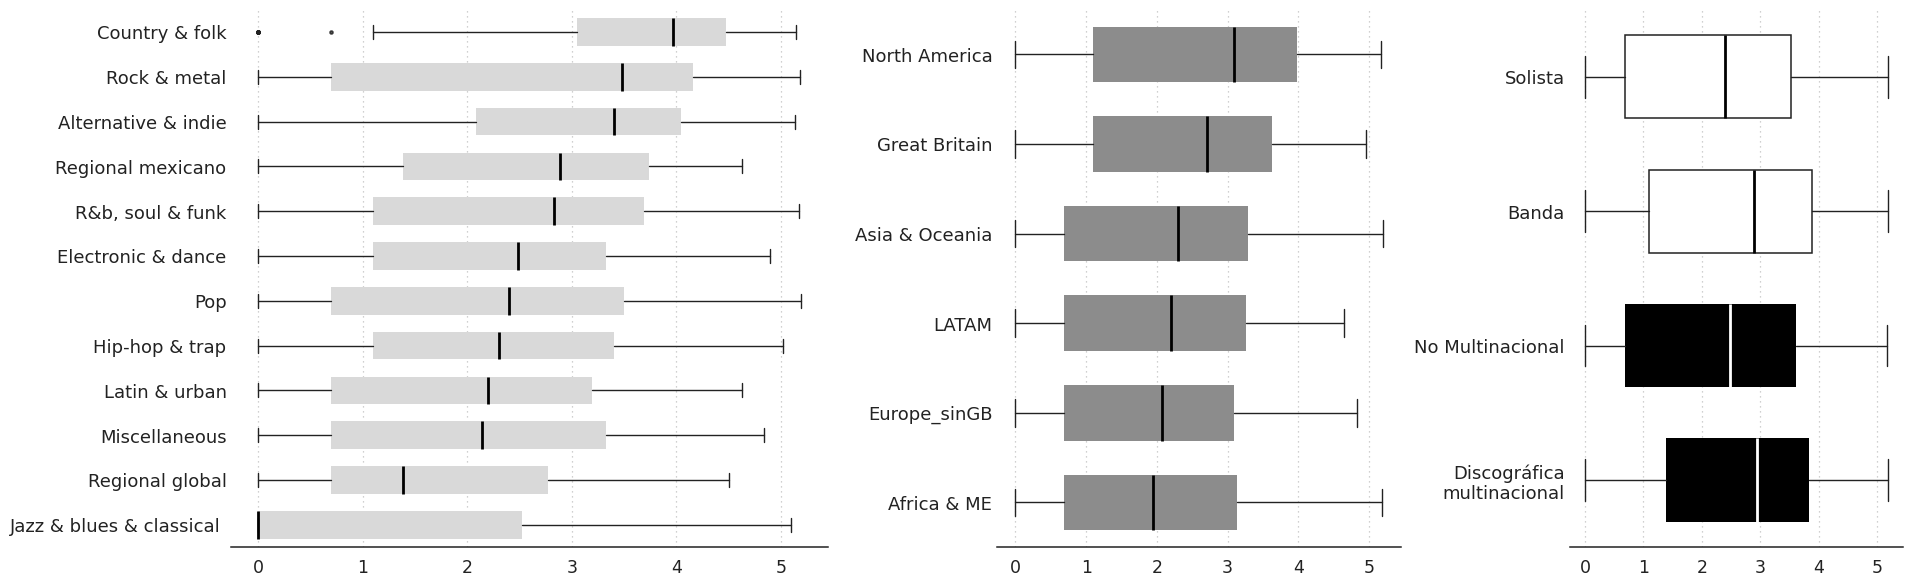

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\grafico_categoricas_target_byn.png


In [ ]:
# ============================================================
# Cruces entre actividad en vivo y variables categóricas
# Boxplots en escala de grises
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ------------------------------------------------------------
# Dataframe base
# ------------------------------------------------------------

df_cat_plot = df.copy()

df_cat_plot["log1p_n_shows_24_25"] = np.log1p(
    df_cat_plot["n_shows_24_25"].astype(float)
)

# ------------------------------------------------------------
# Paleta y estilo general
# ------------------------------------------------------------

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"

color_genero = "#D9D9D9"
color_region = "#8C8C8C"
color_formato = "#FFFFFF"
color_discografica = "#000000"

color_mediana = "#333333"


plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Órdenes por mediana de actividad en vivo
# ------------------------------------------------------------

orden_genero = (
    df_cat_plot
    .groupby("genre_short", observed=True)["log1p_n_shows_24_25"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

orden_region = (
    df_cat_plot
    .groupby("country_short", observed=True)["log1p_n_shows_24_25"]
    .median()
    .sort_values(ascending=False)
    .index
    .tolist()
)

# ------------------------------------------------------------
# Preparación de datos para boxplots
# ------------------------------------------------------------

datos_genero = [
    df_cat_plot.loc[
        df_cat_plot["genre_short"] == categoria,
        "log1p_n_shows_24_25"
    ].dropna().to_numpy()
    for categoria in orden_genero
]

datos_region = [
    df_cat_plot.loc[
        df_cat_plot["country_short"] == categoria,
        "log1p_n_shows_24_25"
    ].dropna().to_numpy()
    for categoria in orden_region
]

# df_binarias = df_cat_plot[
#     ["log1p_n_shows_24_25", "band", "major_record_label"]
# ].copy()

# df_binarias["band"] = df_binarias["band"].map({
#     True: "Band",
#     False: "Solo artist"
# })

# df_binarias["major_record_label"] = df_binarias["major_record_label"].map({
#     True: "Major label",
#     False: "No major"
# })

# df_binarias_largo = df_binarias.melt(
#     id_vars="log1p_n_shows_24_25",
#     value_vars=["band", "major_record_label"],
#     var_name="variable",
#     value_name="categoria"
# )

# orden_binarias = [
#     "Solo artist",
#     "Band",
#     "No major",
#     "Major label"
# ]

# datos_binarias = [
#     df_binarias_largo.loc[
#         df_binarias_largo["categoria"] == categoria,
#         "log1p_n_shows_24_25"
#     ].dropna().to_numpy()
#     for categoria in orden_binarias
# ]


# ------------------------------------------------------------
# Preparación de datos para boxplots (Variables Binarias)
# ------------------------------------------------------------

df_binarias = df_cat_plot[
    ["log1p_n_shows_24_25", "band", "major_record_label"]
].copy()

# Renombrar valores de la variable 'band'
df_binarias["band"] = df_binarias["band"].map({
    True: "Banda",
    False: "Solista"
})

# Renombrar valores de 'major_record_label' (Discográfica multinacional en 2 renglones)
df_binarias["major_record_label"] = df_binarias["major_record_label"].map({
    True: "Discográfica\nmultinacional",
    False: "No Multinacional"
})

df_binarias_largo = df_binarias.melt(
    id_vars="log1p_n_shows_24_25",
    value_vars=["band", "major_record_label"],
    var_name="variable",
    value_name="categoria"
)

# Se actualizan las etiquetas del orden para que coincidan exactamente con los nuevos nombres
orden_binarias = [
    "Solista",
    "Banda",
    "No Multinacional",
    "Discográfica\nmultinacional"
]

datos_binarias = [
    df_binarias_largo.loc[
        df_binarias_largo["categoria"] == categoria,
        "log1p_n_shows_24_25"
    ].dropna().to_numpy()
    for categoria in orden_binarias
]
# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 6.4),
    gridspec_kw={"width_ratios": [1.7, 1.15, 0.95]}
)

fig.patch.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Título comentado para que no imprima
# ------------------------------------------------------------

# fig.suptitle(
#     "Target según variables categóricas",
#     fontsize=20,
#     fontweight="bold",
#     y=1.03,
#     color=color_texto
# )

# ------------------------------------------------------------
# Función auxiliar para boxplots horizontales
# ------------------------------------------------------------

def aplicar_boxplot_horizontal(
    ax,
    datos_boxplot,
    etiquetas_boxplot,
    colores_cajas,
    colores_mediana
):
    resultado_boxplot = ax.boxplot(
        datos_boxplot,
        vert=False,
        patch_artist=True,
        labels=etiquetas_boxplot,
        widths=0.62,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 2.2,
            "markerfacecolor": "#222222",
            "markeredgecolor": "#222222",
            "alpha": 0.30
        },
        medianprops={
            "linewidth": 2.0
        },
        whiskerprops={
            "color": "#222222",
            "linewidth": 1.0
        },
        capprops={
            "color": "#222222",
            "linewidth": 1.0
        }
    )

    for caja, color_caja, color_mediana in zip(
        resultado_boxplot["boxes"],
        colores_cajas,
        colores_mediana
    ):
        caja.set_facecolor(color_caja)

        if color_caja == "#FFFFFF":
            caja.set_edgecolor("#222222")
            caja.set_linewidth(1.1)
        else:
            caja.set_edgecolor(color_caja)
            caja.set_linewidth(0.0)

    for mediana, color_med in zip(resultado_boxplot["medians"], colores_mediana):
        mediana.set_color(color_med)
        mediana.set_linewidth(2.0)

    ax.invert_yaxis()

# ------------------------------------------------------------
# Panel 1: género musical
# ------------------------------------------------------------

ax = axes[0]
ax.set_facecolor(color_fondo)

aplicar_boxplot_horizontal(
    ax=ax,
    datos_boxplot=datos_genero,
    etiquetas_boxplot=orden_genero,
    colores_cajas=[color_genero] * len(orden_genero),
    colores_mediana=["#000000"] * len(orden_genero)
)

# ax.set_title(
#     "Género musical",
#     fontsize=15,
#     fontweight="bold",
#     color=color_texto,
#     pad=14
# )

# COMENTADO: Ocultar nombre de la variable (eje X)
# ax.set_xlabel(
#     "log1p(n_shows_24_25)",
#     fontsize=15,
#     color=color_texto,
#     labelpad=12
# )

ax.set_ylabel("")

# ------------------------------------------------------------
# Panel 2: región
# ------------------------------------------------------------

ax = axes[1]
ax.set_facecolor(color_fondo)

aplicar_boxplot_horizontal(
    ax=ax,
    datos_boxplot=datos_region,
    etiquetas_boxplot=orden_region,
    colores_cajas=[color_region] * len(orden_region),
    colores_mediana=["#000000"] * len(orden_region)
)

# ax.set_title(
#     "Territorio",
#     fontsize=15,
#     fontweight="bold",
#     color=color_texto,
#     pad=14
# )

# COMENTADO: Ocultar nombre de la variable (eje X)
# ax.set_xlabel(
#     "log1p(n_shows_24_25)",
#     fontsize=15,
#     color=color_texto,
#     labelpad=12
# )

ax.set_ylabel("")

# ------------------------------------------------------------
# Panel 3: variables binarias
# ------------------------------------------------------------

ax = axes[2]
ax.set_facecolor(color_fondo)

colores_binarias = [
    color_formato,
    color_formato,
    color_discografica,
    color_discografica
]

colores_mediana_binarias = [
    "#000000",
    "#000000",
    "#FFFFFF",
    "#FFFFFF"
]

aplicar_boxplot_horizontal(
    ax=ax,
    datos_boxplot=datos_binarias,
    etiquetas_boxplot=orden_binarias,
    colores_cajas=colores_binarias,
    colores_mediana=colores_mediana_binarias
)

# ax.set_title(
#     "Formato y discográfica",
#     fontsize=15,
#     fontweight="bold",
#     color=color_texto,
#     pad=14
# )

# COMENTADO: Ocultar nombre de la variable (eje X)
# ax.set_xlabel(
#     "log1p(n_shows_24_25)",
#     fontsize=15,
#     color=color_texto,
#     labelpad=12
# )

ax.set_ylabel("")

# ------------------------------------------------------------
# Paletas anteriores comentadas
# ------------------------------------------------------------

# paleta_azul = sns.light_palette("#1f77b4", n_colors=len(orden_genero), reverse=True)
# paleta_verde = sns.light_palette("#2ca02c", n_colors=len(orden_region), reverse=True)
# paleta_binaria_custom = {
#     "Solo artist": "#8F59EC",
#     "Band": "#6A22E6",
#     "No major": "#ED813EFF",
#     "Major label": "#FA731FFF"
# }

# ------------------------------------------------------------
# Leyenda superior
# ------------------------------------------------------------

elementos_leyenda = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_genero,
        markeredgecolor=color_genero,
        markersize=13,
        label="Género musical"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_region,
        markeredgecolor=color_region,
        markersize=12,
        label="Territorio"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_formato,
        markeredgecolor="#222222",
        markersize=12,
        label="Formato banda/solista"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor=color_discografica,
        markeredgecolor=color_discografica,
        markersize=12,
        label="Discográfica"
    )
]

# COMENTADO: Se desactiva la leyenda global para ocultarla del gráfico final
# fig.legend(
#     handles=elementos_leyenda,
#     loc="upper center",
#     bbox_to_anchor=(0.055, 0.995),
#     ncol=4,
#     frameon=False,
#     fontsize=17,
#     handlelength=0.7,
#     handletextpad=0.45,
#     columnspacing=1.20
# )

# ------------------------------------------------------------
# Ajustes generales
# ------------------------------------------------------------

for ax in axes:

    ax.grid(
        axis="x",
        linestyle=(0, (1, 3)),
        linewidth=0.9,
        color=color_grilla,
        alpha=0.95
    )

    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color(color_texto)
    ax.spines["bottom"].set_linewidth(1.1)

    ax.tick_params(
        axis="x",
        length=5,
        width=1,
        color=color_texto,
        labelsize=12.5,
        labelcolor=color_texto
    )

    ax.tick_params(
        axis="y",
        length=0,
        labelsize=13,
        colors=color_texto
    )

# ------------------------------------------------------------
# Guardado y Recentrado
# ------------------------------------------------------------

# Se modificaron 'top' (subió de 0.82 a 0.92) y 'bottom' (bajó de 0.14 a 0.08) 
# para ocupar el espacio liberado por la leyenda y las etiquetas del eje X.
plt.subplots_adjust(
    top=0.92,
    bottom=0.08,
    left=0.10,
    right=0.98,
    wspace=0.38
)

ruta_categ_target = (
    directorio_salidas_proyecto /
    "grafico_categoricas_target_byn.png"
)

plt.savefig(
    ruta_categ_target,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_categ_target}")

In [125]:
# ============================================================
# Mapa esquemático de distribución geográfica de la muestra
# Burbujas por región country_short
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# ------------------------------------------------------------
# Parámetros
# ------------------------------------------------------------

col_region = "country_short"

color_texto = "#222222"
color_grilla = "#BDBDBD"
color_fondo = "#FFFFFF"
color_burbuja = "#222222"
color_burbuja_secundaria = "#8C8C8C"
color_continente = "#F2F2F2"
color_continente_borde = "#D9D9D9"

plt.rcParams["font.family"] = "DejaVu Sans"

# ------------------------------------------------------------
# Distribución por región
# ------------------------------------------------------------

df_mapa_region = (
    df[col_region]
    .fillna("Sin dato")
    .value_counts(dropna=False)
    .rename_axis("region")
    .reset_index(name="n_artistas")
)

df_mapa_region["pct_artistas"] = (
    df_mapa_region["n_artistas"] /
    df_mapa_region["n_artistas"].sum() *
    100
)

# ------------------------------------------------------------
# Coordenadas esquemáticas por región
# Ajustar nombres si country_short usa otras etiquetas
# ------------------------------------------------------------

coordenadas_region = {
    "Norteamérica": (-105, 45),
    "North America": (-105, 45),
    "LATAM": (-65, -15),
    "Latam": (-65, -15),
    "Latin America": (-65, -15),
    "Europa": (12, 48),
    "Europe": (12, 48),
    "Europa sin Gran Bretaña": (12, 48),
    "Gran Bretaña": (-3, 55),
    "Great Britain": (-3, 55),
    "UK": (-3, 55),
    "Asia": (95, 35),
    "África": (22, 5),
    "Africa": (22, 5),
    "Oceanía": (135, -25),
    "Oceania": (135, -25),
    "Australia/NZ": (135, -25),
    "Sin dato": (0, -55)
}

df_mapa_region["lon"] = df_mapa_region["region"].map(
    lambda x: coordenadas_region.get(x, (np.nan, np.nan))[0]
)

df_mapa_region["lat"] = df_mapa_region["region"].map(
    lambda x: coordenadas_region.get(x, (np.nan, np.nan))[1]
)

regiones_sin_coordenadas = (
    df_mapa_region
    .loc[df_mapa_region["lon"].isna(), "region"]
    .tolist()
)

print("Distribución geográfica:")
display(df_mapa_region)

print("Regiones sin coordenadas asignadas:")
for region in regiones_sin_coordenadas:
    print("-", region)

df_mapa_region = df_mapa_region.dropna(subset=["lon", "lat"]).copy()

# ------------------------------------------------------------
# Tamaño de burbujas
# ------------------------------------------------------------

df_mapa_region["tamano_burbuja"] = (
    df_mapa_region["pct_artistas"] * 95
)

# ------------------------------------------------------------
# Figura
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7.6))
fig.patch.set_facecolor(color_fondo)
ax.set_facecolor(color_fondo)

# ------------------------------------------------------------
# Título comentado para que no imprima
# ------------------------------------------------------------

# fig.suptitle(
#     "Distribución geográfica de la muestra",
#     x=0.06,
#     y=0.98,
#     ha="left",
#     va="top",
#     fontsize=24,
#     fontweight="bold",
#     color=color_texto
# )
#
# fig.text(
#     0.06,
#     0.925,
#     "Porcentaje de artistas por región de origen",
#     ha="left",
#     va="top",
#     fontsize=15,
#     color="#555555"
# )

# ------------------------------------------------------------
# Continentes esquemáticos
# No es cartografía precisa: funciona como mapa conceptual
# ------------------------------------------------------------

continentes_esquematicos = {
    "Norteamérica": [(-165, 15), (-130, 65), (-60, 58), (-55, 25), (-95, 10)],
    "Sudamérica": [(-82, 12), (-35, 8), (-45, -55), (-72, -55), (-82, -15)],
    "Europa": [(-12, 35), (35, 35), (42, 65), (-10, 70)],
    "África": [(-18, 35), (52, 32), (45, -35), (10, -38), (-15, -5)],
    "Asia": [(35, 5), (160, 10), (145, 65), (45, 70)],
    "Oceanía": [(110, -45), (160, -45), (155, -10), (112, -12)]
}

for coordenadas in continentes_esquematicos.values():
    poligono = Polygon(
        coordenadas,
        closed=True,
        facecolor=color_continente,
        edgecolor=color_continente_borde,
        linewidth=0.8,
        zorder=1
    )
    ax.add_patch(poligono)

# ------------------------------------------------------------
# Burbujas
# ------------------------------------------------------------

df_mapa_region = df_mapa_region.sort_values("pct_artistas", ascending=True)

ax.scatter(
    df_mapa_region["lon"],
    df_mapa_region["lat"],
    s=df_mapa_region["tamano_burbuja"],
    color=color_burbuja_secundaria,
    alpha=0.85,
    linewidth=0,
    zorder=3
)

# Región principal destacada en negro
idx_region_principal = df_mapa_region["pct_artistas"].idxmax()

ax.scatter(
    df_mapa_region.loc[idx_region_principal, "lon"],
    df_mapa_region.loc[idx_region_principal, "lat"],
    s=df_mapa_region.loc[idx_region_principal, "tamano_burbuja"],
    color=color_burbuja,
    alpha=0.90,
    linewidth=0,
    zorder=4
)

# ------------------------------------------------------------
# Etiquetas
# ------------------------------------------------------------

for _, fila in df_mapa_region.iterrows():

    etiqueta = (
        f"{fila['region']}\n"
        f"{fila['pct_artistas']:.2f}%"
    )

    desplazamiento_x = 8
    desplazamiento_y = 2

    if fila["region"] in ["Gran Bretaña", "Great Britain", "UK"]:
        desplazamiento_x = 7
        desplazamiento_y = 8

    if fila["region"] in ["Europa", "Europe", "Europa sin Gran Bretaña"]:
        desplazamiento_x = 8
        desplazamiento_y = -8

    ax.text(
        fila["lon"] + desplazamiento_x,
        fila["lat"] + desplazamiento_y,
        etiqueta,
        ha="left",
        va="center",
        fontsize=13.5,
        color=color_texto,
        linespacing=1.20,
        zorder=5
    )

# ------------------------------------------------------------
# Ejes y grilla
# ------------------------------------------------------------

ax.set_xlim(-180, 180)
ax.set_ylim(-65, 80)

ax.set_xticks([])
ax.set_yticks([])

for spine in ["top", "right", "left", "bottom"]:
    ax.spines[spine].set_visible(False)

ax.grid(False)

# ------------------------------------------------------------
# Nota metodológica dentro del gráfico
# ------------------------------------------------------------

ax.text(
    -178,
    -62,
    "Mapa esquemático. Las burbujas representan el porcentaje de artistas por región de origen.",
    ha="left",
    va="bottom",
    fontsize=11.5,
    color="#555555"
)

# ------------------------------------------------------------
# Guardado
# ------------------------------------------------------------

ruta_mapa_region = (
    directorio_salidas_proyecto /
    "mapa_esquematico_distribucion_geografica_muestra.png"
)

plt.savefig(
    ruta_mapa_region,
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print(f"Gráfico guardado en: {ruta_mapa_region}")

TypeError: Cannot setitem on a Categorical with a new category (Sin dato), set the categories first

# Combinaciones de variables categóricas
Pares y tríos de variables categóricas: lift de la mediana de shows respecto de la mediana global, en celdas con al menos 20 artistas. Incorporado desde la ex notebook 2B.

In [7]:
# ============================================================
# Parámetros del análisis categórico multivariado
# ============================================================

from itertools import combinations

target_shows = "n_shows_24_25"
target_log1p_shows = "log1p_n_shows_24_25"

variables_categoricas_candidatas = [
    "genre_short",
    "country_short",
    "major_record_label",
    "band",
    "pronoun_short"
]

umbral_minimo_artistas_por_celda = 20

directorio_tablas_categoricas = Path("tablas_categoricas")
directorio_tablas_categoricas.mkdir(exist_ok=True)

df_categoricas_target = df.copy()

df_categoricas_target[target_log1p_shows] = np.log1p(
    df_categoricas_target[target_shows].astype(float)
)

for variable_categorica in variables_categoricas_candidatas:
    df_categoricas_target[variable_categorica] = (
        df_categoricas_target[variable_categorica]
        .astype("object")
        .where(df_categoricas_target[variable_categorica].notna(), "Sin dato")
        .astype(str)
    )

mediana_global_shows = df_categoricas_target[target_shows].median()
mediana_global_log1p_shows = df_categoricas_target[target_log1p_shows].median()
pct_global_cero_shows = (df_categoricas_target[target_shows].eq(0).mean() * 100)

print("Dataset de trabajo:", df_categoricas_target.shape)
print("Target:", target_shows)
print("Mediana global shows:", mediana_global_shows)
print("Mediana global log1p shows:", round(mediana_global_log1p_shows, 4))
print("Porcentaje global de ceros:", round(pct_global_cero_shows, 2))

Dataset de trabajo: (4913, 54)
Target: n_shows_24_25
Mediana global shows: 13.0
Mediana global log1p shows: 2.6391
Porcentaje global de ceros: 17.5


In [8]:
# ============================================================
# Sanity check de variables categóricas candidatas
# ============================================================

columnas_faltantes_categoricas = [
    variable_categorica
    for variable_categorica in variables_categoricas_candidatas
    if variable_categorica not in df_categoricas_target.columns
]

if len(columnas_faltantes_categoricas) > 0:
    raise ValueError(f"Columnas faltantes: {columnas_faltantes_categoricas}")

resumen_variables_categoricas = []

for variable_categorica in variables_categoricas_candidatas:
    resumen_variables_categoricas.append({
        "variable": variable_categorica,
        "n_categorias": df_categoricas_target[variable_categorica].nunique(),
        "n_sin_dato": (df_categoricas_target[variable_categorica] == "Sin dato").sum(),
        "pct_sin_dato": round(
            (df_categoricas_target[variable_categorica] == "Sin dato").mean() * 100,
            2
        )
    })

tabla_sanity_variables_categoricas = pd.DataFrame(resumen_variables_categoricas)

tabla_sanity_variables_categoricas

,variable,n_categorias,n_sin_dato,pct_sin_dato
0,genre_short,12,0,0.00
1,country_short,7,4,0.08
2,major_record_label,3,309,6.29
3,band,2,0,0.00
4,pronoun_short,4,0,0.00


In [9]:
# ============================================================
# Función general para evaluar combinaciones categóricas
# ============================================================

def evaluar_combinaciones_categoricas_vs_target(
    dataframe_base,
    variables_combinacion,
    target_shows,
    target_log1p_shows,
    mediana_global_shows,
    umbral_minimo_artistas_por_celda=20
):
    variables_combinacion = list(variables_combinacion)
    
    columnas_necesarias = variables_combinacion + [
        target_shows,
        target_log1p_shows
    ]
    
    columnas_faltantes = [
        columna
        for columna in columnas_necesarias
        if columna not in dataframe_base.columns
    ]
    
    if len(columnas_faltantes) > 0:
        raise ValueError(f"Columnas faltantes: {columnas_faltantes}")
    
    tabla_combinacion = (
        dataframe_base
        .groupby(variables_combinacion, dropna=False, observed=True)
        .agg(
            n_artistas=(target_shows, "size"),
            mediana_shows=(target_shows, "median"),
            p75_shows=(target_shows, lambda serie: serie.quantile(0.75)),
            pct_cero_shows=(target_shows, lambda serie: serie.eq(0).mean() * 100),
            mediana_log1p_shows=(target_log1p_shows, "median")
        )
        .reset_index()
    )
    
    tabla_combinacion = tabla_combinacion[
        tabla_combinacion["n_artistas"] >= umbral_minimo_artistas_por_celda
    ].copy()
    
    if mediana_global_shows == 0:
        tabla_combinacion["lift_mediana_vs_global"] = np.nan
    else:
        tabla_combinacion["lift_mediana_vs_global"] = (
            tabla_combinacion["mediana_shows"] / mediana_global_shows
        )
    
    tabla_combinacion["variables_combinadas"] = " + ".join(variables_combinacion)
    
    tabla_combinacion["combinacion"] = (
        tabla_combinacion[variables_combinacion]
        .astype(str)
        .agg(" | ".join, axis=1)
    )
    
    tabla_combinacion = tabla_combinacion.sort_values(
        by=["lift_mediana_vs_global", "n_artistas"],
        ascending=[False, False]
    ).reset_index(drop=True)
    
    tabla_combinacion["ranking_lift_descendente"] = np.arange(
        1,
        len(tabla_combinacion) + 1
    )
    
    tabla_combinacion["ranking_lift_ascendente"] = (
        tabla_combinacion["lift_mediana_vs_global"]
        .rank(method="first", ascending=True)
        .astype(int)
    )
    
    columnas_ordenadas = (
        ["variables_combinadas", "combinacion"]
        + variables_combinacion
        + [
            "n_artistas",
            "mediana_shows",
            "p75_shows",
            "pct_cero_shows",
            "mediana_log1p_shows",
            "lift_mediana_vs_global",
            "ranking_lift_descendente",
            "ranking_lift_ascendente"
        ]
    )
    
    return tabla_combinacion[columnas_ordenadas]

In [10]:
# ============================================================
# Evaluación de pares y tríos de variables categóricas
# ============================================================

lista_tablas_pares_categoricos = []
lista_tablas_trios_categoricos = []

for variables_par in combinations(variables_categoricas_candidatas, 2):
    tabla_par_actual = evaluar_combinaciones_categoricas_vs_target(
        dataframe_base=df_categoricas_target,
        variables_combinacion=variables_par,
        target_shows=target_shows,
        target_log1p_shows=target_log1p_shows,
        mediana_global_shows=mediana_global_shows,
        umbral_minimo_artistas_por_celda=umbral_minimo_artistas_por_celda
    )
    
    lista_tablas_pares_categoricos.append(tabla_par_actual)

for variables_trio in combinations(variables_categoricas_candidatas, 3):
    tabla_trio_actual = evaluar_combinaciones_categoricas_vs_target(
        dataframe_base=df_categoricas_target,
        variables_combinacion=variables_trio,
        target_shows=target_shows,
        target_log1p_shows=target_log1p_shows,
        mediana_global_shows=mediana_global_shows,
        umbral_minimo_artistas_por_celda=umbral_minimo_artistas_por_celda
    )
    
    lista_tablas_trios_categoricos.append(tabla_trio_actual)

tabla_pares_categoricos_vs_target = pd.concat(
    lista_tablas_pares_categoricos,
    ignore_index=True
)

tabla_trios_categoricos_vs_target = pd.concat(
    lista_tablas_trios_categoricos,
    ignore_index=True
)

tabla_pares_categoricos_vs_target = tabla_pares_categoricos_vs_target.sort_values(
    by=["lift_mediana_vs_global", "n_artistas"],
    ascending=[False, False]
).reset_index(drop=True)

tabla_trios_categoricos_vs_target = tabla_trios_categoricos_vs_target.sort_values(
    by=["lift_mediana_vs_global", "n_artistas"],
    ascending=[False, False]
).reset_index(drop=True)

print("Pares evaluados:", tabla_pares_categoricos_vs_target.shape)
print("Tríos evaluados:", tabla_trios_categoricos_vs_target.shape)

Pares evaluados: (188, 15)
Tríos evaluados: (391, 15)


In [11]:
# ============================================================
# Rankings de combinaciones más altas y más bajas
# ============================================================

top_n_combinaciones = 25

tabla_top_pares_categoricos = tabla_pares_categoricos_vs_target.head(
    top_n_combinaciones
).copy()

tabla_bottom_pares_categoricos = (
    tabla_pares_categoricos_vs_target
    .sort_values(
        by=["lift_mediana_vs_global", "n_artistas"],
        ascending=[True, False]
    )
    .head(top_n_combinaciones)
    .copy()
)

tabla_top_trios_categoricos = tabla_trios_categoricos_vs_target.head(
    top_n_combinaciones
).copy()

tabla_bottom_trios_categoricos = (
    tabla_trios_categoricos_vs_target
    .sort_values(
        by=["lift_mediana_vs_global", "n_artistas"],
        ascending=[True, False]
    )
    .head(top_n_combinaciones)
    .copy()
)

tabla_top_pares_categoricos

,variables_combinadas,combinacion,genre_short,country_short,n_artistas,mediana_shows,p75_shows,pct_cero_shows,mediana_log1p_shows,lift_mediana_vs_global,ranking_lift_descendente,ranking_lift_ascendente,major_record_label,band,pronoun_short
0,genre_short + major_record_label,Country & folk | True,Country & folk,NaN,71,65.0,89.0,7.042254,4.189655,5.0,1,30,True,NaN,NaN
1,genre_short + pronoun_short,Country & folk | he/him,Country & folk,NaN,167,61.0,89.0,13.173653,4.127134,4.692308,1,31,NaN,NaN,he/him
2,genre_short + band,Country & folk | False,Country & folk,NaN,203,57.0,88.5,12.807882,4.060443,4.384615,1,23,NaN,False,NaN
3,genre_short + country_short,Country & folk | North America,Country & folk,North America,236,56.0,88.25,13.135593,4.042897,4.307692,1,39,NaN,NaN,NaN
4,genre_short + major_record_label,Country & folk | False,Country & folk,NaN,177,50.0,87.0,14.124294,3.931826,3.846154,2,29,False,NaN,NaN
5,genre_short + pronoun_short,Country & folk | they/them,Country & folk,NaN,61,50.0,82.0,13.114754,3.931826,3.846154,2,30,NaN,NaN,they/them
6,genre_short + band,Country & folk | True,Country & folk,NaN,62,48.0,81.5,12.903226,3.890987,3.692308,2,22,NaN,True,NaN
7,genre_short + band,Rock & metal | True,Rock & metal,NaN,371,39.0,67.5,19.137466,3.688879,3.0,3,21,NaN,True,NaN
8,genre_short + country_short,Rock & metal | North America,Rock & metal,North America,326,39.0,71.75,23.312883,3.688879,3.0,2,38,NaN,NaN,NaN
9,genre_short + pronoun_short,Country & folk | she/her,Country & folk,NaN,37,39.0,79.0,10.810811,3.688879,3.0,3,29,NaN,NaN,she/her


In [12]:
# ============================================================
# Guardado de tablas del análisis categórico multivariado
# ============================================================

ruta_pares_completos = directorio_tablas_categoricas / "pares_categoricos_vs_n_shows_24_25.csv"
ruta_trios_completos = directorio_tablas_categoricas / "trios_categoricos_vs_n_shows_24_25.csv"
ruta_top_pares = directorio_tablas_categoricas / "top_pares_categoricos_vs_n_shows_24_25.csv"
ruta_bottom_pares = directorio_tablas_categoricas / "bottom_pares_categoricos_vs_n_shows_24_25.csv"
ruta_top_trios = directorio_tablas_categoricas / "top_trios_categoricos_vs_n_shows_24_25.csv"
ruta_bottom_trios = directorio_tablas_categoricas / "bottom_trios_categoricos_vs_n_shows_24_25.csv"
ruta_excel_resumen = directorio_tablas_categoricas / "resumen_lifts_categoricos_vs_n_shows_24_25.xlsx"

tabla_pares_categoricos_vs_target.to_csv(ruta_pares_completos, index=False)
tabla_trios_categoricos_vs_target.to_csv(ruta_trios_completos, index=False)
tabla_top_pares_categoricos.to_csv(ruta_top_pares, index=False)
tabla_bottom_pares_categoricos.to_csv(ruta_bottom_pares, index=False)
tabla_top_trios_categoricos.to_csv(ruta_top_trios, index=False)
tabla_bottom_trios_categoricos.to_csv(ruta_bottom_trios, index=False)

with pd.ExcelWriter(ruta_excel_resumen) as writer:
    tabla_top_pares_categoricos.to_excel(writer, sheet_name="top_pares", index=False)
    tabla_bottom_pares_categoricos.to_excel(writer, sheet_name="bottom_pares", index=False)
    tabla_top_trios_categoricos.to_excel(writer, sheet_name="top_trios", index=False)
    tabla_bottom_trios_categoricos.to_excel(writer, sheet_name="bottom_trios", index=False)
    tabla_pares_categoricos_vs_target.to_excel(writer, sheet_name="pares_completos", index=False)
    tabla_trios_categoricos_vs_target.to_excel(writer, sheet_name="trios_completos", index=False)

print("Tablas guardadas en:", directorio_tablas_categoricas)

Tablas guardadas en: tablas_categoricas


In [13]:
# ============================================================
# Sanity check final de resultados
# ============================================================

resumen_resultados_lifts = pd.DataFrame({
    "tabla": [
        "pares",
        "trios"
    ],
    "n_filas": [
        len(tabla_pares_categoricos_vs_target),
        len(tabla_trios_categoricos_vs_target)
    ],
    "n_combinaciones_variables": [
        tabla_pares_categoricos_vs_target["variables_combinadas"].nunique(),
        tabla_trios_categoricos_vs_target["variables_combinadas"].nunique()
    ],
    "lift_maximo": [
        tabla_pares_categoricos_vs_target["lift_mediana_vs_global"].max(),
        tabla_trios_categoricos_vs_target["lift_mediana_vs_global"].max()
    ],
    "lift_minimo": [
        tabla_pares_categoricos_vs_target["lift_mediana_vs_global"].min(),
        tabla_trios_categoricos_vs_target["lift_mediana_vs_global"].min()
    ],
    "umbral_minimo_artistas_por_celda": [
        umbral_minimo_artistas_por_celda,
        umbral_minimo_artistas_por_celda
    ]
})

resumen_resultados_lifts

,tabla,n_filas,n_combinaciones_variables,lift_maximo,lift_minimo,umbral_minimo_artistas_por_celda
0,pares,188,10,5.000000,0.0,20
1,trios,391,10,5.230769,0.0,20


In [14]:
tabla_top_trios_categoricos

,variables_combinadas,combinacion,genre_short,country_short,major_record_label,n_artistas,mediana_shows,p75_shows,pct_cero_shows,mediana_log1p_shows,lift_mediana_vs_global,ranking_lift_descendente,ranking_lift_ascendente,band,pronoun_short
0,genre_short + country_short + major_record_label,Country & folk | North America | True,Country & folk,North America,True,61,68.0,96.0,4.918033,4.234107,5.230769,1,55,NaN,NaN
1,genre_short + major_record_label + band,Country & folk | True | False,Country & folk,NaN,True,58,68.0,98.25,5.172414,4.234107,5.230769,1,46,False,NaN
2,genre_short + major_record_label + pronoun_short,Country & folk | True | he/him,Country & folk,NaN,True,53,68.0,96.0,5.660377,4.234107,5.230769,1,55,NaN,he/him
3,genre_short + country_short + pronoun_short,Country & folk | North America | he/him,Country & folk,North America,NaN,148,62.0,89.25,13.513514,4.143135,4.769231,1,59,NaN,he/him
4,genre_short + band + pronoun_short,Country & folk | False | he/him,Country & folk,NaN,NaN,167,61.0,89.0,13.173653,4.127134,4.692308,1,31,False,he/him
5,genre_short + country_short + band,Country & folk | North America | False,Country & folk,North America,NaN,184,59.0,89.0,13.043478,4.094206,4.538462,1,50,False,NaN
6,genre_short + major_record_label + pronoun_short,Country & folk | False | he/him,Country & folk,NaN,False,104,55.0,85.75,16.346154,4.025352,4.230769,2,54,NaN,he/him
7,genre_short + country_short + major_record_label,Country & folk | North America | False,Country & folk,North America,False,159,52.0,87.5,15.09434,3.970292,4.0,2,54,NaN,NaN
8,genre_short + country_short + band,Country & folk | North America | True,Country & folk,North America,NaN,52,52.0,87.0,13.461538,3.970292,4.0,2,49,True,NaN
9,genre_short + country_short + pronoun_short,Country & folk | North America | they/them,Country & folk,North America,NaN,51,52.0,87.0,13.72549,3.970292,4.0,2,58,NaN,they/them


In [15]:
tabla_bottom_pares_categoricos

,variables_combinadas,combinacion,genre_short,country_short,n_artistas,mediana_shows,p75_shows,pct_cero_shows,mediana_log1p_shows,lift_mediana_vs_global,ranking_lift_descendente,ranking_lift_ascendente,major_record_label,band,pronoun_short
181,genre_short + band,Jazz & blues & classical | False,Jazz & blues & classical,NaN,121,0.0,4.0,66.115702,0.000000,0.0,23,1,NaN,False,NaN
182,genre_short + pronoun_short,Jazz & blues & classical | he/him,Jazz & blues & classical,NaN,112,0.0,2.5,68.75,0.000000,0.0,31,1,NaN,NaN,he/him
183,genre_short + major_record_label,Jazz & blues & classical | False,Jazz & blues & classical,NaN,79,0.0,13.0,58.227848,0.000000,0.0,28,1,False,NaN,NaN
184,genre_short + country_short,Jazz & blues & classical | North America,Jazz & blues & classical,North America,62,0.0,27.75,54.83871,0.000000,0.0,38,1,NaN,NaN,NaN
185,genre_short + country_short,Jazz & blues & classical | Europe_sinGB,Jazz & blues & classical,Europe_sinGB,54,0.0,0.75,74.074074,0.000000,0.0,39,2,NaN,NaN,NaN
186,genre_short + major_record_label,Jazz & blues & classical | True,Jazz & blues & classical,NaN,46,0.0,2.0,67.391304,0.000000,0.0,29,2,True,NaN,NaN
187,genre_short + major_record_label,Rock & metal | Sin dato,Rock & metal,NaN,28,0.0,5.75,53.571429,0.000000,0.0,30,3,Sin dato,NaN,NaN
176,major_record_label + band,Sin dato | True,NaN,NaN,139,1.0,16.0,46.76259,0.693147,0.076923,6,1,Sin dato,True,NaN
177,major_record_label + pronoun_short,Sin dato | they/them,NaN,NaN,137,1.0,15.0,47.445255,0.693147,0.076923,9,1,Sin dato,NaN,they/them
178,genre_short + major_record_label,Pop | Sin dato,Pop,NaN,67,1.0,16.5,46.268657,0.693147,0.076923,26,4,Sin dato,NaN,NaN


In [17]:
tabla_bottom_trios_categoricos

,variables_combinadas,combinacion,genre_short,country_short,major_record_label,n_artistas,mediana_shows,p75_shows,pct_cero_shows,mediana_log1p_shows,lift_mediana_vs_global,ranking_lift_descendente,ranking_lift_ascendente,band,pronoun_short
373,genre_short + band + pronoun_short,Jazz & blues & classical | False | he/him,Jazz & blues & classical,NaN,NaN,110,0.0,1.75,70.0,0.000000,0.0,31,1,False,he/him
374,genre_short + major_record_label + band,Jazz & blues & classical | False | False,Jazz & blues & classical,NaN,False,68,0.0,1.5,67.647059,0.000000,0.0,44,1,False,NaN
375,genre_short + major_record_label + pronoun_short,Jazz & blues & classical | False | he/him,Jazz & blues & classical,NaN,False,62,0.0,1.0,69.354839,0.000000,0.0,53,1,NaN,he/him
376,genre_short + country_short + band,Jazz & blues & classical | North America | False,Jazz & blues & classical,North America,NaN,53,0.0,10.0,62.264151,0.000000,0.0,49,1,False,NaN
377,genre_short + country_short + band,Jazz & blues & classical | Europe_sinGB | False,Jazz & blues & classical,Europe_sinGB,NaN,51,0.0,0.0,78.431373,0.000000,0.0,50,2,False,NaN
378,genre_short + country_short + pronoun_short,Jazz & blues & classical | Europe_sinGB | he/him,Jazz & blues & classical,Europe_sinGB,NaN,49,0.0,0.0,79.591837,0.000000,0.0,58,1,NaN,he/him
379,genre_short + country_short + pronoun_short,Jazz & blues & classical | North America | he...,Jazz & blues & classical,North America,NaN,49,0.0,8.0,63.265306,0.000000,0.0,59,2,NaN,he/him
380,genre_short + major_record_label + band,Jazz & blues & classical | True | False,Jazz & blues & classical,NaN,True,44,0.0,2.5,68.181818,0.000000,0.0,45,2,False,NaN
381,genre_short + major_record_label + pronoun_short,Jazz & blues & classical | True | he/him,Jazz & blues & classical,NaN,True,42,0.0,1.75,71.428571,0.000000,0.0,54,2,NaN,he/him
382,genre_short + major_record_label + band,Pop | Sin dato | True,Pop,NaN,Sin dato,41,0.0,7.0,53.658537,0.000000,0.0,46,3,True,NaN


## Gráficos de combinaciones

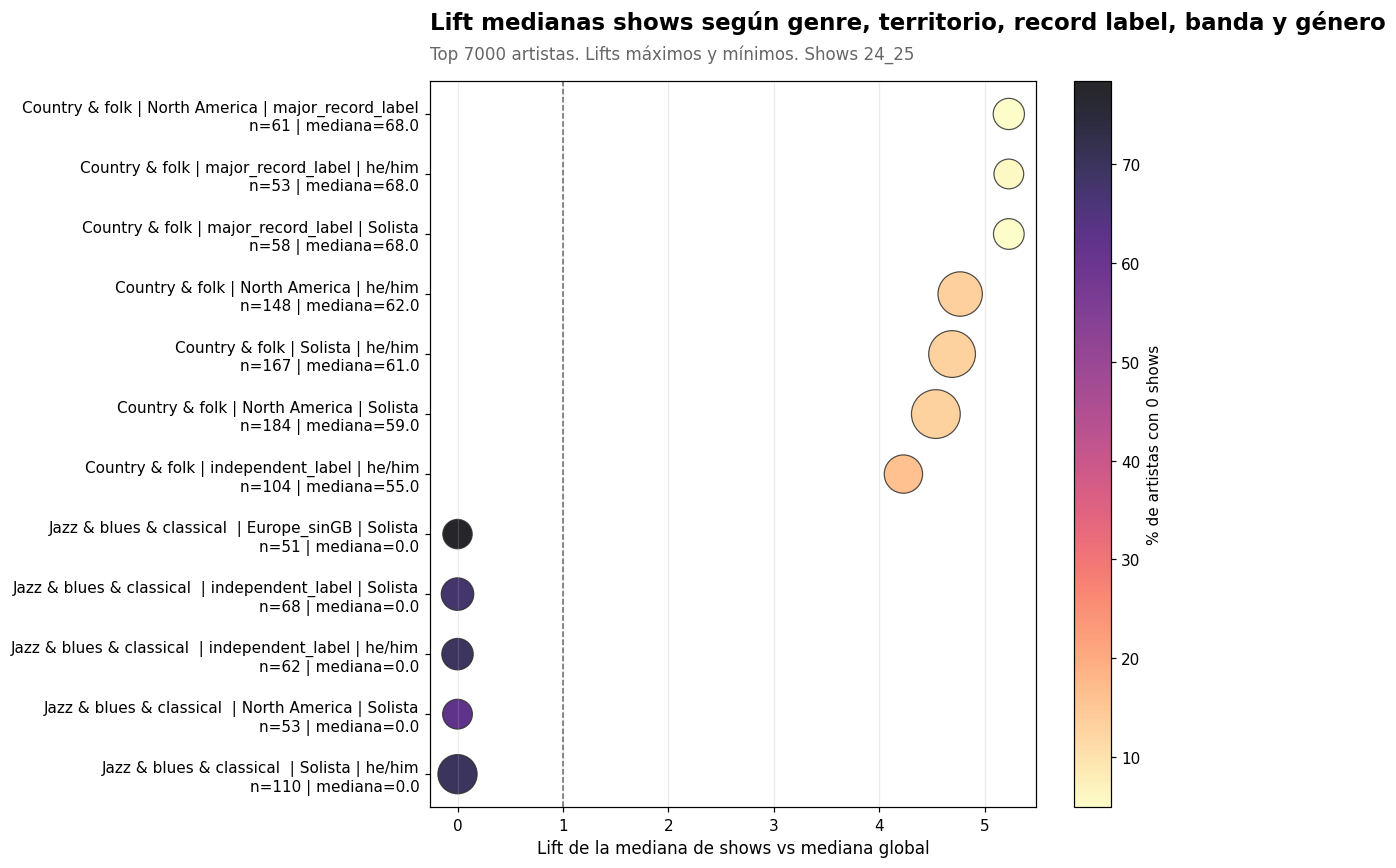

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\ranking_editorial_lifts_top_bottom_trios.png


In [32]:
# ============================================================
# Figura editorial de combinaciones categóricas top y bottom
# ============================================================

cantidad_top_combinaciones_grafico = 7
cantidad_bottom_combinaciones_grafico = 5

tabla_top_trios_para_grafico = tabla_trios_categoricos_vs_target.head(
    cantidad_top_combinaciones_grafico
).copy()

tabla_bottom_trios_para_grafico = (
    tabla_trios_categoricos_vs_target
    .sort_values(
        by=["lift_mediana_vs_global", "n_artistas"],
        ascending=[True, False]
    )
    .head(cantidad_bottom_combinaciones_grafico)
    .copy()
)

tabla_ranking_editorial_lifts = pd.concat(
    [
        tabla_top_trios_para_grafico.assign(tipo_hallazgo="Top lift"),
        tabla_bottom_trios_para_grafico.assign(tipo_hallazgo="Bottom lift")
    ],
    ignore_index=True
)


# ============================================================
# Etiquetas legibles según la variable categórica original
# ============================================================

def formatear_valor_categorico_para_grafico(nombre_variable, valor_variable):
    valor_como_texto = str(valor_variable)
    
    if nombre_variable == "major_record_label":
        if valor_variable is True or valor_como_texto == "True":
            return "major_record_label"
        elif valor_variable is False or valor_como_texto == "False":
            return "independent_label"
    
    if nombre_variable == "band":
        if valor_variable is True or valor_como_texto == "True":
            return "Band"
        elif valor_variable is False or valor_como_texto == "False":
            return "Solista"
    
    return valor_como_texto


def construir_etiqueta_combinacion_desde_columnas(fila):
    variables_de_la_combinacion = [
        variable.strip()
        for variable in fila["variables_combinadas"].split("+")
    ]
    
    valores_formateados = []
    
    for variable_actual in variables_de_la_combinacion:
        valor_actual = fila[variable_actual]
        
        valor_formateado = formatear_valor_categorico_para_grafico(
            nombre_variable=variable_actual,
            valor_variable=valor_actual
        )
        
        valores_formateados.append(valor_formateado)
    
    return " | ".join(valores_formateados)


tabla_ranking_editorial_lifts["combinacion_grafico"] = (
    tabla_ranking_editorial_lifts
    .apply(construir_etiqueta_combinacion_desde_columnas, axis=1)
)

tabla_ranking_editorial_lifts["etiqueta_grafico"] = (
    tabla_ranking_editorial_lifts["combinacion_grafico"]
    + "\n"
    + "n="
    + tabla_ranking_editorial_lifts["n_artistas"].astype(str)
    + " | mediana="
    + tabla_ranking_editorial_lifts["mediana_shows"].round(1).astype(str)
)

tabla_ranking_editorial_lifts = tabla_ranking_editorial_lifts.sort_values(
    by="lift_mediana_vs_global",
    ascending=True
).reset_index(drop=True)


# ============================================================
# Construcción del gráfico
# ============================================================

fig, ax = plt.subplots(figsize=(11, 8))

tamanios_puntos = (
    tabla_ranking_editorial_lifts["n_artistas"] /
    tabla_ranking_editorial_lifts["n_artistas"].max()
) * 900 + 120

scatter = ax.scatter(
    tabla_ranking_editorial_lifts["lift_mediana_vs_global"],
    tabla_ranking_editorial_lifts["etiqueta_grafico"],
    s=tamanios_puntos,
    c=tabla_ranking_editorial_lifts["pct_cero_shows"],
    cmap="magma_r",
    alpha=0.85,
    edgecolor="#2F2F2F",
    linewidth=0.8
)

ax.axvline(
    x=1,
    color="#2F2F2F",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

ax.set_title(
    'Lift medianas shows según genre, territorio, record label, banda y género',
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=34
)

ax.text(
    0,
    1.025,
    "Top 7000 artistas. Lifts máximos y mínimos. Shows 24_25",
    transform=ax.transAxes,
    fontsize=11,
    color="#666666",
    ha="left",
    va="bottom"
)

ax.set_xlabel("Lift de la mediana de shows vs mediana global", fontsize=11)
ax.set_ylabel("")

ax.grid(axis="x", alpha=0.25)

barra_color = plt.colorbar(scatter, ax=ax)
barra_color.set_label("% de artistas con 0 shows", fontsize=10)

plt.tight_layout()

ruta_grafico_ranking_editorial = (
    directorio_salidas_proyecto /
    "ranking_editorial_lifts_top_bottom_trios.png"
)

plt.savefig(
    ruta_grafico_ranking_editorial,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado en:", ruta_grafico_ranking_editorial)

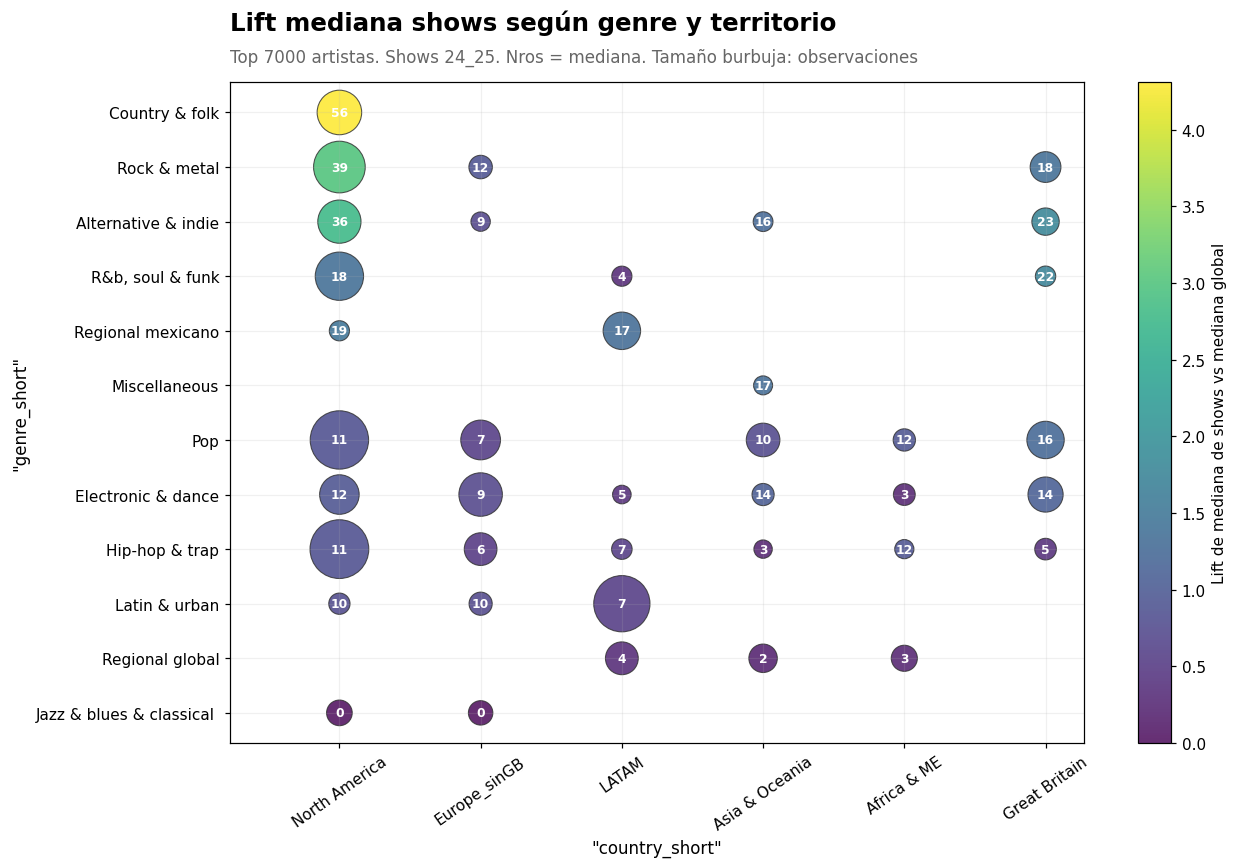

Gráfico guardado en: C:\Users\Silvana\Documents\Maestria_Exactas\taller_tesis_1\music_industry_social_live_code\graficos\bubble_heatmap_genre_short_country_short_lifts.png


In [31]:
# ============================================================
# Bubble heatmap de genre_short x country_short
# ============================================================

tabla_genero_region_lifts = tabla_pares_categoricos_vs_target[
    tabla_pares_categoricos_vs_target["variables_combinadas"] == "genre_short + country_short"
].copy()

orden_generos_por_lift_maximo = (
    tabla_genero_region_lifts
    .groupby("genre_short")["lift_mediana_vs_global"]
    .max()
    .sort_values(ascending=True)
    .index
    .tolist()
)

orden_regiones_por_lift_maximo = (
    tabla_genero_region_lifts
    .groupby("country_short")["lift_mediana_vs_global"]
    .max()
    .sort_values(ascending=False)
    .index
    .tolist()
)

tabla_genero_region_lifts["genre_short"] = pd.Categorical(
    tabla_genero_region_lifts["genre_short"],
    categories=orden_generos_por_lift_maximo,
    ordered=True
)

tabla_genero_region_lifts["country_short"] = pd.Categorical(
    tabla_genero_region_lifts["country_short"],
    categories=orden_regiones_por_lift_maximo,
    ordered=True
)

tabla_genero_region_lifts = tabla_genero_region_lifts.sort_values(
    by=["genre_short", "country_short"]
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 8))

tamanios_burbujas = (
    tabla_genero_region_lifts["n_artistas"] /
    tabla_genero_region_lifts["n_artistas"].max()
) * 1400 + 80

scatter = ax.scatter(
    tabla_genero_region_lifts["country_short"],
    tabla_genero_region_lifts["genre_short"],
    s=tamanios_burbujas,
    c=tabla_genero_region_lifts["lift_mediana_vs_global"],
    cmap="viridis",
    alpha=0.82,
    edgecolor="#2F2F2F",
    linewidth=0.7
)

for _, fila in tabla_genero_region_lifts.iterrows():
    ax.text(
        fila["country_short"],
        fila["genre_short"],
        f"{fila['mediana_shows']:.0f}",
        ha="center",
        va="center",
        fontsize=8,
        color="white",
        fontweight="bold"
    )

ax.axvline(
    x=-0.5,
    color="white",
    linewidth=0
)

ax.set_title(
    'Lift mediana shows según genre y territorio',
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=34
)

ax.text(
    0,
    1.025,
    "Top 7000 artistas. Shows 24_25. Nros = mediana. Tamaño burbuja: observaciones",
    transform=ax.transAxes,
    fontsize=11,
    color="#666666",
    ha="left",
    va="bottom"
)



ax.set_xlabel('"country_short"', fontsize=11)
ax.set_ylabel('"genre_short"', fontsize=11)

ax.tick_params(axis="x", rotation=35)
ax.grid(alpha=0.18)

barra_color = plt.colorbar(scatter, ax=ax)
barra_color.set_label("Lift de mediana de shows vs mediana global", fontsize=10)

plt.tight_layout()

ruta_grafico_bubble_heatmap_genero_region = (
    directorio_salidas_proyecto /
    "bubble_heatmap_genre_short_country_short_lifts.png"
)

plt.savefig(
    ruta_grafico_bubble_heatmap_genero_region,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico guardado en:", ruta_grafico_bubble_heatmap_genero_region)

In [21]:
# ============================================================
# Sanity check de tablas usadas en gráficos
# ============================================================

sanity_graficos_categoricos = pd.DataFrame({
    "grafico": [
        "ranking_editorial_top_bottom_trios",
        "bubble_heatmap_genre_short_country_short"
    ],
    "n_filas_usadas": [
        len(tabla_ranking_editorial_lifts),
        len(tabla_genero_region_lifts)
    ],
    "lift_minimo": [
        tabla_ranking_editorial_lifts["lift_mediana_vs_global"].min(),
        tabla_genero_region_lifts["lift_mediana_vs_global"].min()
    ],
    "lift_maximo": [
        tabla_ranking_editorial_lifts["lift_mediana_vs_global"].max(),
        tabla_genero_region_lifts["lift_mediana_vs_global"].max()
    ],
    "n_minimo_artistas": [
        tabla_ranking_editorial_lifts["n_artistas"].min(),
        tabla_genero_region_lifts["n_artistas"].min()
    ]
})

sanity_graficos_categoricos

,grafico,n_filas_usadas,lift_minimo,lift_maximo,n_minimo_artistas
0,ranking_editorial_top_bottom_trios,12,0.0,5.230769,51
1,bubble_heatmap_genre_short_country_short,39,0.0,4.307692,20


# Anexo B.1: sello discográfico por género y territorio
Celda autocontenida (lee `dataset_4913_53.csv`). Mediana de shows por tipo de sello en las combinaciones de género y territorio con al menos 20 artistas por sello.

In [ ]:
# ============================================================
# Anexo B.1 | Mediana de shows según sello discográfico dentro de
# cada combinación de género musical y territorio
# Base: 4.913 artistas con dato en n_shows_24_25
# Se muestran las combinaciones con al menos 20 artistas en cada tipo
# de sello (mismo umbral que el análisis de combinaciones de la Sección 3.1)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

directorio_salidas = Path("graficos")
directorio_salidas.mkdir(exist_ok=True)

color_texto = "#222222"
color_secundario = "#5F6368"
color_grilla = "#BDBDBD"
color_independiente = "#9A9A9A"
color_multinacional = "#222222"
color_conector = "#D9D9D9"
plt.rcParams["font.family"] = "DejaVu Sans"

minimo_por_celda = 20
etiquetas_territorio = {
    "North America": "Norteamérica", "LATAM": "LATAM", "Europe_sinGB": "Europa (sin GB)",
    "Great Britain": "Gran Bretaña", "Asia & Oceania": "Asia y Oceanía", "Africa & ME": "África y Medio Oriente",
}


def miles(n):
    """Entero con punto como separador de miles."""
    return f"{int(round(n)):,}".replace(",", ".")


def numero(x):
    """Mediana con coma decimal solo si no es entera."""
    return miles(x) if float(x).is_integer() else f"{x:.1f}".replace(".", ",")


base = pd.read_csv("dataset_4913_53.csv",
                   usecols=["genre_short", "country_short", "major_record_label", "n_shows_24_25"])
base["genero"] = base["genre_short"].str.strip()
base["territorio"] = base["country_short"].map(etiquetas_territorio)
mediana_global = base["n_shows_24_25"].median()

con_sello = base.dropna(subset=["territorio", "major_record_label"])
por_sello = (con_sello
             .groupby(["genero", "territorio", "major_record_label"])["n_shows_24_25"]
             .agg(n="size", mediana="median")
             .unstack("major_record_label"))
por_sello.columns = [f"{medida}_{'multinacional' if sello else 'independiente'}" for medida, sello in por_sello.columns]
por_par = (base.dropna(subset=["territorio"])
           .groupby(["genero", "territorio"])["n_shows_24_25"]
           .agg(n_total="size", mediana_total="median"))

tabla = (por_sello[(por_sello["n_independiente"] >= minimo_por_celda)
                   & (por_sello["n_multinacional"] >= minimo_por_celda)]
         .join(por_par)
         .sort_values(["mediana_total", "n_total"], ascending=[True, True])
         .reset_index())
print(f"Mediana global: {mediana_global:.0f} shows | combinaciones mostradas: {len(tabla)}")
display(tabla)

fig, ax = plt.subplots(figsize=(11, 0.32 * len(tabla) + 1.1))
y = np.arange(len(tabla))

ax.hlines(y, tabla[["mediana_independiente", "mediana_multinacional"]].min(axis=1),
          tabla[["mediana_independiente", "mediana_multinacional"]].max(axis=1),
          color=color_conector, linewidth=3.2, zorder=2)
ax.scatter(tabla["mediana_independiente"], y, s=70, color=color_independiente, zorder=3)
ax.scatter(tabla["mediana_multinacional"], y, s=70, color=color_multinacional, zorder=4)
ax.axvline(mediana_global, color=color_secundario, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
ax.text(mediana_global + 0.8, len(tabla) - 0.35, f"Mediana global ({miles(mediana_global)} shows)",
        fontsize=9.5, color=color_secundario, va="bottom", ha="left")

for i, fila in tabla.iterrows():
    tope = max(fila["mediana_independiente"], fila["mediana_multinacional"])
    ax.text(tope + 1.6, i, f"{numero(fila['mediana_independiente'])} → {numero(fila['mediana_multinacional'])}",
            va="center", ha="left", fontsize=9.5, color=color_texto, zorder=5,
            bbox=dict(boxstyle="square,pad=0.12", facecolor="white", edgecolor="none"))

ax.set_yticks(y)
ax.set_yticklabels([f"{g} · {t}  (n = {miles(n)})" for g, t, n in zip(tabla["genero"], tabla["territorio"], tabla["n_total"])],
                   fontsize=10, color=color_texto)
ax.set_ylim(-0.6, len(tabla) - 0.1)
ax.set_xlim(-1, tabla[["mediana_independiente", "mediana_multinacional"]].max().max() * 1.16)
ax.set_xlabel("Mediana de shows 2024–2025", fontsize=11, color=color_texto, labelpad=8)
ax.grid(axis="x", linestyle=(0, (1, 3)), color=color_grilla, linewidth=0.9, zorder=0)
for lado in ("top", "right", "left"):
    ax.spines[lado].set_visible(False)
ax.spines["bottom"].set_color(color_texto)
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=0, labelsize=10, colors=color_texto)

ax.legend(handles=[
    Line2D([0], [0], marker="o", color="none", markerfacecolor=color_independiente, markeredgecolor="none",
           markersize=9, label="Sello independiente u otro"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=color_multinacional, markeredgecolor="none",
           markersize=9, label="Sello multinacional"),
], loc="lower right", bbox_to_anchor=(1.0, 1.02), ncol=2, frameon=False, fontsize=10.5)

ruta = directorio_salidas / "anexo_b1_sello_por_genero_territorio.png"
fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Guardado en: {ruta}")